<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-09/lab-050-cellular-automaton-reservoir.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 050 <br>
<hr/>

# Lab 050 — Cellular automaton reservoir

A reservoir computer drives a fixed dynamical system with the measured signal and fits only a linear readout of its state by ridge regression [H. Jaeger, GMD Report 148 (2001), [pdf](https://www.ai.rug.nl/minds/uploads/EchoStatesTechRep.pdf); M. Lukoševičius, H. Jaeger, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)]. In an echo state network (ESN) this system is a random network of tanh units. Any driven nonlinear system that forgets its initial state and keeps a readable record of the recent input can take its place. A cellular automaton (CA) is such a system with discrete space, discrete time and a finite number of cell states.

We first define cellular automata, their rule tables and their classes of behaviour, and we look at linear rules and at the spreading of a local perturbation, the damage. Two short parts on the Game of Life and on a traffic model show that cellular automata are also physical models. We then build the CA reservoir of Yilmaz, reproduce his five-bit memory task, follow the encoding of a real-valued signal into the cells, and forecast the five benchmark signals with the protocol and the scores used for the ESN. A scan over the rule space tests the hypothesis that the best reservoirs sit at the edge of chaos, with Langton's parameter and with the spreading rate of the damage. A map over all 88 distinct elementary rules and the number of generation steps per input step shows which rules forecast well, and a shift register of quantised past values without automaton shows how much of the forecast comes from the transport of the input along the lattice. The notebook ends with the cost of the CA fit. Two exploration cells let the reader run elementary automata and a driven automaton with their own parameters.

The implementation uses JAX. Every automaton runs as one `jax.lax.scan` over time, and the ridge regressions are done in double precision.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The scan over the rule space, the forecast map of all elementary rules and the five-bit task take most of the run time. Their results are stored in a cache file, `ca_cache_lab050.json`, and a later run reads them from it. Without the cache file the notebook computes them again. On a multi-core CPU shared with other jobs a run that computed the earlier scans took 47 minutes, the forecast map of all elementary rules took another 24 minutes, and the recorded run, which read all of them from the cache, took 8.2 minutes.
> 2. `jax`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook. It is the data set A of the Santa Fe time-series competition, distributed with the notebooks on recurrent networks.
> 4. Two numbers files are optional. With `numbers_lab046.json`, written by the notebook on echo state networks, the ESN reference reuses the settings selected there, and without it this notebook repeats the ESN search, which takes about a minute. With `numbers_lab036.json`, written by the notebook on trained recurrent networks, the cost section also shows the trained networks. Upload them next to the notebook.
> 5. Run the cells in order. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-09/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # double precision by default; the automata use integers
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
Teal, CA_COL = "#2A9D8F", "#B8860B"            # CA_COL: colour of the CA reservoir in all figures
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "ESN": dict(color=UJBlue, ls="-"), "CA": dict(color=CA_COL, ls="-"),
         "MLP": dict(color="#7B4FA0", ls="-"), "RNN": dict(color=Teal, ls="-"),
         "GRU": dict(color="#8C564B", ls="-"), "LSTM": dict(color="#C44E52", ls="-")}
def model_legend(ax, models, **kw):
    # legend built from the line styles of STYLE, so that every swatch has the colour of its curve
    ax.legend([Line2D([], [], lw=1.6, **STYLE[m]) for m in models], models, **kw)

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

def find_file(name, *extra):
    # look next to the notebook first, then in the usual subfolders and in the given folders
    for d in ("", "data", "figures") + extra:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

# cache of the expensive scans: computed when absent or when its settings differ, read otherwise
CACHE_FILE = os.path.join("data", "ca_cache_lab050.json")
_cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}
def cached(key, settings, compute):
    if key in _cache and _cache[key]["settings"] == settings:
        print(f"{key}: read from the cache")
        return _cache[key]["value"]
    t0 = time.time(); value = compute()
    _cache[key] = dict(settings=settings, value=value)
    os.makedirs("data", exist_ok=True)
    with open(CACHE_FILE, "w") as fh:
        json.dump(_cache, fh)
    print(f"{key}: computed in {time.time() - t0:.0f} s and stored in the cache")
    return value

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | scikit-learn 1.6.1


<hr/>
## 1. Signals, protocol and reference models

The signals, the forecasting protocol, the scores and the reference models are the ones used for the ESN, and the code of this section repeats them so that the notebook runs on its own. It can be skimmed. The first coordinate $x$ of the Lorenz-63 system, $\dot x=10\,(y-x)$, $\dot y=x\,(28-z)-y$, $\dot z=xy-\tfrac83 z$, is integrated by the fourth-order Runge–Kutta method (RK4) and sampled every $\Delta t=0.02$. The Mackey–Glass delay equation
$$\dot s(t)=\frac{0.2\, s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-0.1\, s(t)$$
is sampled once per time unit for the delays $\tau_{\rm MG}=15$, 25 and 35, and the Santa Fe series (data set A) is the measured intensity of a far-infrared NH$_3$ laser. Every signal has 4000 samples and is rescaled to $[0,1]$ with the minimum and maximum of its first 3000 samples.

A forecast at the origin $k$ returns all horizons $\tau=1,\dots,50$ at once, with the target vector $\mathbf y_k=(s_{k+1},\dots,s_{k+50})$. Fitting uses the origins $k=63,\dots,2449$, validation the origins $k=2499,\dots,2949$ and testing the origins $k=2999,\dots,3949$. For each horizon the capacity $C(\tau)=r(\tau)^2$ is the squared Pearson coefficient between forecast and truth over the test origins, the total capacity $C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le50$ summarises a curve, and the skill horizon $\tau_{1/2}$ is the first horizon with $C(\tau)<0.5$. Every setting is chosen by the validation $C_{\rm tot}$. Persistence repeats the last value. The autoregressive (AR) model and the nonlinear vector autoregressive (NVAR) model with all quadratic products of the delay vector are ridge regressions on the delay vector $(s_k,\dots,s_{k-p+1})$ [D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. The ESN has $N=300$ tanh units, drawn with seed 0, at the spectral radius, input scaling, leak rate and ridge strength selected on validation data for each signal.

In [2]:
# Lorenz-63: x' = 10 (y - x), y' = x (28 - z) - y, z' = x y - 8/3 z; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u):
    x, y, z = u
    return jnp.array([10.0 * (y - x), x * (28.0 - z) - y, x * y - 8.0 / 3.0 * z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: ds/dt = 0.2 s(t-tau)/(1+s(t-tau)^10) - 0.1 s(t); RK4 with h=0.1, delayed value at half steps by
# linear interpolation, constant history 1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept.
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10):
    lag = int(round(tau / h))
    f = lambda x, xd: 0.2 * xd / (1.0 + xd**10) - 0.1 * x
    def step(buf, _):
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=transient + n_samples * every)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe():
    # Santa Fe laser data, set A: measured intensity of a far-infrared NH3 laser (next to the notebook first)
    path = find_file("santafe_laser.txt", "../../Lecture_8/Notebooks/data", "../../Lecture_7/Notebooks/data")
    if path is None:
        raise FileNotFoundError("santafe_laser.txt: upload the data file next to the notebook")
    return np.loadtxt(path).astype(float)

N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

raw = {"Lorenz": np.asarray(lorenz_trajectory(N_SAMPLES)[:, 0]),
       "MG15": mackey_glass(15, N_SAMPLES), "MG25": mackey_glass(25, N_SAMPLES),
       "MG35": mackey_glass(35, N_SAMPLES), "SantaFe": santafe()[:N_SAMPLES]}
SIGNALS = list(raw)
LABEL = {"Lorenz": "Lorenz-63", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$", "SantaFe": "Santa Fe laser"}
SHORT = {"Lorenz": "Lorenz-63", "MG15": "MG 15", "MG25": "MG 25", "MG35": "MG 35", "SantaFe": "Santa Fe"}
sig = {name: rescale01(x) for name, x in raw.items()}     # [0, 1] on the training block (first 3000 samples)

L_WIN = 64                                                        # longest delay window of the AR baseline
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)
def targets(s, ks):
    # rows Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    return s[ks[:, None] + TAUS[None, :]]

def r2_columns(pred, true):
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return (pc * tc).sum(0) ** 2 / ((pc ** 2).sum(0) * (tc ** 2).sum(0))

def score(pred, true):
    # C(tau) = r(tau)^2 over the rows, C_tot and the skill horizon tau_1/2
    C = r2_columns(np.asarray(pred, float), np.asarray(true, float))
    below = np.nonzero(C < 0.5)[0]
    return dict(C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = np.linalg.solve(Fc.T @ Fc + beta * np.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    return s[ks[:, None] - np.arange(p)[None, :]]
def nvar_features(s, ks, p):
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}
def timed(fn, n=5):
    # median wall time of n calls and the last result
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out

def ridge_model(s, kind):
    Yf, Yv, Yt = targets(s, K_FIT), targets(s, K_VAL), targets(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff = FEATS[kind](s, K_FIT, p)
    t_fit, (W, b) = timed(lambda: ridge_fit(Ff, Yf, beta))
    return dict(p=p, beta=beta, n_feat=Ff.shape[1], t_fit=t_fit, **score(FEATS[kind](s, K_TEST, p) @ W + b, Yt))

res = {name: {} for name in SIGNALS}
for name in SIGNALS:
    s = sig[name]
    res[name]["persistence"] = score(np.repeat(s[K_TEST][:, None], TAU_MAX, 1), targets(s, K_TEST))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    print(f"{name:8s} C_tot: " + " | ".join(f"{m} {res[name][m]['Ctot']:5.1f}" for m in ("persistence", "AR", "NVAR")))

Lorenz   C_tot: persistence   8.4 | AR  15.4 | NVAR  15.4


MG15     C_tot: persistence  19.5 | AR  49.8 | NVAR  50.0


MG25     C_tot: persistence  13.3 | AR  33.1 | NVAR  45.5


MG35     C_tot: persistence  11.8 | AR  38.0 | NVAR  48.6


SantaFe  C_tot: persistence   5.5 | AR  16.5 | NVAR  34.7


In [3]:
# ESN with N = 300 tanh units (seed 0); settings from the numbers file of the ESN notebook if present, else a new search
def esn_base(N, seed, density=0.1):
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(N, N)) * (rng.random((N, N)) < density)
    W /= np.max(np.abs(np.linalg.eigvals(W)))
    return W, rng.uniform(-1.0, 1.0, size=N)

@jax.jit
def esn_states(W, w_in, u, alpha, x0):
    # r_k = (1 - alpha) r_{k-1} + alpha tanh(W r_{k-1} + w_in s_k), returns all states (T, N)
    def step(x, uk):
        x = (1.0 - alpha) * x + alpha * jnp.tanh(W @ x + w_in * uk)
        return x, x
    _, X = jax.lax.scan(step, x0, u)
    return X

N_ESN = 300
W_esn, w_esn = esn_base(N_ESN, seed=0)
ESN_GRID = [(r, si, a) for r in (0.5, 0.8, 0.95, 1.1) for si in (0.1, 0.5, 1.0) for a in (0.3, 1.0)]
ESN_BETA = (1e-8, 1e-6, 1e-4, 1e-2)
def esn_run(s, r, si, a):
    return np.asarray(esn_states(r * W_esn, si * w_esn, s, a, jnp.zeros(N_ESN)))
def esn_search(s):
    Yf, Yv = targets(s, K_FIT), targets(s, K_VAL)
    best = (-1.0, None)
    for (r, si, a) in ESN_GRID:
        X = esn_run(s, r, si, a)
        for beta in ESN_BETA:
            W, b = ridge_fit(X[K_FIT], Yf, beta)
            v = score(X[K_VAL] @ W + b, Yv)["Ctot"]
            if v > best[0]:
                best = (v, (r, si, a, beta))
    return best[1]

p046 = find_file("numbers_lab046.json")
ref046 = json.load(open(p046)) if p046 else None
for name in SIGNALS:
    s = sig[name]
    if ref046:
        e = ref046["esn_choice"][name]; setting = (e["rho"], e["sigma_in"], e["alpha"], e["beta"])
    else:
        setting = esn_search(s)
    r, si, a, beta = setting
    def fit_esn():
        X = esn_run(s, r, si, a)
        return X, ridge_fit(X[K_FIT], targets(s, K_FIT), beta)
    t_fit, (X, (W, b)) = timed(fit_esn)
    res[name]["ESN"] = dict(setting=setting, t_fit=t_fit, **score(X[K_TEST] @ W + b, targets(s, K_TEST)))
    msg = f" | numbers file: {ref046['Ctot'][name]['ESN']:5.1f}" if ref046 else ""
    print(f"{name:8s} ESN C_tot = {res[name]['ESN']['Ctot']:5.1f} (rho, sigma_in, alpha, beta = {setting}){msg}")
print("ESN settings " + ("read from the numbers file of the ESN notebook" if ref046 else "selected by a new search"))
nums["esn_from_file"] = bool(ref046)

Lorenz   ESN C_tot =  39.2 (rho, sigma_in, alpha, beta = (1.1, 1.0, 1.0, 1e-08)) | numbers file:  39.2


MG15     ESN C_tot =  50.0 (rho, sigma_in, alpha, beta = (1.1, 0.5, 1.0, 1e-08)) | numbers file:  50.0


MG25     ESN C_tot =  48.3 (rho, sigma_in, alpha, beta = (0.95, 1.0, 0.3, 1e-08)) | numbers file:  48.3


MG35     ESN C_tot =  49.8 (rho, sigma_in, alpha, beta = (0.8, 1.0, 0.3, 1e-08)) | numbers file:  49.8


SantaFe  ESN C_tot =  34.7 (rho, sigma_in, alpha, beta = (0.95, 0.1, 1.0, 1e-08)) | numbers file:  34.7
ESN settings read from the numbers file of the ESN notebook


<hr/>
## 2. Cellular automata

A cellular automaton consists of a lattice, a set of cell states, a neighbourhood and a local rule.

1. A lattice of cells $j=0,1,\dots,L-1$, here a ring of $L$ cells with periodic boundary conditions, so that cell $L-1$ is the left neighbour of cell 0.
2. A finite set of cell states, here the integers modulo $q$, $\mathbb Z_q=\{0,1,\dots,q-1\}$, with $q=2$ for binary cells.
3. A neighbourhood of radius $a$, the $n=2a+1$ cells $j-a,\dots,j+a$.
4. A local rule $f:\mathbb Z_q^n\to\mathbb Z_q$ that returns the new state of a cell from the states of its neighbourhood.

The state of cell $j$ at iteration $i$ is $c_j^{(i)}$. The global map $F$ applies $f$ to all cells at once,
$$c_j^{(i)}=f\big(c_{j-a}^{(i-1)},\dots,c_{j+a}^{(i-1)}\big)\quad\text{for all }j,\qquad \mathbf c^{(i)}=F\big(\mathbf c^{(i-1)}\big),$$
and the evolution is the iteration of $F$ from an initial configuration $\mathbf c^{(0)}$. Space, time and states are discrete, and the update is deterministic and local.

### Elementary cellular automata

The elementary cellular automata have $q=2$ and $a=1$ [S. Wolfram, Rev. Mod. Phys. **55**, 601 (1983), [doi:10.1103/RevModPhys.55.601](https://doi.org/10.1103/RevModPhys.55.601)]. A neighbourhood $(c_{j-1},c_j,c_{j+1})$ is one of the $2^3=8$ patterns $111,110,\dots,000$, and a rule assigns an output bit to each. Writing the 8 output bits in this order gives a binary number between 0 and 255, the Wolfram rule number, so there are 256 elementary rules. The figure shows the tables of rules 90 and 30. Rule 90 returns $c_{j-1}\oplus c_{j+1}$, the exclusive or (XOR) of the two neighbours, and its output bits 01011010 form the number 90. Rule 30 returns $c_{j-1}\oplus(c_j\lor c_{j+1})$.

In [4]:
def eca_table(rule):
    # output bit for the 8 neighbourhoods (l, c, r) with index 4l + 2c + r: bit number index of the rule number
    return jnp.asarray((rule >> np.arange(8)) & 1, jnp.int32)

def linear_table(w, q):
    # table of the linear rule c_j <- (w_{-1} c_{j-1} + w_0 c_j + w_1 c_{j+1}) mod q, index q^2 l + q c + r
    l, c, r = np.meshgrid(np.arange(q), np.arange(q), np.arange(q), indexing="ij")
    return jnp.asarray(((w[0] * l + w[1] * c + w[2] * r) % q).ravel(), jnp.int32)

def ca_step(c, table, q=2):
    # one synchronous update of all cells, periodic boundary conditions (jnp.roll)
    return table[jnp.roll(c, 1) * q * q + c * q + jnp.roll(c, -1)]

@partial(jax.jit, static_argnums=(2, 3))
def ca_run(c0, table, q, n_steps):
    # space-time diagram: rows c^(0), c^(1), ..., c^(n_steps)
    def one(c, _):
        c = ca_step(c, table, q)
        return c, c
    return jnp.concatenate([c0[None], jax.lax.scan(one, c0, None, length=n_steps)[1]])

# rule 90 equals the linear rule (1, 0, 1) over Z_2, rule 150 the linear rule (1, 1, 1)
assert np.array_equal(eca_table(90), linear_table((1, 0, 1), 2))
assert np.array_equal(eca_table(150), linear_table((1, 1, 1), 2))
print("rule 90 table (patterns 111 ... 000):", np.asarray(eca_table(90))[::-1])

rule 90 table (patterns 111 ... 000): [0 1 0 1 1 0 1 0]


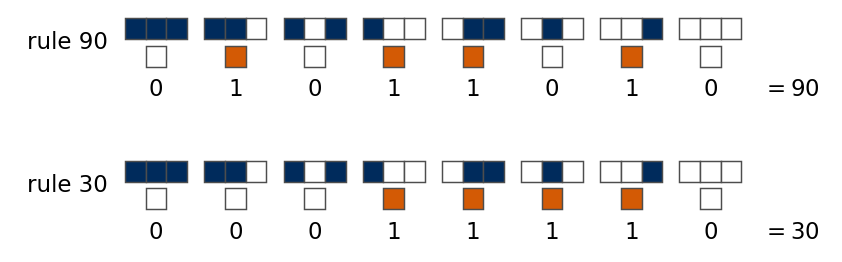

In [5]:
PATTERNS = [(n >> 2 & 1, n >> 1 & 1, n & 1) for n in range(7, -1, -1)]          # 111, 110, ..., 000
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 1.9), layout="constrained")
    for ax, rule in zip(axs, (90, 30)):
        tab = np.asarray(eca_table(rule))
        for i, p in enumerate(PATTERNS):
            x0 = 1.15 * i
            for j, bit in enumerate(p):
                ax.add_patch(plt.Rectangle((x0 + 0.3 * j, 0.45), 0.3, 0.3, fc=UJNavy if bit else "white", ec="0.3", lw=0.7))
            out = tab[4 * p[0] + 2 * p[1] + p[2]]
            ax.add_patch(plt.Rectangle((x0 + 0.3, 0.05), 0.3, 0.3, fc=DSOrange if out else "white", ec="0.3", lw=0.7))
            ax.text(x0 + 0.45, -0.12, str(out), ha="center", va="top")
        ax.text(-0.25, 0.4, f"rule {rule}", ha="right", va="center")
        ax.text(9.25, -0.12, rf"$={rule}$", ha="left", va="top")
        ax.set_xlim(-1.6, 10.2); ax.set_ylim(-0.5, 0.8); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab050_rule_table"); plt.show()

Wolfram sorted the behaviour of cellular automata from random initial states into four classes [S. Wolfram, Physica D **10**, 1 (1984), [doi:10.1016/0167-2789(84)90245-8](https://doi.org/10.1016/0167-2789(84)90245-8)]. Class I evolves to a homogeneous fixed state, class II to isolated stable or periodic structures, class III to aperiodic, random-looking patterns, and class IV to localised structures that move and interact over long times. The space-time diagrams show six rules with their class in brackets, iteration $i$ running downwards and black cells in state 1, from a single seed cell (top) and from a random configuration (bottom) on a ring of $L=101$ cells. Rule 32 empties every configuration within a few iterations, a number set by the longest alternating run 0101… of the start, which shrinks at both ends at every iteration. On 1000 random rings of 101 cells the lattice is empty after a median of 3 and at most 8 iterations. Rule 4 keeps isolated cells and nothing else. Rules 90 and 150 draw self-similar triangles from a single seed and random patterns from random starts, rule 30 grows a random-looking triangle, and rule 110 shows the moving localised structures of class IV.

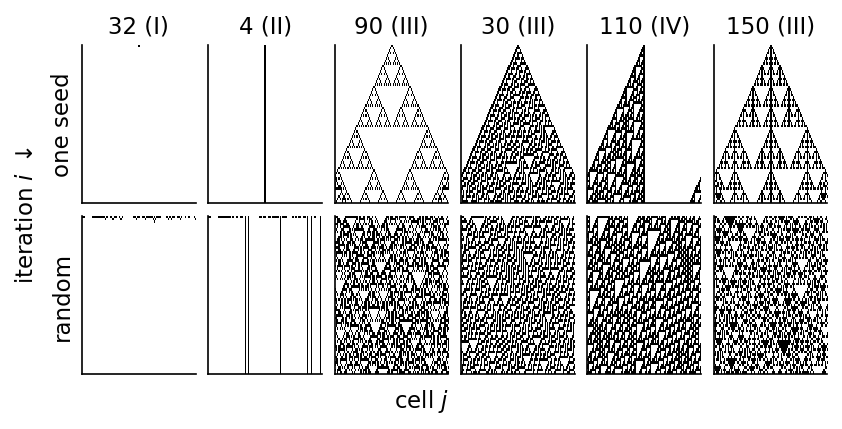

rule 32 on 1000 random rings of 101 cells: empty after a median of 3 and at most 8 iterations; correlation with the longest alternating run 0.93
  empty after 2 iterations:   72 rings, longest alternating run 4 to 5 cells
  empty after 3 iterations:  447 rings, longest alternating run 5 to 7 cells
  empty after 4 iterations:  327 rings, longest alternating run 7 to 9 cells
  empty after 5 iterations:  114 rings, longest alternating run 9 to 11 cells
  empty after 6 iterations:   31 rings, longest alternating run 11 to 13 cells
  empty after 7 iterations:    8 rings, longest alternating run 13 to 14 cells
  empty after 8 iterations:    1 rings, longest alternating run 15 to 15 cells


In [6]:
ST_RULES = [(32, "I"), (4, "II"), (90, "III"), (30, "III"), (110, "IV"), (150, "III")]
L_ST, T_ST = 101, 60
seed_state = jnp.zeros(L_ST, jnp.int32).at[L_ST // 2].set(1)
rand_state = jnp.asarray(np.random.default_rng(0).integers(0, 2, L_ST), jnp.int32)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 6, figsize=(5.5, 2.75), layout="constrained")
    for col, (rule, cls) in enumerate(ST_RULES):
        for row, c0 in enumerate((seed_state, rand_state)):
            axs[row, col].imshow(np.asarray(ca_run(c0, eca_table(rule), 2, T_ST)), cmap="Greys", interpolation="nearest", aspect="auto")
            axs[row, col].set_xticks([]); axs[row, col].set_yticks([])
        axs[0, col].set_title(f"{rule} ({cls})")
    axs[0, 0].set_ylabel("one seed"); axs[1, 0].set_ylabel("random")
    fig.supylabel(r"iteration $i$ $\downarrow$", fontsize=11); fig.supxlabel("cell $j$", fontsize=11)
    save(fig, "fig_lab050_spacetime"); plt.show()

# rule 32 (only 101 -> 1): iterations until a random ring of 101 cells is empty, and the longest alternating run 0101...
C32 = jnp.asarray(np.random.default_rng(3).integers(0, 2, (1000, L_ST)), jnp.int32)
S32 = np.asarray(jax.vmap(lambda c: ca_run(c, eca_table(32), 2, 50))(C32))          # (starts, 51, L)
t_erase = np.argmax(S32.sum(2) == 0, axis=1)                                          # first empty iteration
def longest_alternating(c):
    # longest run of cells in which neighbours alternate, on the ring
    a = np.r_[c != np.roll(c, -1)]; a = np.r_[a, a]; best = cur = 0
    for x in a:
        cur = cur + 1 if x else 0; best = max(best, cur)
    return min(best, len(c) - 1) + 1
alt_run = np.array([longest_alternating(c) for c in np.asarray(C32)])
nums["rule32_erase"] = dict(median=float(np.median(t_erase)), max=int(t_erase.max()), all_empty=bool((S32[:, -1].sum(1) == 0).all()),
                            corr_with_run=float(np.corrcoef(t_erase, alt_run)[0, 1]))
print(f"rule 32 on 1000 random rings of {L_ST} cells: empty after a median of {np.median(t_erase):.0f} and at most {t_erase.max()} iterations;"
      f" correlation with the longest alternating run {nums['rule32_erase']['corr_with_run']:.2f}")
for t_ in range(t_erase.min(), t_erase.max() + 1):
    sel = t_erase == t_
    if sel.any():
        print(f"  empty after {t_} iterations: {sel.sum():4d} rings, longest alternating run {alt_run[sel].min()} to {alt_run[sel].max()} cells")

The six rules fall into three kinds of long-time behaviour, which the next figure shows side by side on a ring of 81 cells over 60 iterations, from a single cell in state 1 (top) and from a random configuration (bottom). The code also measures, for the random start, the iteration after which the lattice repeats itself and the period of the repetition. Rule 32 is trivial. The single cell disappears at the first iteration, and the random configuration is empty from iteration 3 on, after which nothing changes. Rule 108 is regular. The single cell stays where it is, and the random configuration settles into vertical stripes, some fixed and some blinking, so that the whole lattice repeats with period 2 from iteration 2 on. Rule 30 is chaotic. The single cell grows into an irregular triangle, and the random configuration does not repeat within the 60 iterations. A change of a single cell spreads through the lattice under rule 30, as the damage-spreading figure further below shows, so that its long-time evolution can be known only by running it.

rule  32, single seed: live cells at i = 1, 10, 60: 0, 0, 0
rule  32, random start: periodic with period 1 from iteration 3 on, live cells at the end 0
rule   4, single seed: live cells at i = 1, 10, 60: 1, 1, 1
rule   4, random start: periodic with period 1 from iteration 1 on, live cells at the end 13


rule 108, single seed: live cells at i = 1, 10, 60: 1, 1, 1
rule 108, random start: periodic with period 2 from iteration 2 on, live cells at the end 29
rule  50, single seed: live cells at i = 1, 10, 60: 2, 11, 41
rule  50, random start: periodic with period 2 from iteration 2 on, live cells at the end 37
rule  30, single seed: live cells at i = 1, 10, 60: 3, 11, 47
rule  30, random start: not periodic within 60 iterations, live cells at the end 40


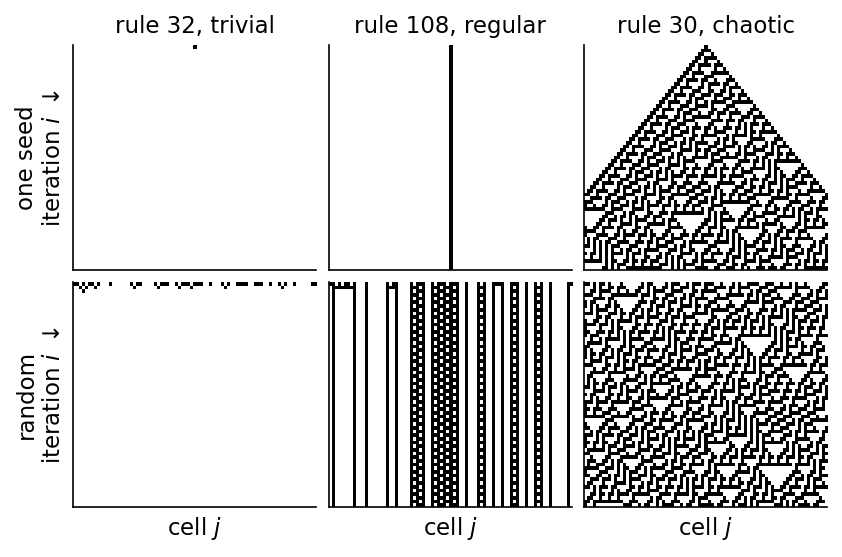

In [7]:
# three kinds of behaviour on a ring of 81 cells: a trivial, a regular and a chaotic rule
L_TB, T_TB = 81, 60
seed_tb = jnp.zeros(L_TB, jnp.int32).at[L_TB // 2].set(1)
rand_tb = jnp.asarray(np.random.default_rng(5).integers(0, 2, L_TB), jnp.int32)
def settle(S_):
    # first iteration t0 and period p with c^(t) = c^(t+p) for all t >= t0 within the run (None if not periodic yet)
    for t0_ in range(len(S_)):
        for p_ in range(1, (len(S_) - t0_) // 2 + 1):
            if all(np.array_equal(S_[t], S_[t + p_]) for t in range(t0_, len(S_) - p_)):
                return t0_, p_
    return None, None
nums["three_behaviours"] = {}
for r_ in (32, 4, 108, 50, 30):
    S_ = np.asarray(ca_run(rand_tb, eca_table(r_), 2, T_TB))
    t0_, p_ = settle(S_)
    S1_ = np.asarray(ca_run(seed_tb, eca_table(r_), 2, T_TB))
    nums["three_behaviours"][str(r_)] = dict(t_settle=t0_, period=p_, live_end=int(S_[-1].sum()),
                                             seed_live=[int(S1_[i].sum()) for i in (1, 10, T_TB)])
    print(f"rule {r_:3d}, single seed: live cells at i = 1, 10, {T_TB}: {S1_[1].sum()}, {S1_[10].sum()}, {S1_[-1].sum()}")
    print(f"rule {r_:3d}, random start: " + (f"periodic with period {p_} from iteration {t0_} on" if p_ else "not periodic within"
          f" {T_TB} iterations") + f", live cells at the end {S_[-1].sum()}")
TB_RULES = [(32, "trivial"), (108, "regular"), (30, "chaotic")]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), layout="constrained")
    for col, (r_, lab) in enumerate(TB_RULES):
        for row, c0 in enumerate((seed_tb, rand_tb)):
            axs[row, col].imshow(np.asarray(ca_run(c0, eca_table(r_), 2, T_TB)), cmap="Greys", vmin=0, vmax=1,
                                 interpolation="nearest", aspect="auto")
            axs[row, col].set_xticks([]); axs[row, col].set_yticks([])
        axs[0, col].set_title(f"rule {r_}, {lab}")
        axs[1, col].set_xlabel("cell $j$")
    axs[0, 0].set_ylabel("one seed\niteration $i$ $\\downarrow$"); axs[1, 0].set_ylabel("random\niteration $i$ $\\downarrow$")
    save(fig, "fig_lab050_three_behaviours"); plt.show()

The functions of the next cell let you run any elementary rule yourself. The function `run_elementary` iterates a rule on a ring with numpy and uses the convention of the rule table above, the new state of a cell being bit number $4c_{j-1}+2c_j+c_{j+1}$ of the rule number, and the cell checks that it reproduces the patterns of rules 90 and 30 computed with JAX. The function `plot_rules` draws a grid of space-time diagrams with one row per initial condition and one column per rule. An initial condition is written as a string of 0 and 1, and its length is the number of cells of the ring, so `"00000010000000"` is a ring of 14 cells with a single 1 in the middle. The words `"single"` and `"random"` give a single 1 in the middle or a random configuration on a ring of $L$ cells. Change the parameters at the top of the cell and run it again, for example to compare a rule with its mirror image or its complement, or to watch rule 90 erase a random configuration on a ring of 64 cells.

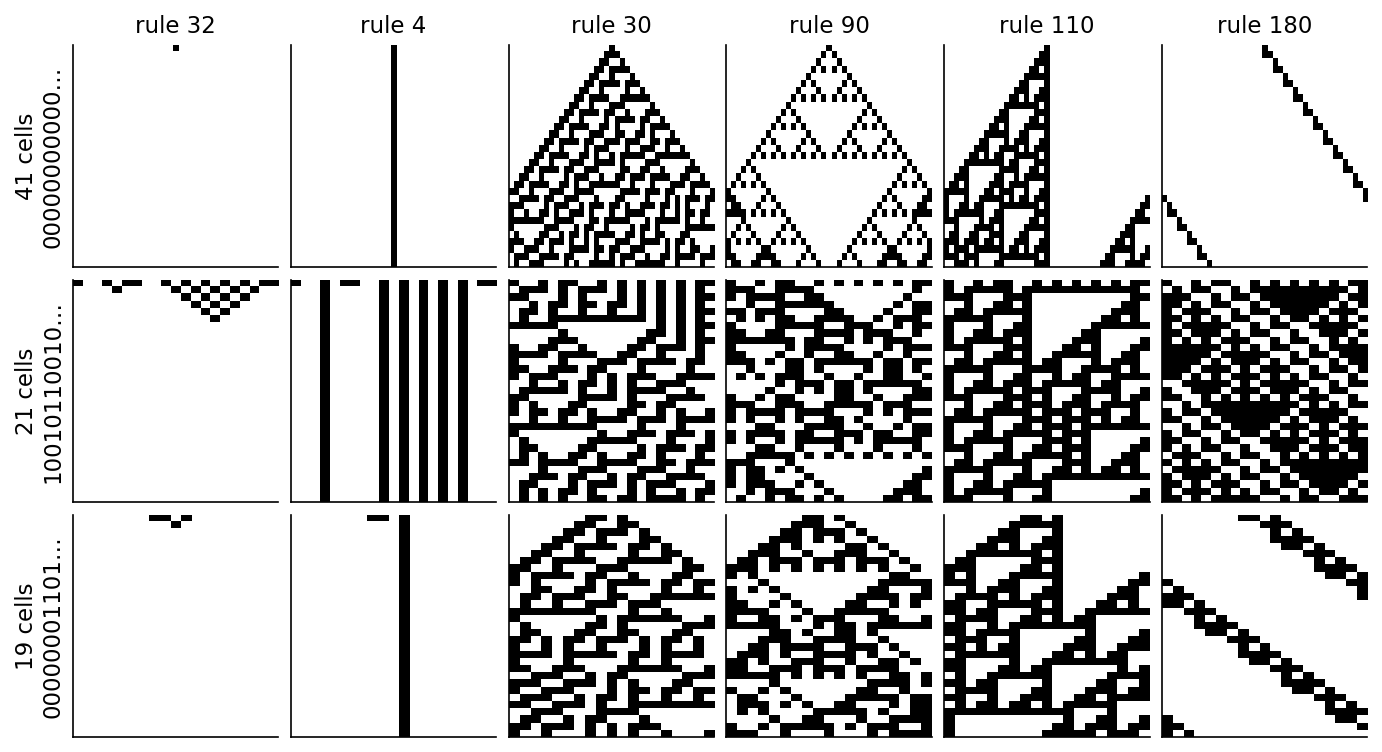

In [8]:
# ---------------- exploration cell: change the parameters below and run the cell again ----------------
rules = [32, 4, 30, 90, 110, 180]       # Wolfram rule numbers, 0 ... 255
initial = ["00000000000000000000100000000000000000000", "100101100101010101011", "0000000110100000000"]
# each string is one initial condition; its length is the number of cells of the ring
# "single" (one 1 in the middle of L cells) and "random" (L cells, each 1 with probability 0.5, drawn with seed) are also allowed
L = 81                                  # number of cells for "single" and "random"
generations = 30                        # number of iterations of the rule
seed = 0                                # random generator seed for "random"
# --------------------------------------------------------------------------------------------------------

def run_elementary(rule, initial, generations):
    # space-time array (generations + 1, number of cells) of an elementary rule on a ring; plain numpy, same rule-table
    # convention as eca_table: the new state of a cell is bit number 4 c_{j-1} + 2 c_j + c_{j+1} of the rule number
    c = np.asarray(initial, int); rows = [c]
    for _ in range(generations):
        c = (rule >> (4 * np.roll(c, 1) + 2 * c + np.roll(c, -1))) & 1
        rows.append(c)
    return np.array(rows)

def make_initial(entry, L=81, seed=0):
    # one initial condition: a bit string (its length is the ring size), "single" or "random" (L cells)
    if entry == "single":
        c0 = np.zeros(L, int); c0[L // 2] = 1
        return c0
    if entry == "random":
        return np.random.default_rng(seed).integers(0, 2, L)
    if not isinstance(entry, str) or set(entry) - {"0", "1"} or len(entry) < 3:
        raise ValueError(f"initial condition {entry!r}: use 'single', 'random' or a string of at least 3 characters 0 and 1")
    return np.array([int(ch) for ch in entry])

def plot_rules(rules, initial, L=81, generations=30, seed=0):
    # grid of space-time diagrams, one row per initial condition and one column per rule; iteration runs downwards,
    # black cells are in state 1, and the top row of every panel is the initial condition
    starts = [make_initial(e, L, seed) for e in initial]
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(len(starts), len(rules), figsize=(1.25 * len(rules) + 1.6, 1.5 * len(starts) + 0.4),
                                layout="constrained", squeeze=False)
        for row, (e, c0) in enumerate(zip(initial, starts)):
            for col, rule in enumerate(rules):
                ax = axs[row, col]
                ax.imshow(run_elementary(rule, c0, generations), cmap="Greys", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
                ax.set_xticks([]); ax.set_yticks([])
                if row == 0: ax.set_title(f"rule {rule}")
            text = e if len(e) <= 12 else e[:11] + "…"
            axs[row, 0].set_ylabel(f"{len(c0)} cells\n{text}")
        plt.show()

# check: the same patterns as the JAX implementation of the notebook for rules 90 and 30
for r_ in (90, 30):
    assert np.array_equal(run_elementary(r_, np.asarray(seed_tb), T_TB), np.asarray(ca_run(seed_tb, eca_table(r_), 2, T_TB)))
    assert np.array_equal(run_elementary(r_, np.asarray(rand_tb), T_TB), np.asarray(ca_run(rand_tb, eca_table(r_), 2, T_TB)))
plot_rules(rules, initial, L, generations, seed)

### Game of Life

This part and the traffic model of rule 184 below are optional reading. They show cellular automata as physical models and are not needed for the reservoir. The best-known two-dimensional automaton is Conway's Game of Life [M. Gardner, Sci. Am. **223** (4), 120 (1970), [doi:10.1038/scientificamerican1070-120](https://doi.org/10.1038/scientificamerican1070-120)]. Each cell of a square lattice is dead (0) or alive (1), and its neighbourhood is the Moore neighbourhood of the 8 surrounding cells. A dead cell with exactly three live neighbours becomes alive, a live cell with two or three live neighbours survives, and every other cell is dead in the next step. The neighbour count is a two-dimensional convolution with a $3\times3$ kernel of ones and a zero in the centre, which is how the JAX implementation computes it on a periodic grid. The snapshots show a glider, five live cells that return to their shape shifted by one cell diagonally after 4 steps, and a random soup of 0.352 live cells per site that leaves 0.042 after 200 steps, mostly in small still and oscillating objects.

glider after 4 steps equals the glider shifted by (1, 1): True
random soup: fraction of live cells 0.352 at t = 0, 0.042 at t = 200


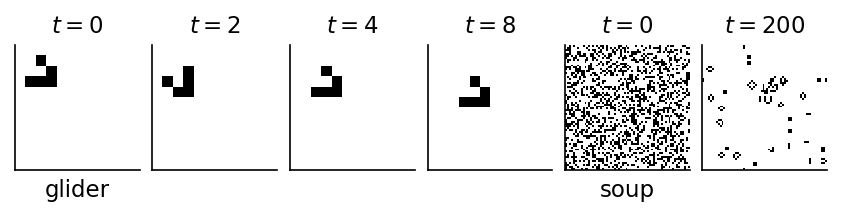

In [9]:
LIFE_K = jnp.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])

@partial(jax.jit, static_argnums=1)
def life_run(g0, n_steps):
    # Game of Life on a periodic grid: neighbour count by a 3x3 convolution, birth on 3, survival on 2 or 3
    def one(g, _):
        gp = jnp.pad(g, 1, mode="wrap")
        n = jax.scipy.signal.convolve2d(gp, LIFE_K, mode="valid")
        g = ((n == 3) | ((g == 1) & (n == 2))).astype(jnp.int32)
        return g, g
    return jnp.concatenate([g0[None], jax.lax.scan(one, g0, None, length=n_steps)[1]])

glider = jnp.zeros((12, 12), jnp.int32).at[jnp.array([1, 2, 3, 3, 3]), jnp.array([2, 3, 1, 2, 3])].set(1)
G_gl = np.asarray(life_run(glider, 8))
soup = jnp.asarray((np.random.default_rng(1).random((64, 64)) < 0.35).astype(np.int32))
G_soup = np.asarray(life_run(soup, 200))
print("glider after 4 steps equals the glider shifted by (1, 1):",
      np.array_equal(G_gl[4], np.roll(np.roll(G_gl[0], 1, 0), 1, 1)))
nums["life_alive"] = dict(t0=float(G_soup[0].mean()), t200=float(G_soup[200].mean()))
print(f"random soup: fraction of live cells {G_soup[0].mean():.3f} at t = 0, {G_soup[200].mean():.3f} at t = 200")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 6, figsize=(5.5, 1.35), layout="constrained")
    for ax, (G, t, lab) in zip(axs, [(G_gl, 0, "glider"), (G_gl, 2, ""), (G_gl, 4, ""), (G_gl, 8, ""),
                                       (G_soup, 0, "soup"), (G_soup, 200, "")]):
        ax.imshow(G[t], cmap="Greys", interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"$t={t}$")
        if lab: ax.set_xlabel(lab)
    save(fig, "fig_lab050_life"); plt.show()

### Linear cellular automata over $\mathbb Z_q$

A rule is linear when the new state is a weighted sum of the neighbourhood modulo $q$,
$$c_j^{(i)}=\sum_{l=-a}^{a}w_l\,c_{j+l}^{(i-1)}\bmod q,\qquad w_l\in\mathbb Z_q .$$
Rule 90 is the linear rule with $q=2$ and weights $(w_{-1},w_0,w_1)=(1,0,1)$, and rule 150 has $(1,1,1)$. For a linear rule the global map is a circulant matrix acting on $\mathbb Z_q^L$, and the superposition principle holds, $F(\mathbf c+\mathbf c')=F(\mathbf c)+F(\mathbf c')$ modulo $q$. Many properties of linear rules can be computed exactly from their weights, which is why they are used for reservoirs [J. Kantic, F. C. Legl, W. Stechele, J. Hermann, Complex Intell. Syst. **10**, 3593 (2024), [doi:10.1007/s40747-023-01330-x](https://doi.org/10.1007/s40747-023-01330-x), [arXiv:2308.11522](https://arxiv.org/abs/2308.11522)]. The figure shows rule 90 and two linear rules over $\mathbb Z_4$, from a single cell in state 1 and from a random configuration, with darker blue for larger states. The rule with weights $(0,2,1)$, $c_j\leftarrow2c_j+c_{j+1}\bmod4$, moves the content of every cell one site to the left per iteration and mixes it with its neighbour, a shift register with interaction. The rule $(1,2,1)$ spreads a seed in both directions.

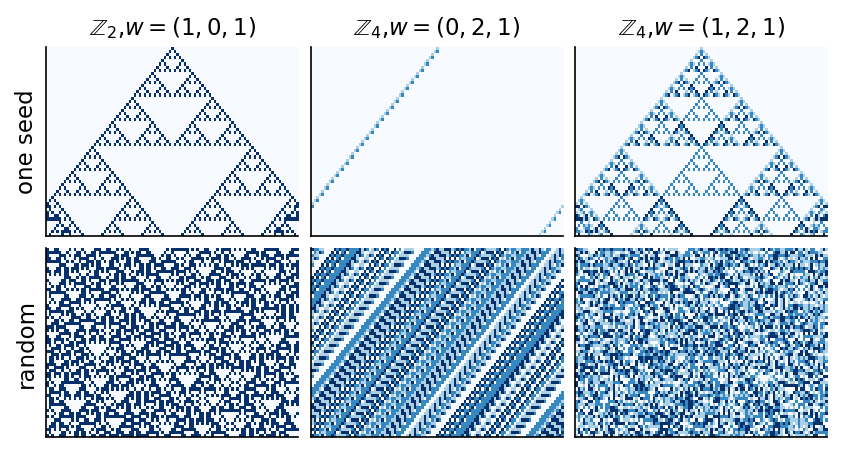

In [10]:
imp = jnp.zeros(L_ST, jnp.int32).at[L_ST // 2].set(1)
rnd4 = jnp.asarray(np.random.default_rng(0).integers(0, 4, L_ST), jnp.int32)
LIN_RULES = [((1, 0, 1), 2), ((0, 2, 1), 4), ((1, 2, 1), 4)]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 2.9), layout="constrained")
    for col, (w, q) in enumerate(LIN_RULES):
        for row, c0 in enumerate((imp, rnd4 % q)):
            axs[row, col].imshow(np.asarray(ca_run(c0, linear_table(w, q), q, T_ST)), cmap="Blues", vmin=0, vmax=q - 1,
                                 interpolation="nearest", aspect="auto")
            axs[row, col].set_xticks([]); axs[row, col].set_yticks([])
        axs[0, col].set_title(rf"$\mathbb{{Z}}_{q}$, $w={w}$".replace(" ", ""))
    axs[0, 0].set_ylabel("one seed"); axs[1, 0].set_ylabel("random")
    save(fig, "fig_lab050_linear"); plt.show()

### Traffic flow, rule 184

Rule 184 is the simplest model of traffic on a one-lane ring road, and like the Game of Life this part is optional reading. A cell in state 1 holds a car, and in every step a car moves one cell to the right if the cell ahead is empty and stays otherwise. A car never disappears and never appears, so the number of cars, and with it the car density $\eta$, is conserved by the dynamics. The flux $\Phi$ is the number of cars that move per cell and step. For $\eta<1/2$ every car eventually finds an empty cell ahead, all cars move and $\Phi=\eta$, the free-flow phase. For $\eta>1/2$ the empty cells are the minority, each of them lets one car through per step, and $\Phi=1-\eta$, the jammed phase. The fundamental diagram $\Phi(\eta)=\min(\eta,1-\eta)$ has a cusp at $\eta=1/2$, the transition between the two phases.

We start from random configurations of 1000 cells at densities $\eta=0.05,\dots,0.95$, discard 1000 steps and average the flux over the next 500. The measured flux agrees with $\min(\eta,1-\eta)$ to four decimals on this grid. The space-time diagrams on 100 cells show the free flow at $\eta=0.3$, where cars move to the right in parallel lines once the initial clusters have dissolved, and the jammed phase at $\eta=0.7$, where queues of standing cars travel to the left.

rule 184: max |Phi - min(eta, 1 - eta)| over the density grid = 0.0000


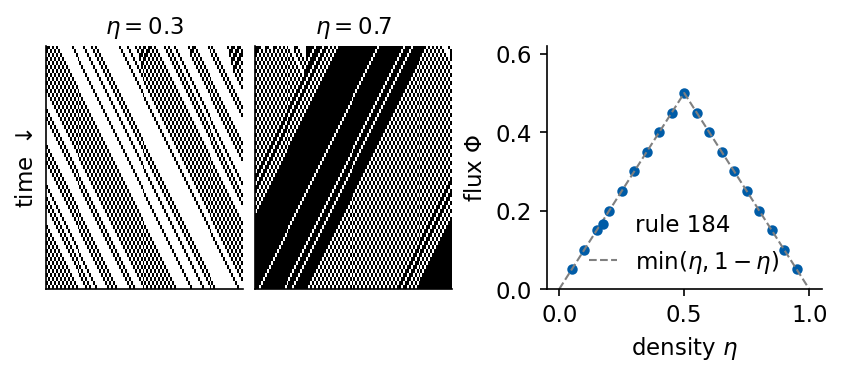

In [11]:
def traffic_flux(eta, L=1000, T_wash=1000, T_avg=500, seed=0):
    # rule 184: a car (1) moves one cell to the right if the cell ahead is empty; flux = moving cars per cell and step
    rng = np.random.default_rng(seed)
    c = np.zeros(L, np.int32); c[rng.choice(L, int(round(eta * L)), replace=False)] = 1
    S = np.asarray(ca_run(jnp.asarray(c), eca_table(184), 2, T_wash + T_avg))
    moving = S[T_wash:-1] * (1 - np.roll(S[T_wash:-1], -1, axis=1))
    return float(moving.mean()), S

ETA_TR = np.round(np.arange(0.05, 0.96, 0.05), 2)
flux = np.array([traffic_flux(e_)[0] for e_ in ETA_TR])
nums["rule184"] = dict(eta=ETA_TR.tolist(), flux=flux.tolist(),
                       max_dev_from_min=float(np.abs(flux - np.minimum(ETA_TR, 1 - ETA_TR)).max()))
print(f"rule 184: max |Phi - min(eta, 1 - eta)| over the density grid = {nums['rule184']['max_dev_from_min']:.4f}")
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.4), layout="constrained")
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.4])
    for col, e_ in enumerate((0.3, 0.7)):
        ax = fig.add_subplot(gs[col])
        S = traffic_flux(e_, L=100, T_wash=0, T_avg=60)[1]
        ax.imshow(S, cmap="Greys", interpolation="nearest", aspect="auto")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(rf"$\eta={e_}$")
        if col == 0: ax.set_ylabel(r"time $\downarrow$")
    ax = fig.add_subplot(gs[2])
    ax.plot(ETA_TR, flux, "o", ms=4, color=UJBlue, label="rule 184")
    ax.plot([0, 0.5, 1], [0, 0.5, 0], color="0.5", ls="--", lw=1.0, label=r"$\min(\eta,1-\eta)$")
    ax.set_xlabel(r"density $\eta$"); ax.set_ylabel(r"flux $\Phi$")
    ax.legend(loc="lower center", handlelength=1.2, borderaxespad=0.2)
    ax.set_ylim(0, 0.62)
    save(fig, "fig_lab050_rule184"); plt.show()

### Damage spreading

For a reservoir, two copies that start in different states and are driven by the same input should end up in the same state, the echo state property. Without input the related property of a cellular automaton is damage spreading. We flip one cell of a random configuration on a ring of $L=257$ cells and follow the set of cells where the two copies differ, the damage. The left panels show this difference pattern (orange) for one run over 64 iterations, and the right panel the damaged fraction of the lattice on a logarithmic scale, averaged over 20 random starts.

ring of 256 cells, random start: live cells after 256 iterations, rule 90: 0, rule 150: 133
ring of 257 cells, random start: live cells after 256 iterations, rule 90: 120, rule 150: 138


rule   4: damaged fraction at i = 32, 128: 0.002, 0.002; runs with damage left at i = 128: 0.50
rule  90: damaged fraction at i = 32, 128: 0.008, 0.008; runs with damage left at i = 128: 1.00
rule  30: damaged fraction at i = 32, 128: 0.085, 0.323; runs with damage left at i = 128: 1.00
rule 110: damaged fraction at i = 32, 128: 0.061, 0.158; runs with damage left at i = 128: 1.00


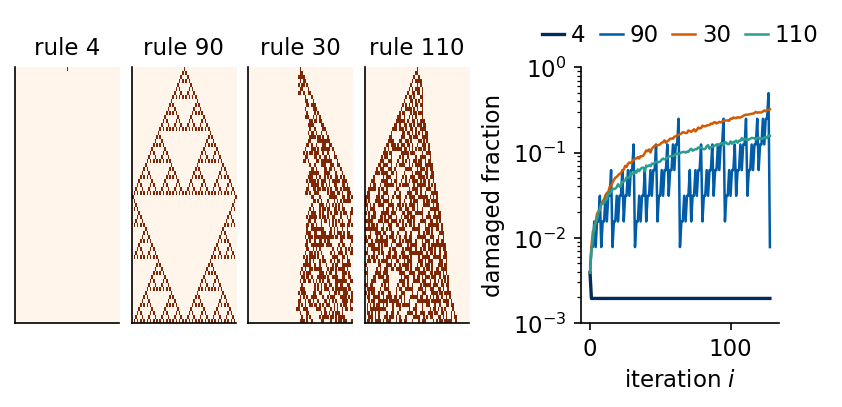

rule  30, after 100 iterations: right edge 1.00 and left edge 0.23 cells per iteration, drift of the mean position +0.38 per iteration, width 124.2 cells (largest 145), runs in which the damage vanished 0 of 20
rule 180, after 100 iterations: right edge 1.00 and left edge -0.98 cells per iteration, drift of the mean position +0.99 per iteration, width 2.9 cells (largest 9), runs in which the damage vanished 0 of 20
rule 210, after 100 iterations: right edge 1.00 and left edge -0.99 cells per iteration, drift of the mean position +1.00 per iteration, width 2.0 cells (largest 9), runs in which the damage vanished 0 of 20


In [12]:
def damage(rule, L=257, T=128, n_runs=20, seed=0):
    # cells that differ between two copies whose initial states differ in one cell, (runs, T+1, L)
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_runs):
        c0 = jnp.asarray(rng.integers(0, 2, L), jnp.int32)
        D = ca_run(c0, eca_table(rule), 2, T) ^ ca_run(c0.at[L // 2].set(1 - c0[L // 2]), eca_table(rule), 2, T)
        out.append(np.asarray(D))
    return np.array(out)

# rule 90 on a ring of 2^n cells sends every state to zero (nilpotent map); on 257 cells it does not
for L_ring in (256, 257):
    c_r = jnp.asarray(np.random.default_rng(2).integers(0, 2, L_ring), jnp.int32)
    alive = [int(np.asarray(ca_run(c_r, eca_table(rl), 2, 256))[-1].sum()) for rl in (90, 150)]
    nums.setdefault("ring_live_after_256", {})[str(L_ring)] = alive
    print(f"ring of {L_ring} cells, random start: live cells after 256 iterations, rule 90: {alive[0]}, rule 150: {alive[1]}")
DMG_RULES = (4, 90, 30, 110)
dmg = {r: damage(r) for r in DMG_RULES}
nums["damage_fraction_t128"] = {str(r): float(d[:, -1].mean()) for r, d in dmg.items()}
nums["damage_kept_t128"] = {str(r): float((d[:, -1].sum(1) > 0).mean()) for r, d in dmg.items()}
for r, d in dmg.items():
    print(f"rule {r:3d}: damaged fraction at i = 32, 128: {d[:, 32].mean():.3f}, {d[:, -1].mean():.3f};"
          f" runs with damage left at i = 128: {(d[:, -1].sum(1) > 0).mean():.2f}")
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.6), layout="constrained")
    gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 1.9])
    for col, r in enumerate(DMG_RULES):
        ax = fig.add_subplot(gs[col])
        ax.imshow(dmg[r][0][:64, 96:161], cmap="Oranges", interpolation="nearest", aspect="auto")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"rule {r}")
    ax = fig.add_subplot(gs[4])
    for r, col in zip(DMG_RULES, (UJNavy, UJBlue, DSOrange, Teal)):
        ax.semilogy(np.arange(129), dmg[r].mean(axis=(0, 2)), color=col, lw=1.6 if r == 4 else 1.2, label=f"{r}")
    ax.set_xlabel("iteration $i$"); ax.set_ylabel("damaged fraction"); ax.set_ylim(1e-3, 1)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), handlelength=1.0, ncol=4, columnspacing=0.6, handletextpad=0.3)
    save(fig, "fig_lab050_damage"); plt.show()

def damage_edges(d, i_max=100):
    # right edge, left edge, mean position and width of the damage at iteration i_max, relative to the flipped cell
    c = d.shape[2] // 2; out = []
    for run in d:
        idx = np.nonzero(run[i_max])[0] - c
        if len(idx):
            out.append((idx.max(), -idx.min(), idx.mean(), idx.max() - idx.min() + 1))
    return np.array(out, float), len(d) - len(out)
ITER_EDGE = 100
nums["damage_edges"] = {}
for r_ in (30, 180, 210):
    d_ = dmg[r_] if r_ in dmg else damage(r_)
    E, n_dead = damage_edges(d_, ITER_EDGE)
    nums["damage_edges"][str(r_)] = dict(right=float(E[:, 0].mean() / ITER_EDGE), left=float(E[:, 1].mean() / ITER_EDGE),
                                         drift=float(E[:, 2].mean() / ITER_EDGE), width=float(E[:, 3].mean()),
                                         width_max=float(E[:, 3].max()), runs_without_damage=int(n_dead))
    e_ = nums["damage_edges"][str(r_)]
    print(f"rule {r_:3d}, after {ITER_EDGE} iterations: right edge {e_['right']:.2f} and left edge {e_['left']:.2f} cells per iteration,"
          f" drift of the mean position {e_['drift']:+.2f} per iteration, width {e_['width']:.1f} cells (largest {e_['width_max']:.0f}),"
          f" runs in which the damage vanished {n_dead} of {len(d_)}")

Under rule 4 the damage stays on one cell, a fraction of 0.002 after 128 iterations. Under rule 90 the difference of two configurations evolves by rule 90 itself, because the rule is linear over $\mathbb Z_2$, so the damage is the Sierpinski triangle of the single seed for every background, and the damaged fraction oscillates with the self-similar pattern, 0.008 after 128 iterations. Under rule 30 the damage fills an asymmetric cone. Over the first 100 iterations its right edge moves by 1.00 cell per iteration and its left edge by 0.23 cells per iteration, since the exclusive or with the left neighbour passes every difference on to the right, and the damaged fraction reaches 0.323 of the lattice after 128 iterations. Under rule 110 it reaches 0.158. The width of the damaged region grows linearly in time for rules 90, 30 and 110, the cellular automaton counterpart of a positive Lyapunov exponent, while rule 4 keeps a perturbation where it was.

For a reservoir this has a consequence. On the ring of 257 cells a flipped cell is still visible after 128 iterations in 100% of the 20 runs under rules 90, 30 and 110, which spread it, and in 50% of the runs under rule 4, which keeps every isolated cell in state 1, so the difference survives when the flip creates or removes such a cell. Without input nothing removes such a difference. This damage test has no input, so it is not a test of the echo state property. In a CA reservoir the initial state can be forgotten only through the input, which overwrites the mapped cells at every step, and we test this with two copies of the forecasting reservoir driven by the same input further below. A second effect matters for linear rules on rings. Rule 90 on a ring of $2^n$ cells sends every configuration to zero, while on 257 cells it does not. From a random start, after 256 iterations rule 90 leaves 0 live cells on 256 cells and 120 on 257 cells, and rule 150 leaves 133 and 138. On a ring whose size is a power of two rule 90 erases all information, which matters for the size of the reservoir lattice.

Langton related the computational ability of cellular automata to the transition between ordered and chaotic rules, the edge of chaos [C. G. Langton, Physica D **42**, 12 (1990), [doi:10.1016/0167-2789(90)90064-V](https://doi.org/10.1016/0167-2789(90)90064-V)], and the first CA reservoirs were motivated by it. We treat this as a hypothesis and test it with the forecasting reservoirs further on.

<hr/>
## 3. Cellular automaton reservoir

Yilmaz replaced the echo state network by a cellular automaton [O. Yilmaz, arXiv:1410.0162 (2014), [arXiv:1410.0162](https://arxiv.org/abs/1410.0162)]. The input is written into cells of the automaton, the rule is iterated a fixed number of times $N_{\rm gen}$, and the configurations of all iterations, the space-time volume of the evolution, are concatenated into the feature vector of a linear readout. Several random mappings of the input onto the lattice, $R$ of them, are used side by side. For a time series the lattice state is carried over from one input step to the next, so the automaton accumulates the history. Kantic *et al.* split one step of this scheme into separate stages [Kantic *et al.*, Complex Intell. Syst. **10**, 3593 (2024)], which we follow.

1. Quantisation. The value $s_k\in[0,1]$ is mapped to one of $Q$ levels $\ell_k=\lfloor Q s_k\rfloor$, clipped to $0,\dots,Q-1$.
2. Code. The level is written as a code word $\mathbf e_k$ of $B$ digits in base $q$, $Q=q^B$, in Gray code or in plain binary.
3. Mapping. The ring of $L=RL_c$ cells is divided into $R$ compartments of $L_c$ cells. In each compartment $B$ cells are chosen at random once, and they receive the $B$ digits of $\mathbf e_k$ at every step.
4. Encoding. The digits are written into the lattice state $\mathbf c^{(N_{\rm gen})}_{k-1}$ left by the previous step, by replacement or by addition modulo $q$ (XOR for $q=2$). The other cells keep their content.
5. Evolution. The rule is iterated $N_{\rm gen}$ times, the number of generation steps per input step, $\mathbf c_k^{(i)}=F(\mathbf c_k^{(i-1)})$, starting from the encoded state $\mathbf c_k^{(0)}$.
6. Readout. The reservoir state is $\mathbf r_k=(\mathbf c_k^{(0)},\dots,\mathbf c_k^{(N_{\rm gen})})\in\mathbb Z_q^{(N_{\rm gen}+1)L}$, read as real numbers, and the forecast is $\hat{\mathbf y}_k=W_{\rm out}^\top\mathbf r_k+\mathbf b$ with $W_{\rm out}$ from ridge regression.

The schematic shows one step for rule 90 with three compartments of six cells, a code word of two bits, replacement encoding and $N_{\rm gen}=3$. The injected cells are framed in orange. Kantic *et al.* write a single value of $\mathbb Z_q$ into one cell per compartment, so their number of levels equals $q$. Writing $B$ digits per compartment is our extension, which allows more levels than cell states.

The sketch follows two consecutive input steps through these stages on a small ring with rule 180, $Q=8$ levels, Gray code words of $B=3$ bits, $R=3$ compartments of $L_c=5$ cells and $N_{\rm gen}=3$ generation steps. Each sample becomes a level and a code word, the code word overwrites the same three input cells (orange frames) in every compartment, and the rule moves and combines the bits over three generations. The $N_{\rm gen}+1$ rows of one step form its feature vector $\mathbf r_k$ of $L(N_{\rm gen}+1)$ bits for the linear readout. The last generation of step $k$ is the configuration into which the code word of step $k+1$ is written, so only the framed cells change at that moment and the other cells carry what earlier inputs left behind.

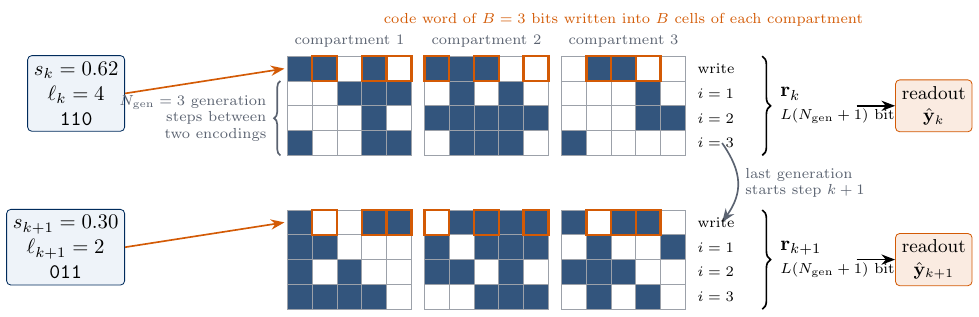


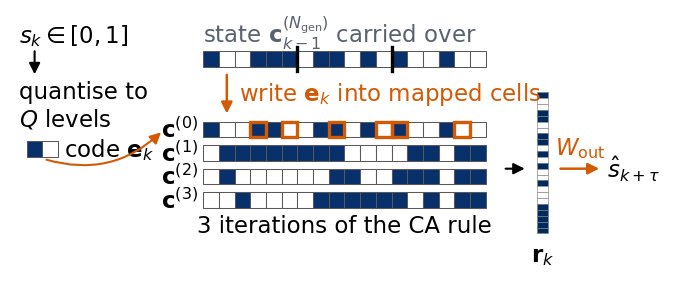

In [13]:
def draw_row(ax, x0, y0, row, size=0.22, q=2, hi=None, ec="0.35"):
    # one lattice configuration as a row of squares; cells in `hi` get an orange edge (injected cells)
    for j, v in enumerate(row):
        fc = plt.cm.Blues(0.15 + 0.85 * v / (q - 1)) if v else "white"
        ax.add_patch(plt.Rectangle((x0 + j * size, y0), size, size, fc=fc, ec=ec, lw=0.5))
    for j in (hi if hi is not None else []):
        ax.add_patch(plt.Rectangle((x0 + j * size, y0), size, size, fc="none", ec=DSOrange, lw=1.6, zorder=4))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.75))
    rng = np.random.default_rng(4)
    R_d, Lc_d, B_d, ngen_d = 3, 6, 2, 3
    L_d = R_d * Lc_d; sz = 0.2
    cells_d = np.concatenate([j * Lc_d + np.sort(rng.choice(Lc_d, B_d, replace=False)) for j in range(R_d)])
    prev = rng.integers(0, 2, L_d)
    code = np.array([1, 0])                                     # code word of the quantised input
    inj = prev.copy(); inj[cells_d] = np.tile(code, R_d)        # replacement encoding
    evol = np.asarray(ca_run(jnp.asarray(inj, jnp.int32), eca_table(90), 2, ngen_d))
    # input, quantisation and code word
    ax.text(0.0, 2.75, r"$s_k\in[0,1]$", ha="left", va="center")
    ax.annotate("", xy=(0.2, 2.2), xytext=(0.2, 2.6), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.0))
    ax.text(0.0, 1.85, "quantise to\n$Q$ levels", ha="left", va="center")
    draw_row(ax, 0.1, 1.2, code, size=sz)
    ax.text(0.1 + B_d * sz + 0.08, 1.3, r"code $\mathbf{e}_k$", ha="left", va="center")
    # previous state, compartments and injection
    X0, Y_PREV, Y0 = 2.35, 2.35, 1.45
    ax.text(X0, 2.78, r"state $\mathbf{c}_{k-1}^{(N_{\rm gen})}$ carried over", ha="left", va="center", color=UJGray)
    draw_row(ax, X0, Y_PREV, prev, size=sz)
    for j in range(1, R_d):
        ax.plot([X0 + j * Lc_d * sz] * 2, [Y_PREV - 0.05, Y_PREV + sz + 0.05], color="k", lw=1.6)
    ax.annotate("", xy=(X0 + 0.3, Y0 + sz + 0.05), xytext=(X0 + 0.3, Y_PREV - 0.05),
                arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=1.2))
    ax.text(X0 + 0.45, (Y0 + sz + Y_PREV) / 2, r"write $\mathbf{e}_k$ into mapped cells", color=DSOrange, ha="left", va="center")
    ax.annotate("", xy=(X0 - 0.5, Y0 + sz / 2), xytext=(0.1 + B_d * sz / 2, 1.18),
                arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=1.0, connectionstyle="arc3,rad=0.3"))
    # CA iterations
    for i in range(ngen_d + 1):
        y = Y0 - i * sz * 1.5
        draw_row(ax, X0, y, evol[i], size=sz, hi=cells_d if i == 0 else None)
        ax.text(X0 - 0.06, y + sz / 2, rf"$\mathbf{{c}}^{{({i})}}$", ha="right", va="center")
    ax.text(X0 + L_d * sz / 2, Y0 - ngen_d * sz * 1.5 - 0.08, f"{ngen_d} iterations of the CA rule", ha="center", va="top")
    # reservoir state and readout
    X1 = X0 + L_d * sz + 0.2
    ax.annotate("", xy=(X1 + 0.35, 1.05), xytext=(X1, 1.05), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.0))
    feat = evol.ravel()
    for i, v in enumerate(feat[:24]):
        ax.add_patch(plt.Rectangle((X1 + 0.45, 1.95 - i * 0.075), 0.15, 0.075, fc=UJNavy if v else "white", ec="0.5", lw=0.3))
    ax.text(X1 + 0.525, 1.95 - 24 * 0.075 - 0.06, r"$\mathbf{r}_k$", ha="center", va="top")
    ax.annotate("", xy=(X1 + 1.3, 1.05), xytext=(X1 + 0.7, 1.05), arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=1.2))
    ax.text(X1 + 1.0, 1.15, r"$W_{\rm out}$", color=DSOrange, ha="center", va="bottom")
    ax.text(X1 + 1.35, 1.05, r"$\hat s_{k+\tau}$", ha="left", va="center")
    ax.set_xlim(-0.05, X1 + 1.95); ax.set_ylim(-0.2, 2.95); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab050_scheme"); plt.show()

Quantisation is the price of a discrete state. With $Q$ levels of width $1/Q$ the rounding error of a uniformly spread value has the standard deviation $1/(Q\sqrt{12})$, and on the Santa Fe signal the measured root-mean-square error is 0.069 for $Q=4$, 0.018 for $Q=16$ and 0.0045 for $Q=64$. The left panel shows the signal $s_k$ and its quantised values $(\ell_k+1/2)/Q$ for $Q=4$ and $16$. The right panels show the code words of the levels $\ell=0,\dots,7$ as rows of three bits (grey for 1). In the Gray code neighbouring levels differ in exactly one bit, so a small change of the signal flips one cell, while in binary code the step from level 3 to level 4 flips all three.

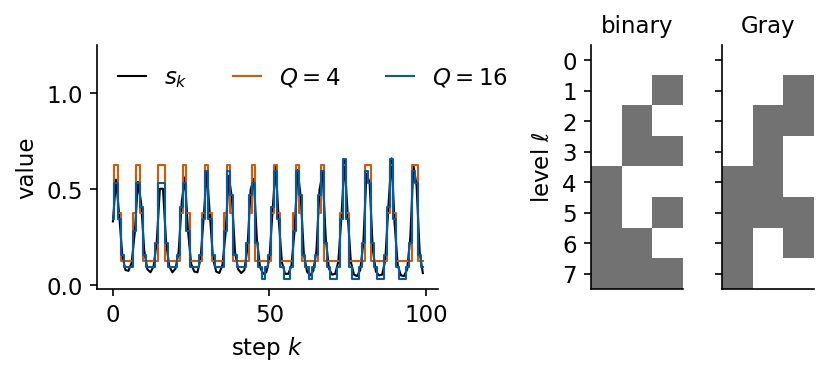

rms quantisation error on Santa Fe: Q = 4: 0.0690 (1/(Q sqrt 12) = 0.0722), Q = 16: 0.0180 (1/(Q sqrt 12) = 0.0180), Q = 64: 0.0045 (1/(Q sqrt 12) = 0.0045)


In [14]:
def gray(l):
    return l ^ (l >> 1)

def quantise(s, Q):
    # levels l = 0..Q-1 of equal width 1/Q on [0, 1]; values outside [0, 1] go to the end levels
    return np.clip(np.floor(s * Q), 0, Q - 1).astype(int)

seg = sig["SantaFe"][:100]
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.4), layout="constrained")
    gs = fig.add_gridspec(1, 3, width_ratios=[2.3, 0.8, 0.8])
    ax = fig.add_subplot(gs[0])
    ax.plot(np.arange(100), seg, color="k", lw=1.0, label="$s_k$")
    for Q, c in ((4, DSOrange), (16, UJBlue)):
        ax.step(np.arange(100), (quantise(seg, Q) + 0.5) / Q, where="mid", color=c, lw=1.0, label=f"$Q={Q}$")
    ax.set_xlabel("step $k$"); ax.set_ylabel("value"); ax.legend(loc="upper left", ncol=3, handlelength=1.2)
    ax.set_ylim(-0.02, 1.25)
    for col, (name, f) in enumerate((("binary", lambda l: l), ("Gray", gray))):
        axc = fig.add_subplot(gs[1 + col])
        Mb = np.array([[(f(l) >> b) & 1 for b in range(2, -1, -1)] for l in range(8)])
        axc.imshow(Mb, cmap="Greys", vmin=0, vmax=1.6, interpolation="nearest")
        axc.set_xticks([]); axc.set_yticks(range(8)); axc.set_title(name)
        if col == 0: axc.set_ylabel(r"level $\ell$")
        else: axc.set_yticklabels([])
    save(fig, "fig_lab050_encoding"); plt.show()
q_err = {Q: float(np.sqrt(np.mean(((quantise(sig["SantaFe"], Q) + 0.5) / Q - sig["SantaFe"]) ** 2))) for Q in (4, 16, 64)}
nums["quant_rms_SantaFe"] = q_err
print("rms quantisation error on Santa Fe: " + ", ".join(f"Q = {Q}: {v:.4f} (1/(Q sqrt 12) = {1 / (Q * np.sqrt(12)):.4f})"
                                                       for Q, v in q_err.items()))

The JAX implementation runs the whole record as one `jax.lax.scan`. A step writes the code digits into the mapped cells, applies the rule $N_{\rm gen}$ times through a lookup table indexed by the neighbourhood, and returns the concatenated configurations. The reservoir state has integer entries between 0 and $q-1$, so the matrix $X^\top X$ of the readout is computed exactly in single precision, and the solve is done in double precision.

In [15]:
@partial(jax.jit, static_argnums=(3, 4, 5, 6, 7))
def ca_reservoir(table, digits, cells, q, L, N_generation_steps, additive, with_input):
    # digits: (T, B) input code per step; cells: (R, B) lattice cells that receive the B digits in each compartment.
    # Per step: write the digits (replacement, or addition mod q), run N_gen iterations, return the concatenated states.
    def step(c, d):
        vals = jnp.broadcast_to(d, cells.shape)
        c = c.at[cells].set((c[cells] + vals) % q if additive else vals)
        outs = [c] if with_input else []
        for _ in range(N_generation_steps):
            c = ca_step(c, table, q)
            outs.append(c)
        return c, jnp.concatenate(outs)
    return jax.lax.scan(step, jnp.zeros(L, jnp.int32), digits)[1]

def compartment_cells(R, Lc, B, seed):
    # one fixed random choice of B distinct cells in each of the R compartments of Lc cells
    rng = np.random.default_rng(seed)
    return jnp.asarray(np.stack([j * Lc + rng.choice(Lc, B, replace=False) for j in range(R)]), jnp.int32)

def ridge_int(X, Y, betas):
    # centred ridge regression for integer-valued features; X^T X in float32 is exact for these counts
    n = X.shape[0]; fm = X.mean(0, dtype=np.float64); ym = Y.mean(0)
    G = (X.T @ X).astype(np.float64) - n * np.outer(fm, fm)
    XtY = X.T.astype(np.float64) @ Y - n * np.outer(fm, ym)
    out = []
    for beta in betas:
        W = np.linalg.solve(G + beta * np.eye(G.shape[0]), XtY)
        out.append((beta, W, ym - fm @ W))
    return out

The next cell lets you drive an elementary automaton with a piece of a real signal and look at the result. Each sample $s_k$ is quantised to $Q=2^B$ levels and written as $B$ bits, in Gray or binary code, into $B$ cells of every compartment, by replacement or by addition modulo 2, and the rule is then iterated $N_{\rm gen}$ times. The left panel shows the signal and its quantised values against the input step, and the right panel the ring after the bits are written and after each of the $N_{\rm gen}$ iterations, with the input steps separated by thin grey lines, the compartments by blue lines, and the injected cells in orange, dark for a 1 and light for a 0. The cell runs the same reservoir twice, once from a ring of zeros and once from a hand-written random-looking ring, and prints the input step from which the two runs agree. The number of bits sets a trade-off that the parameters let you explore. More bits give a finer amplitude, with a rounding error of $1/(2^B\sqrt{12})$ for a uniformly spread signal, but they overwrite $B$ of the $L_c$ cells of each compartment at every step, which leaves fewer cells to carry the past. In Gray code a small change of $s_k$ that crosses one level boundary flips a single bit, while in binary code it can flip all of them.

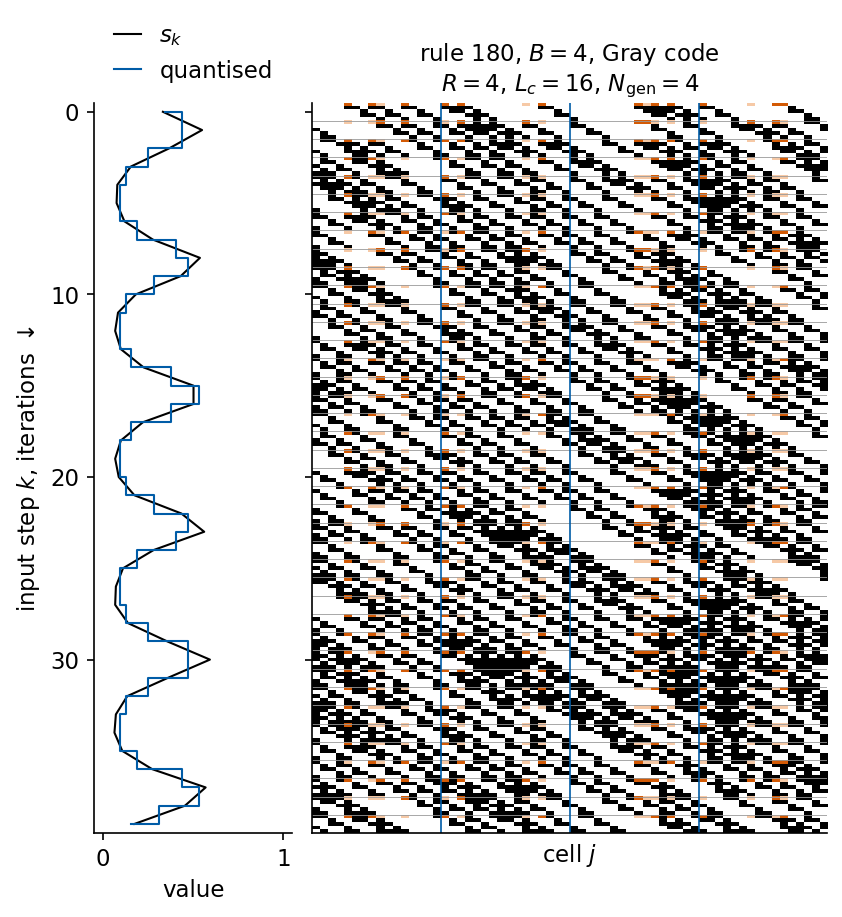

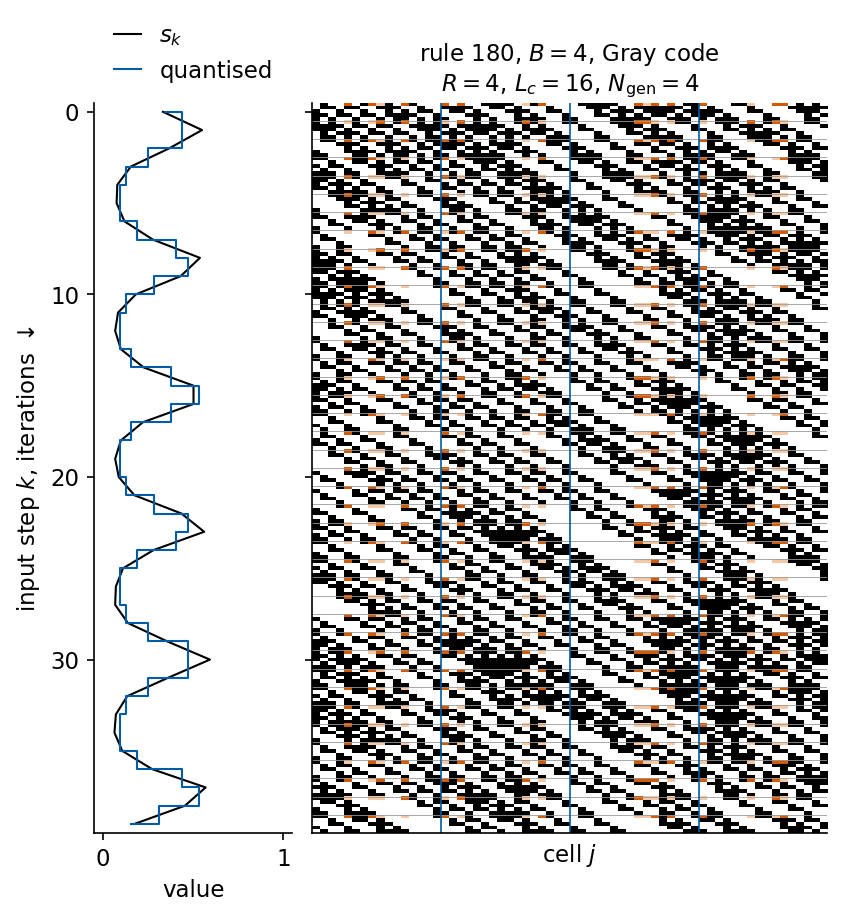

the two runs agree from input step 12 on (steps counted from 0, 40 steps)


In [16]:
# ---------------- exploration cell: a CA reservoir driven by a signal; change the parameters and run again ----------------
signal = sig["SantaFe"][:40]            # the input s_k, values in [0, 1]
B = 4                                   # bits per sample, Q = 2**B levels
code = "gray"                           # "gray" or "binary"
rule = 180                              # Wolfram rule number
R = 4                                   # number of compartments
N_generation_steps = 4                                   # iterations of the rule per input step
mode = "replace"                        # "replace": the bits overwrite the input cells; "xor": they are added modulo 2
initial = "0" * 64                      # initial is the starting ring as a bit string; its length is the number of cells
                                        # "zeros" or "random" give a ring of R * L_c cells
L_c = 16                                # cells per compartment for initial = "zeros" or "random"
input_cells = None                      # None: B random cells per compartment (drawn with seed);
                                        # or a list of B positions 0 ... L_c - 1, used in every compartment
seed = 0                                # seed of the random input cells and of initial = "random"
# ----------------------------------------------------------------------------------------------------------------------------

def encode(s, B, code="gray"):
    # bit string of one sample, most significant bit first: level l = floor(Q s) clipped to 0 ... Q - 1, then Gray or binary code
    l = int(quantise(np.array([s]), 2 ** B)[0])
    return format(gray(l) if code == "gray" else l, f"0{B}b")

def run_driven(signal, rule, B=4, code="gray", R=4, N_generation_steps=4, mode="replace", initial="zeros", L_c=16, input_cells=None, seed=0):
    # space-time array (len(signal) * (N_gen + 1), L): for every input step the ring right after the bits are written
    # and its N_gen iterations; also the positions (R, B) of the input cells, digit b of the code in column b
    if initial in ("zeros", "random"):
        c = np.zeros(R * L_c, int) if initial == "zeros" else np.random.default_rng(seed).integers(0, 2, R * L_c)
    else:
        if set(initial) - {"0", "1"}:
            raise ValueError("initial must be 'zeros', 'random' or a string of the characters 0 and 1")
        c = np.array([int(ch) for ch in initial])
        if len(c) % R:
            raise ValueError(f"the ring of {len(c)} cells cannot be divided into R = {R} compartments")
        L_c = len(c) // R
    if L_c < B:
        raise ValueError(f"a compartment of L_c = {L_c} cells cannot hold B = {B} input bits")
    if input_cells is None:
        cells = np.asarray(compartment_cells(R, L_c, B, seed))           # the same random choice as the CA reservoir
    else:
        if len(input_cells) != B or len(set(input_cells)) != B or not all(0 <= x < L_c for x in input_cells):
            raise ValueError(f"input_cells needs B = {B} distinct positions between 0 and {L_c - 1}")
        cells = np.array([[j * L_c + x for x in input_cells] for j in range(R)])
    rows = []
    for s in signal:
        d = np.array([int(ch) for ch in encode(s, B, code)[::-1]])      # least significant bit first, as in the CA reservoir
        c = c.copy()
        c[cells] = d[None, :] if mode == "replace" else (c[cells] + d[None, :]) % 2
        rows.append(c)
        for _ in range(N_generation_steps):
            c = (rule >> (4 * np.roll(c, 1) + 2 * c + np.roll(c, -1))) & 1
            rows.append(c)
    return np.array(rows), cells

def plot_driven(signal, ST, cells, B, code, rule, R, N_generation_steps):
    # left: signal and quantised values against the input step; right: the driven ring, injected cells in orange
    L_ = ST.shape[1]; n_ = len(signal)
    img = np.ones(ST.shape + (3,)) * (1 - ST[..., None])                 # white for 0, black for 1
    inj = np.zeros(ST.shape, bool); inj[::N_generation_steps + 1][:, cells.ravel()] = True # rows where the bits are written
    img[inj & (ST == 1)] = mpl.colors.to_rgb(DSOrange); img[inj & (ST == 0)] = mpl.colors.to_rgb("#F6C9A6")
    y_step = np.arange(n_) * (N_generation_steps + 1) + N_generation_steps / 2                             # centre of each input step on the row axis
    with mpl.rc_context(SLIDE_RC):
        fig, (a0, a1) = plt.subplots(1, 2, figsize=(5.5, 6.0), sharey=True, layout="constrained", gridspec_kw={"width_ratios": [1, 2.6]})
        a0.plot(signal, y_step, color="k", lw=1.0, label="$s_k$")
        a0.step((quantise(signal, 2 ** B) + 0.5) / 2 ** B, y_step, where="mid", color=UJBlue, lw=1.0, label="quantised")
        a0.set_xlim(-0.05, 1.05); a0.set_xlabel("value"); a0.set_ylabel(r"input step $k$, iterations $\downarrow$")
        a0.set_yticks(y_step[::10], [str(k) for k in range(0, n_, 10)])
        a0.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), handlelength=1.2)
        a1.imshow(img, interpolation="nearest", aspect="auto")
        for k in range(1, n_):
            a1.axhline(k * (N_generation_steps + 1) - 0.5, color="0.6", lw=0.4)
        for j in range(1, R):
            a1.axvline(j * L_ // R - 0.5, color=UJBlue, lw=0.8)
        a1.set_xticks([]); a1.set_xlabel("cell $j$")
        a1.set_title(f"rule {rule}, $B={B}$, {'Gray' if code == 'gray' else 'binary'} code\n$R={R}$, $L_c={L_ // R}$, $N_{{\\rm gen}}={N_generation_steps}$")
        plt.show()

# checks: encoding as in the notebook, and the same features as the CA reservoir (replacement, zero start, same cells)
digits_ref = np.stack([(gray(quantise(signal, 16)) >> b) & 1 for b in range(4)], 1)    # Gray-code digits, least significant first
assert all(encode(s, 4)[::-1] == "".join(map(str, row)) for s, row in zip(signal, digits_ref))
ST_chk, cells_chk = run_driven(signal, 180, 4, "gray", 4, 4, "replace", "zeros", 16, None, 0)
X_chk = np.asarray(ca_reservoir(eca_table(180), jnp.asarray(digits_ref, jnp.int32), jnp.asarray(cells_chk, jnp.int32), 2, 64, 4, False, True))
assert np.array_equal(ST_chk.reshape(len(signal), -1), X_chk)

ST_a, cells_a = run_driven(signal, rule, B, code, R, N_generation_steps, mode, initial, L_c, input_cells, seed)
plot_driven(signal, ST_a, cells_a, B, code, rule, R, N_generation_steps)
# a second start, a hand-written random-looking ring of the same size, driven by the same signal
initial_b = "0100001111001000100001111001100001111100001010111000110000001010"
ST_b, _ = run_driven(signal, rule, B, code, R, N_generation_steps, mode, initial_b, L_c, input_cells, seed)
plot_driven(signal, ST_b, cells_a, B, code, rule, R, N_generation_steps)
end_a, end_b = ST_a[N_generation_steps::N_generation_steps + 1], ST_b[N_generation_steps::N_generation_steps + 1]                           # ring at the end of every input step
differ = np.nonzero((end_a != end_b).any(1))[0]
if len(differ) == 0:
    print("the two runs agree from the first input step on")
elif differ[-1] < len(signal) - 1:
    print(f"the two runs agree from input step {differ[-1] + 1} on (steps counted from 0, {len(signal)} steps)")
else:
    print(f"the two runs still differ after the last of the {len(signal)} input steps, in {(end_a[-1] != end_b[-1]).sum()} cells")

### Five-bit memory task

The five-bit memory task tests whether a system can store a short binary pattern over a long distractor period [H. Jaeger, Jacobs University Technical Report 27 (2012), [pdf](https://www.ai.rug.nl/minds/uploads/2478_Jaeger12.pdf)]. There are four binary input channels and four output channels, and at every step exactly one input channel is 1. During the first 5 steps channel 1 or channel 2 carries one bit of the pattern, so there are $2^5=32$ possible sequences. Then the distractor channel 3 is on for $T_0-1$ steps, a cue appears on channel 4 at step $T_0+5$, and in the last 5 steps the outputs on channels 1 and 2 must repeat the pattern. Before the recall the output channel 3 must be 1. A run succeeds if every output at every step is within 0.5 of its target, and a trial succeeds if all 32 sequences succeed. Training and testing use the same 32 sequences, as in the original task.

Yilmaz solved this task with elementary rules and reported the percentage of failed trials on a grid of $R$ and $N_{\rm gen}$. His paper does not state how each new input is combined with the lattice state or how many cells a mapping occupies. We follow the implementation described by Nichele and Molund [S. Nichele, A. Molund, arXiv:1703.02806 (2017), [arXiv:1703.02806](https://arxiv.org/abs/1703.02806)]. Each of the $R$ mappings places the 4 input bits on random cells of a compartment of $L_c=40$ cells, the compartments form one ring of $L=RL_c$ cells, the input overwrites its cells in the last state, and the features are the $N_{\rm gen}$ configurations after the injection, $RN_{\rm gen}L_c$ binary values. The readout is a ridge regression with $\beta=10^{-6}$, close to the pseudo-inverse used by Yilmaz. We use $T_0=200$ and 10 trials per grid point, each with its own random mapping, so a percentage moves in steps of 10. The grid of $R$ and $N_{\rm gen}$ from 1 to 8 is limited by the size of the ridge regression, which grows as $(RN_{\rm gen}L_c)^2$.

In [17]:
def five_bit_data(T0):
    # all 32 input sequences of the 5-bit memory task: 4 one-hot input channels, 4 target channels, length T0 + 10
    T = T0 + 10
    U = np.zeros((32, T, 4), np.int32); Y = np.zeros((32, T, 4))
    for p in range(32):
        bits = (p >> np.arange(5)) & 1
        U[p, np.arange(5), bits] = 1                 # pattern on channel 1 or 2 during the first 5 steps
        U[p, 5:T0 + 4, 2] = 1                        # distractor
        U[p, T0 + 4, 3] = 1                          # cue
        U[p, T0 + 5:, 2] = 1                         # distractor during the recall
        Y[p, :T0 + 5, 2] = 1                         # "waiting" output
        Y[p, np.arange(T0 + 5, T), bits] = 1         # recall of the pattern
    return U, Y

def five_bit_trial(rule, R, N_generation_steps, Lc, seed, U, Y, beta=1e-6):
    # one trial = one random mapping; trained and tested on all 32 sequences; success if every output is within 0.5
    cells = compartment_cells(R, Lc, 4, seed)
    X = jax.vmap(lambda u: ca_reservoir(eca_table(rule), u, cells, 2, R * Lc, N_generation_steps, False, False))(jnp.asarray(U))
    X = np.asarray(X.reshape(-1, X.shape[-1]), np.float32); Yf = Y.reshape(-1, 4)
    (_, W, b), = ridge_int(X, Yf, (beta,))
    return bool(np.all(np.abs(X.astype(np.float64) @ W + b - Yf) < 0.5))

T0_5BIT, LC_5BIT, N_TRIALS = 200, 40, 10
U5, Y5 = five_bit_data(T0_5BIT)
RNGEN_GRID = (1, 2, 4, 8)
def failed_percent(rule, R, N_generation_steps, Lc, n_trials):
    return 100 * (1 - np.mean([five_bit_trial(rule, R, N_generation_steps, Lc, sd, U5, Y5) for sd in range(n_trials)]))
fail5 = cached("five_bit_grid", dict(T0=T0_5BIT, Lc=LC_5BIT, trials=N_TRIALS, grid=list(RNGEN_GRID), rules=[90, 150]),
               lambda: {str(rule): [[failed_percent(rule, R, N_generation_steps, LC_5BIT, N_TRIALS) for R in RNGEN_GRID] for N_generation_steps in RNGEN_GRID]
                        for rule in (90, 150)})
fail5 = {int(k): np.array(v) for k, v in fail5.items()}
for rule in (90, 150):
    print(f"rule {rule}: percent failed trials (rows N_gen = {RNGEN_GRID}, columns R = {RNGEN_GRID})\n{np.round(fail5[rule])}")
fail_small = cached("five_bit_small", dict(T0=T0_5BIT, Lc=4, R=32, N_generation_steps=16, trials=N_TRIALS),
                    lambda: {str(rule): failed_percent(rule, 32, 16, 4, N_TRIALS) for rule in (90, 150)})
fail_small = {int(k): v for k, v in fail_small.items()}
print(f"mappings of 4 cells, R = 32, N_gen = 16: failed trials {fail_small}")
nums["five_bit"] = dict(T0=T0_5BIT, Lc=LC_5BIT, trials=N_TRIALS, grid=list(RNGEN_GRID),
                        failed={str(k): v.tolist() for k, v in fail5.items()}, failed_Lc4_R32_I16=fail_small)

five_bit_grid: read from the cache
rule 90: percent failed trials (rows N_gen = (1, 2, 4, 8), columns R = (1, 2, 4, 8))
[[100. 100. 100.  80.]
 [100.  90.  90.  70.]
 [100. 100.  70.  20.]
 [100. 100.  10.   0.]]
rule 150: percent failed trials (rows N_gen = (1, 2, 4, 8), columns R = (1, 2, 4, 8))
[[100. 100. 100.  80.]
 [100. 100. 100.  90.]
 [100. 100. 100. 100.]
 [100.  90.  90.  20.]]
five_bit_small: read from the cache
mappings of 4 cells, R = 32, N_gen = 16: failed trials {90: 100.0, 150: 100.0}


The figure shows the percentage of failed trials against $R$ on a common logarithmic axis, one line per number of generation steps $N_{\rm gen}$, for our runs of rules 90 and 150 (solid) and for Table 3 of Yilmaz for rule 90 (dashed, right panel), so that the two grids appear in one coordinate system. The two grids meet only at $R=N_{\rm gen}=8$, marked by the grey circle.

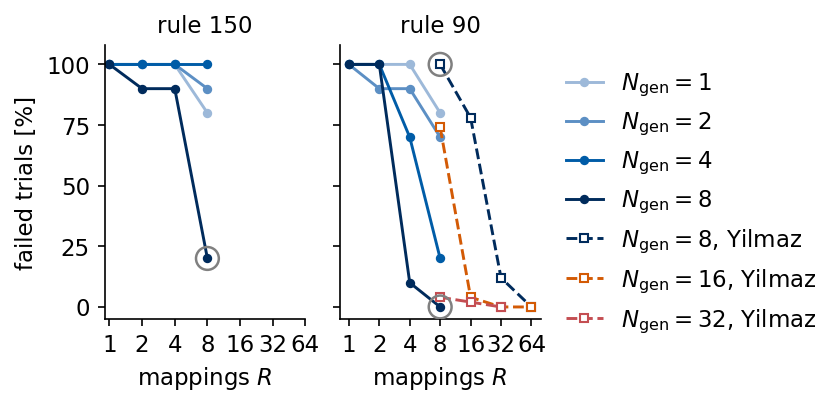

In [18]:
# Table 3 of Yilmaz (2014), rule 90, percent failed trials (rows N_gen = 8, 16, 32; columns R = 8, 16, 32, 64; nan = not run)
YILMAZ_90 = np.array([[100, 78, 12, 0], [74, 4, 0, 0], [4, 2, 0, np.nan]])
Y_R, Y_NGEN = (8, 16, 32, 64), (8, 16, 32)
NGEN_COL = {1: "#9DB9D9", 2: "#5C8FC4", 4: UJBlue, 8: UJNavy, 16: DSOrange, 32: "#C44E52"}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), sharey=True, layout="constrained")
    for ax, rule in zip(axs, (150, 90)):
        for i, N_generation_steps in enumerate(RNGEN_GRID):
            ax.plot(RNGEN_GRID, fail5[rule][i], "o-", ms=3.5, color=NGEN_COL[N_generation_steps], label=rf"$N_{{\rm gen}}={N_generation_steps}$")
        if rule == 90:
            for i, N_generation_steps in enumerate(Y_NGEN):
                ax.plot(Y_R, YILMAZ_90[i], "s--", ms=3.5, color=NGEN_COL[N_generation_steps], mfc="white", label=rf"$N_{{\rm gen}}={N_generation_steps}$, Yilmaz")
        ax.scatter([8], [fail5[rule][-1, -1]], s=120, facecolor="none", edgecolor="0.5", lw=1.2, zorder=4)
        if rule == 90:
            ax.scatter([8], [YILMAZ_90[0, 0]], s=120, facecolor="none", edgecolor="0.5", lw=1.2, zorder=4)
        ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32, 64], ["1", "2", "4", "8", "16", "32", "64"])
        ax.set_xlabel("mappings $R$"); ax.set_title(f"rule {rule}"); ax.set_ylim(-5, 108)
    axs[0].set_ylabel("failed trials [%]")
    h, l = axs[1].get_legend_handles_labels()
    fig.legend(h, l, loc="outside right center", handlelength=1.6)
    save(fig, "fig_lab050_5bit"); plt.show()

Both rules fail in every trial with a single mapping, and the failures fall as both $R$ and $N_{\rm gen}$ grow, with 10 trials per grid point. Rule 90 reaches 0% failed trials at $R=N_{\rm gen}=8$, and rule 150 20%. More mappings and more iterations plausibly increase the chance that the injected bits interact and leave a trace that a linear readout can separate. The product $RI$ alone does not set the outcome in our runs. At $RI=8$ rule 90 fails in 80% of the trials at $(R,N_{\rm gen})=(8,1)$, in 90% at $(4,2)$ and in 100% at $(2,4)$ and $(1,8)$.

At the one grid point that both studies share, $R=N_{\rm gen}=8$, the results disagree. Our rule 90 fails in 0% of the trials, and Yilmaz reports 100% failed trials there. Our compartments of $L_c=40$ cells give $RN_{\rm gen}L_c=2560$ features at this point. In Yilmaz's table the failures of rule 90 vanish at $R=64$, $N_{\rm gen}=8$ or $R=32$, $N_{\rm gen}=16$, which would be 2048 features if each of his mappings occupied 4 cells, the number of input bits. With compartments of exactly 4 cells and the overwrite scheme every cell of the ring is rewritten at every step, so no state is carried from one input step to the next, and both rules fail in all 10 trials at $R=32$, $N_{\rm gen}=16$. The size of a mapping and the way the input enters the lattice are not given in the original paper, and they change the outcome at a given $R$ and $N_{\rm gen}$. Our runs reproduce the trend of Table 3, failures that fall as $R$ and $N_{\rm gen}$ grow, at a similar number of features, and they do not reproduce its individual entries.

This task needs a readout that recovers stored bits. Forecasting a measured signal also requires that the real-valued input be quantised and encoded at every step, that the lattice state carry the memory of the recent values from step to step, and that the readout return real numbers for 50 horizons.

<hr/>
## 4. Forecasting with a CA reservoir

We forecast all five signals with the protocol of the ESN, the same origins, targets, scores and validation-only selection. The ring has $L_c=16$ cells per compartment, the input is quantised and written in Gray code, it is encoded by replacement, which Kantic *et al.* found the most stable encoding against changes of the other hyperparameters in their study of linear rules, and the readout reads all $N_{\rm gen}+1$ configurations. The ridge strength is chosen from $\{10^{-4},10^{-2},1,10,100\}$. We first check our ridge solve for integer features against scikit-learn `Ridge` on one reservoir, and the test predictions agree to $6.0\times10^{-14}$. Before the full search we look at the space of rules.

In [19]:
def ca_digits(s, Q, q, code="gray"):
    # quantise s to Q levels and write the level (Gray or binary code) as B digits in base q, Q = q^B
    l = quantise(s, Q)
    g = gray(l) if code == "gray" else l
    B = int(round(np.log(Q) / np.log(q)))
    return np.stack([(g // q ** b) % q for b in range(B)], 1).astype(np.int32)

CA_RULES = {"32": (eca_table(32), 2, "I"), "4": (eca_table(4), 2, "II"), "90": (eca_table(90), 2, "III"),
            "150": (eca_table(150), 2, "III"), "30": (eca_table(30), 2, "III"), "110": (eca_table(110), 2, "IV"),
            "Z4(0,2,1)": (linear_table((0, 2, 1), 4), 4, "lin."), "Z4(1,2,1)": (linear_table((1, 2, 1), 4), 4, "lin.")}
CA_BETA = (1e-4, 1e-2, 1.0, 10.0, 100.0)

def ca_states(s, rule, Q, R, Lc, N_generation_steps, additive=False, code="gray", seed=0):
    table, q, _ = CA_RULES[rule]
    d = ca_digits(s, Q, q, code)
    cells = compartment_cells(R, Lc, d.shape[1], seed)
    return np.asarray(ca_reservoir(table, jnp.asarray(d), cells, q, R * Lc, N_generation_steps, additive, True), np.float32)

def ca_eval(s, cfg, test=False):
    # validation C_tot for one configuration, ridge strength chosen on validation; optionally test scores
    X = ca_states(s, *cfg)
    Yv = targets(s, K_VAL)
    best = (-1.0, None)
    for beta, W, b in ridge_int(X[K_FIT], targets(s, K_FIT), CA_BETA):
        v = score(X[K_VAL].astype(np.float64) @ W + b, Yv)["Ctot"]
        if v > best[0]:
            best = (v, (beta, W, b))
    out = dict(val=best[0], beta=best[1][0], n_feat=X.shape[1])
    if test:
        P = X[K_TEST].astype(np.float64) @ best[1][1] + best[1][2]
        out.update(pred=P, **score(P, targets(s, K_TEST)))
    return out

# check of the ridge solve for integer features against scikit-learn Ridge (rule 90, Q = 16, 4 compartments, N_gen = 4)
X_chk = ca_states(sig["SantaFe"], "90", 16, 4, 16, 4).astype(np.float64)
(_, W_c, b_c), = ridge_int(X_chk[K_FIT].astype(np.float32), targets(sig["SantaFe"], K_FIT), (1.0,))
sk = SkRidge(alpha=1.0, fit_intercept=True).fit(X_chk[K_FIT], targets(sig["SantaFe"], K_FIT))
nums["sklearn_diff"] = float(np.abs(sk.predict(X_chk[K_TEST]) - (X_chk[K_TEST] @ W_c + b_c)).max())
print(f"CA readout, beta = 1: max |prediction of our ridge solve - prediction scikit-learn| = {nums['sklearn_diff']:.1e}")

CA readout, beta = 1: max |prediction of our ridge solve - prediction scikit-learn| = 6.0e-14


### Rule space and the edge of chaos

Langton proposed a single parameter to order the rule space [Langton, Physica D **42**, 12 (1990)]. One state is chosen as quiescent, here 0, and a rule must map the all-quiescent neighbourhood to it. Langton's parameter $\lambda_L$ is the fraction of rule-table entries that map to a non-quiescent state. For $\lambda_L=0$ every configuration dies, and as $\lambda_L$ grows the dynamics passes from fixed and periodic patterns to complex and then chaotic ones. Langton observed the complex behaviour in an intermediate range of $\lambda_L$ and called it the edge of chaos. For the elementary rules with $000\to0$, the 128 even rule numbers, $\lambda_L$ is the number of 1 bits in the rule table divided by 8. To sample richer rule spaces we also draw random rules over $\mathbb Z_4$ with radius $a=1$, 64 table entries, by Langton's table method. Each entry is quiescent with probability $1-\lambda_L^{\rm target}$ and otherwise a random state from 1 to 3, with the target value $\lambda_L^{\rm target}$ on a grid $0,0.05,\dots,0.75$, three rules per value. The drawn tables have a measured $\lambda_L$ close to the target, and all figures use the measured value. Langton used four states and a neighbourhood of five cells, so our random rules are a smaller variant of his.

For every rule we measure two properties of the dynamics, after one cell of a random configuration on $L=257$ cells has been changed. The damage density $H$ is the fraction of cells in which the two copies differ after 100 iterations, and the spreading rate $v_f$ is the width of the damaged region divided by its largest possible value $2\cdot100+1$, so that $v_f=1$ means that the damage spreads by one cell per iteration in both directions. A damage that travels along the lattice without growing has $v_f$ close to zero, whatever its speed. Both are averaged over 10 random starts. For every rule we also measure the forecast quality of a CA reservoir built from it, the validation $C_{\rm tot}$ on Santa Fe and on Mackey–Glass at 25 with $Q=16$ levels, Gray code, replacement encoding, $R=8$ compartments of 16 cells and $N_{\rm gen}=4$, which gives 640 features.

In [20]:
def damage_stats(table, q, L=257, T=100, n_runs=10, seed=0):
    # one-cell perturbation of a random state: damage density H(T) and spreading rate v_f = (width of the damage)/(2T+1)
    rng = np.random.default_rng(seed); h, v = [], []
    for _ in range(n_runs):
        c0 = rng.integers(0, q, L)
        c1 = c0.copy(); c1[L // 2] = (c0[L // 2] + rng.integers(1, q)) % q
        D = np.asarray(ca_run(jnp.asarray(c0, jnp.int32), table, q, T)[-1] != ca_run(jnp.asarray(c1, jnp.int32), table, q, T)[-1])
        h.append(D.mean())
        idx = np.nonzero(D)[0] - L // 2
        v.append((idx.max() - idx.min() + 1) / (2 * T + 1) if len(idx) else 0.0)
    return float(np.mean(h)), float(np.mean(v))

def langton_lambda(table, q):
    # fraction of rule-table entries that map to a non-quiescent state (quiescent state 0)
    return float(np.mean(np.asarray(table) != 0))

def langton_table(lam, q, rng):
    # random rule over Z_q with radius 1: each entry is quiescent with probability 1 - lam; 000 -> 0 is kept
    t = np.where(rng.random(q ** 3) < lam, rng.integers(1, q, q ** 3), 0)
    t[0] = 0
    return jnp.asarray(t, jnp.int32)

def ca_val_table(s, table, q, Q=16, R=8, Lc=16, N_generation_steps=4):
    # validation C_tot of the reservoir built from one rule table (640 features)
    d = ca_digits(s, Q, q)
    X = np.asarray(ca_reservoir(table, jnp.asarray(d), compartment_cells(R, Lc, d.shape[1], 0), q, R * Lc, N_generation_steps, False, True),
                   np.float32)
    Yv = targets(s, K_VAL)
    return max(score(X[K_VAL].astype(np.float64) @ W + b, Yv)["Ctot"]
               for _, W, b in ridge_int(X[K_FIT], targets(s, K_FIT), CA_BETA))

# elementary rules with a quiescent state, 000 -> 0 (even rule numbers), and random rules over Z_4, three per lambda
EVEN = np.arange(0, 256, 2)
rng_l = np.random.default_rng(7)
LAM_GRID = np.round(np.arange(0.0, 0.76, 0.05), 2)
z4_rules = [(lam_, langton_table(lam_, 4, rng_l)) for lam_ in LAM_GRID for _ in range(3)]
z4_target = np.array([lam_ for lam_, _ in z4_rules])
eca_lam = np.array([langton_lambda(eca_table(r_), 2) for r_ in EVEN])
z4_lam = np.array([langton_lambda(t, 4) for _, t in z4_rules])
LAM_SIG = ("SantaFe", "MG25")
def rule_scan():
    return dict(eca_dmg=[damage_stats(eca_table(r_), 2) for r_ in EVEN],
                z4_dmg=[damage_stats(t, 4) for _, t in z4_rules],
                eca_val={n: [ca_val_table(sig[n], eca_table(r_), 2) for r_ in EVEN] for n in LAM_SIG},
                z4_val={n: [ca_val_table(sig[n], t, 4) for _, t in z4_rules] for n in LAM_SIG})
scan_settings = dict(L=257, T=100, runs=10, Q=16, R=8, Lc=16, N_generation_steps=4, betas=list(CA_BETA), z4_seed=7,
                     z4_tables_sum=int(sum(int(np.asarray(t).sum()) for _, t in z4_rules)))
scan_ = cached("rule_scan", scan_settings, rule_scan)
eca_dmg, z4_dmg = np.array(scan_["eca_dmg"]), np.array(scan_["z4_dmg"])
eca_val = {n: np.array(v) for n, v in scan_["eca_val"].items()}
z4_val = {n: np.array(v) for n, v in scan_["z4_val"].items()}

nums["z4_lambda_dev"] = float(np.abs(z4_lam - z4_target).max())
print(f"random Z4 rules: largest |measured lambda_L - target| = {nums['z4_lambda_dev']:.3f}")
nums["z4_damage_bands"] = {}
for lo, hi in ((0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.85)):
    sel = (z4_lam >= lo) & (z4_lam < hi)
    nums["z4_damage_bands"][f"{lo}-{hi}"] = dict(H=float(z4_dmg[sel, 0].mean()), v=float(z4_dmg[sel, 1].mean()), n=int(sel.sum()))
    print(f"Z4 random rules, lambda_L in [{lo}, {hi}): {sel.sum():2d} rules, mean damage density {z4_dmg[sel, 0].mean():.3f},"
          f" mean spreading rate {z4_dmg[sel, 1].mean():.3f}")
nums["eca_rules"] = {str(r_): dict(lam=float(eca_lam[i]), H=float(eca_dmg[i, 0]), v=float(eca_dmg[i, 1]),
                                   **{f"val_{n}": float(eca_val[n][i]) for n in LAM_SIG}) for i, r_ in enumerate(EVEN)}
nums["lambda"] = {}
for n in LAM_SIG:
    i_best = int(np.argmax(eca_val[n])); j_best = int(np.argmax(z4_val[n]))
    c_v = float(np.corrcoef(eca_dmg[:, 1], eca_val[n])[0, 1])
    nums["lambda"][n] = dict(eca_best_rule=int(EVEN[i_best]), eca_best_val=float(eca_val[n][i_best]),
                             eca_best_lambda=float(eca_lam[i_best]), eca_best_speed=float(eca_dmg[i_best, 1]),
                             z4_best_val=float(z4_val[n][j_best]), z4_best_lambda=float(z4_lam[j_best]),
                             z4_best_density=float(z4_dmg[j_best, 0]), corr_speed_val=c_v)
    top = np.argsort(eca_val[n])[::-1][:5]
    print(f"{n:8s} best elementary rules: " + ", ".join(f"{EVEN[i]} ({eca_val[n][i]:.1f}, lambda_L {eca_lam[i]:.3f},"
          f" v_f {eca_dmg[i, 1]:.2f})" for i in top))
    print(f"{'':8s} best random Z4 rule: lambda_L {z4_lam[j_best]:.3f}, damage density {z4_dmg[j_best, 0]:.3f},"
          f" validation C_tot {z4_val[n][j_best]:.1f} | corr(spreading rate, C_tot) over elementary rules {c_v:+.2f}")

rule_scan: read from the cache
random Z4 rules: largest |measured lambda_L - target| = 0.131
Z4 random rules, lambda_L in [0.0, 0.2): 14 rules, mean damage density 0.000, mean spreading rate 0.001
Z4 random rules, lambda_L in [0.2, 0.4): 11 rules, mean damage density 0.013, mean spreading rate 0.040
Z4 random rules, lambda_L in [0.4, 0.6): 11 rules, mean damage density 0.139, mean spreading rate 0.269
Z4 random rules, lambda_L in [0.6, 0.85): 12 rules, mean damage density 0.285, mean spreading rate 0.499
SantaFe  best elementary rules: 166 (34.9, lambda_L 0.500, v_f 0.01), 210 (34.5, lambda_L 0.500, v_f 0.01), 180 (34.4, lambda_L 0.500, v_f 0.02), 154 (34.3, lambda_L 0.500, v_f 0.01), 38 (33.6, lambda_L 0.375, v_f 0.00)
         best random Z4 rule: lambda_L 0.281, damage density 0.009, validation C_tot 31.3 | corr(spreading rate, C_tot) over elementary rules -0.24
MG25     best elementary rules: 180 (35.1, lambda_L 0.500, v_f 0.02), 244 (34.3, lambda_L 0.625, v_f 0.01), 210 (34.3, lam

The left panel shows the spreading rate against the measured $\lambda_L$, for the elementary rules (grey, with a small horizontal jitter) and for the random rules over $\mathbb Z_4$ (orange). The right panel shows the validation $C_{\rm tot}$ against $\lambda_L$ in the same colours, as small dots for the elementary rules and as lines for the random rules over $\mathbb Z_4$, with circles and solid lines for Santa Fe and squares and dashed lines for Mackey–Glass at 25, each point of a line the mean over the three rules of one target value, placed at their mean measured $\lambda_L$. The measured values differ from the targets by at most 0.131, since 64 table entries are drawn at random. For the random rules the damage grows with $\lambda_L$ in the way Langton described. The mean damage density is 0.000 for $\lambda_L<0.2$, 0.013 for $0.2\le\lambda_L<0.4$, 0.139 for $0.4\le\lambda_L<0.6$ and 0.285 above, and the spreading rate rises from 0.001 to 0.499 over the same bands. The elementary rules show the same trend with a large spread, since $\lambda_L$ alone does not fix the dynamics of a rule.

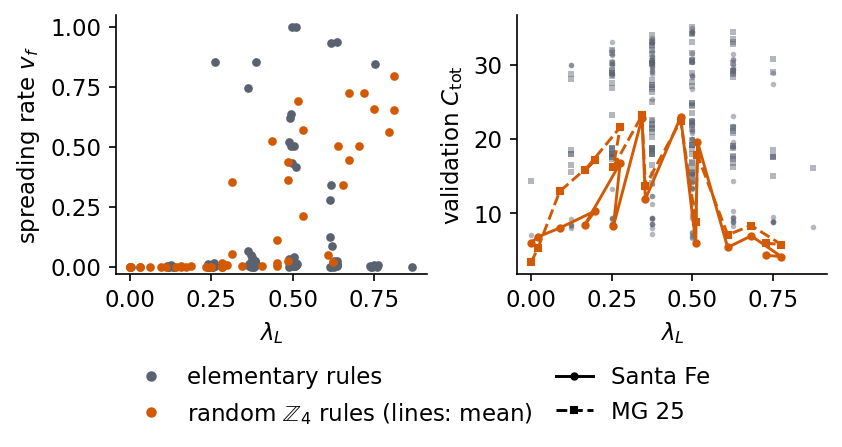

In [21]:
SIG_COL = {"SantaFe": UJNavy, "MG25": Teal}                  # signal colours of the next figure
SIG_MK = {"SantaFe": ("o", "-"), "MG25": ("s", "--")}          # marker and line style per signal
groups = [np.isclose(z4_target, l_) for l_ in LAM_GRID]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.9), layout="constrained")
    ax = axs[0]
    ax.scatter(eca_lam + np.random.default_rng(0).uniform(-0.012, 0.012, len(EVEN)), eca_dmg[:, 1], s=10, color=UJGray)
    ax.scatter(z4_lam, z4_dmg[:, 1], s=10, color=DSOrange)
    ax.set_xlabel(r"$\lambda_L$"); ax.set_ylabel(r"spreading rate $v_f$"); ax.set_ylim(-0.03, 1.05)
    ax = axs[1]
    for n in LAM_SIG:
        mk, ls = SIG_MK[n]
        ax.scatter(eca_lam, eca_val[n], s=7, marker=mk, color=UJGray, alpha=0.45, lw=0)
        ax.plot([z4_lam[g_].mean() for g_ in groups], [z4_val[n][g_].mean() for g_ in groups], marker=mk, ls=ls, ms=3,
                color=DSOrange)
    ax.set_xlabel(r"$\lambda_L$"); ax.set_ylabel(r"validation $C_{\rm tot}$")
    handles = [Line2D([], [], ls="", marker="o", ms=4, color=UJGray), Line2D([], [], ls="", marker="o", ms=4, color=DSOrange),
               Line2D([], [], marker="o", ls="-", ms=3, color="k"), Line2D([], [], marker="s", ls="--", ms=3, color="k")]
    labels = ["elementary rules", r"random $\mathbb{Z}_4$ rules (lines: mean)", "Santa Fe", "MG 25"]
    fig.legend(handles, labels, loc="outside lower center", ncol=2, handlelength=1.6, columnspacing=1.0)
    save(fig, "fig_lab050_lambda"); plt.show()

The forecast quality does not peak where the damage starts to spread fast. The best random rule over $\mathbb Z_4$ has $\lambda_L=0.281$ and damage density 0.009 on Santa Fe ($C_{\rm tot}=31.3$), and $\lambda_L=0.453$ with density 0.002 on Mackey–Glass at 25 ($C_{\rm tot}=30.1$). In both rules damage hardly spreads, although the second lies in the range of $\lambda_L$ where most rules spread damage. The best elementary rule is rule 166 on Santa Fe ($C_{\rm tot}=34.9$, $\lambda_L=0.500$, $v_f=0.01$) and rule 180 on Mackey–Glass at 25 ($C_{\rm tot}=35.1$, $v_f=0.02$). These rules move the content of cells along the lattice and change it locally, so a perturbation travels without spreading. In the damage runs of rules 180 and 210 above, the damaged region moves to the right by 0.99 and 1.00 cells per iteration, and after 100 iterations its mean width is only 2.9 and 2.0 cells, with at most 9 cells in any of the 20 runs. Over the 128 elementary rules the correlation between spreading rate and validation $C_{\rm tot}$ is -0.24 on Santa Fe and -0.32 on Mackey–Glass at 25. For forecasting with a linear readout these data do not support the hypothesis that the best reservoirs sit at the edge of chaos. They favour rules that carry information along the lattice without scrambling it. The test covers two signals, one reservoir size and one random mapping.

### Forecast map of all elementary rules

The rule scan fixes the number of generation steps per input step at $N_{\rm gen}=4$ and admits only the 128 rules with $000\to0$. We now map the forecast quality over all elementary rules and over $N_{\rm gen}$. Many of the 256 rules are copies of each other. Reflecting a rule from left to right, $f'(c_{j-1},c_j,c_{j+1})=f(c_{j+1},c_j,c_{j-1})$, or exchanging the roles of 0 and 1, $f'(c_{j-1},c_j,c_{j+1})=1-f(1-c_{j-1},1-c_j,1-c_{j+1})$, gives an automaton with the same dynamics up to a mirror image or a complement of every configuration. The code computes these equivalence classes, finds 88 of them and represents each class by its smallest rule number. Rules 154, 166, 180 and 210 form one class, so the two shift rules that led the rule scan are the same automaton, rule 210 being the complement of rule 180 and rule 166 its mirror image. In the reservoir the members of a class can still differ, because the injected code word is not complemented together with the rule and a mirrored lattice meets a different random mapping. Rules that map $000$ to 1 are now included. They change a quiet ring at the next iteration, which is harmless in a driven reservoir whose mapped cells are rewritten by the input at every step.

Each entry of the map is the validation $C_{\rm tot}$ of one reservoir, with the forecasting protocol of the ESN, the same origins and 50 horizons, and the ridge strength chosen on validation data from $\{10^{-4},10^{-2},1,10,100\}$. The other settings are fixed at the values that the forecasting search below selects for Santa Fe, $Q=16$ levels in Gray code, replacement encoding and $R=16$ compartments of $L_c=16$ cells. The number of generation steps per input step takes the values $N_{\rm gen}=1,2,3,4,6,8$, which gives 512 to 2304 features. One random mapping (seed 0) is used for every rule, so that the columns of the map differ only by the rule. The map is computed for Santa Fe and for Mackey–Glass at 25 and 35, and the automata of eight rules at a time run in parallel through `jax.vmap` over the rule tables. For every class we also measure the spreading rate $v_f$ of its representative with the damage runs of the rule scan, and we write the rule as a polynomial over $\mathbb Z_2$, its algebraic normal form. This is a sum modulo 2 of products of the three neighbourhood cells, obtained from the rule table by a Möbius transform, and it shows at a glance which cells a rule copies and which products it adds.

In [22]:
# the 88 dynamically distinct elementary rules: classes under left-right reflection and 0 <-> 1 complement
def reflect(rule):
    # f'(l, c, r) = f(r, c, l): output bit n of the new rule is bit 4r + 2c + l of the old one
    return sum(((rule >> (4 * (n & 1) + (n & 2) + (n >> 2))) & 1) << n for n in range(8))
def complement(rule):
    # f'(l, c, r) = 1 - f(1 - l, 1 - c, 1 - r): inverted inputs (index 7 - n) and inverted output
    return sum((1 - ((rule >> (7 - n)) & 1)) << n for n in range(8))
RULE_CLASS = {}
for r_ in range(256):
    orbit = sorted({r_, reflect(r_), complement(r_), reflect(complement(r_))})
    RULE_CLASS[orbit[0]] = orbit                       # each class is represented by its smallest rule number
MAP_RULES = np.array(sorted(RULE_CLASS))
assert len(MAP_RULES) == 88
assert reflect(180) == 166 and RULE_CLASS[min(RULE_CLASS[110])] == [110, 124, 137, 193]

def anf(rule, tex=False):
    # algebraic normal form over Z_2: Moebius transform of the rule table; monomials of c_{j-1}, c_j, c_{j+1}
    a = [(rule >> n) & 1 for n in range(8)]
    for b in range(3):
        for n in range(8):
            if n >> b & 1:
                a[n] ^= a[n ^ (1 << b)]
    # check: the polynomial reproduces the rule table
    assert all(sum(a[m] for m in range(8) if m & n == m) % 2 == (rule >> n) & 1 for n in range(8))
    names = [(4, "c_{j-1}"), (2, "c_j"), (1, "c_{j+1}")]
    mons = sorted((m for m in range(8) if a[m]), key=lambda m: (bin(m).count("1"), -m))
    terms = ["1" if m == 0 else "".join(v for bit, v in names if m & bit) for m in mons]
    if tex:
        return "$" + r"\oplus ".join(terms) + "$" if terms else "$0$"
    return " + ".join(terms) if terms else "0"
assert anf(90) == "c_{j-1} + c_{j+1}" and anf(150) == "c_{j-1} + c_j + c_{j+1}"
print(f"{len(MAP_RULES)} classes; rule 180 is in the class {RULE_CLASS[min(RULE_CLASS[180]) if 180 in RULE_CLASS else [k for k, v in RULE_CLASS.items() if 180 in v][0]]}")

88 classes; rule 180 is in the class [154, 166, 180, 210]


In [23]:
# spreading rate v_f of every class representative, with the damage function of the rule scan (same starts)
map_dmg = np.array([damage_stats(eca_table(int(r_)), 2) for r_ in MAP_RULES])
map_vf = map_dmg[:, 1]
for i, r_ in enumerate(MAP_RULES):                     # even rules: identical to the rule scan
    if r_ % 2 == 0:
        assert np.allclose(map_dmg[i], eca_dmg[list(EVEN).index(r_)])

# forecast map: validation C_tot for every class representative and N_gen iterations per input step,
# at Q = 16 (Gray code), replacement encoding, R = 16 compartments of 16 cells and one mapping (seed 0) for all rules
MAP_NGEN, MAP_SIG = (1, 2, 3, 4, 6, 8), ("SantaFe", "MG25", "MG35")
MAP_Q, MAP_R, MAP_LC, MAP_SEED, MAP_CHUNK = 16, 16, 16, 0, 8
def map_val(s, rules, N_generation_steps, seed=MAP_SEED):
    # validation C_tot (ridge strength chosen on validation) for the reservoirs of several rules, run with vmap over rule tables
    d = jnp.asarray(ca_digits(s, MAP_Q, 2)); cells = compartment_cells(MAP_R, MAP_LC, d.shape[1], seed)
    run = jax.vmap(lambda t: ca_reservoir(t, d, cells, 2, MAP_R * MAP_LC, N_generation_steps, False, True))
    tables = jnp.stack([eca_table(int(r_)) for r_ in rules])
    Yf, Yv, out = targets(s, K_FIT), targets(s, K_VAL), []
    for k in range(0, len(rules), MAP_CHUNK):          # chunks of 8 rules keep the feature arrays in memory
        for X in np.asarray(run(tables[k:k + MAP_CHUNK]), np.float32):
            out.append(max(score(X[K_VAL].astype(np.float64) @ W + b, Yv)["Ctot"]
                           for _, W, b in ridge_int(X[K_FIT], Yf, CA_BETA)))
    return out
def rule_map():
    t0 = time.time()
    val = {n: [map_val(sig[n], MAP_RULES, N_generation_steps) for N_generation_steps in MAP_NGEN] for n in MAP_SIG}
    return dict(val=val, runtime_s=time.time() - t0)
map_settings = dict(rules=MAP_RULES.tolist(), N_generation_steps=list(MAP_NGEN), signals=list(MAP_SIG), Q=MAP_Q, R=MAP_R, Lc=MAP_LC,
                    seed=MAP_SEED, betas=list(CA_BETA))
map_ = cached("rule_map", map_settings, rule_map)
map_val_ = {n: np.array(v) for n, v in map_["val"].items()}         # (N_gen, rules) per record
nums["rule_map_runtime_s"] = map_["runtime_s"]
print(f"map of {len(MAP_RULES)} rules x {len(MAP_NGEN)} values of N_gen x {len(MAP_SIG)} records: {map_['runtime_s'] / 60:.1f} min")

rule_map: read from the cache
map of 88 rules x 6 values of N_gen x 3 records: 24.3 min


In [24]:
def ranks(x):
    # ranks 0..n-1 (no ties expected in these real-valued scores)
    return np.argsort(np.argsort(x)).astype(float)
def spearman(x, y):
    return float(np.corrcoef(ranks(x), ranks(y))[0, 1])

# columns of the map: rules ordered by the mean validation C_tot over Santa Fe, MG 25 and all N_gen
map_mean = (map_val_["SantaFe"].mean(0) + map_val_["MG25"].mean(0)) / 2
map_order = np.argsort(map_mean)[::-1]
best_ngen = {n: np.array(MAP_NGEN)[np.argmax(map_val_[n], 0)] for n in MAP_SIG}          # best N_gen of every rule
nums["rule_map"] = dict(rules=MAP_RULES.tolist(), N_generation_steps=list(MAP_NGEN), vf=map_vf.tolist(),
                        val={n: v.tolist() for n, v in map_val_.items()}, order=MAP_RULES[map_order].tolist(), best={})
for n in MAP_SIG:
    i_, j_ = np.unravel_index(np.argmax(map_val_[n]), map_val_[n].shape)
    m_ = map_val_[n].mean(0)
    nums["rule_map"]["best"][n] = dict(rule=int(MAP_RULES[j_]), N_generation_steps=int(MAP_NGEN[i_]), val=float(map_val_[n][i_, j_]),
                                       corr_vf=float(np.corrcoef(m_, map_vf)[0, 1]), spearman_vf=spearman(m_, map_vf),
                                       n_best_ngen={str(N_generation_steps): int((best_ngen[n] == N_generation_steps).sum()) for N_generation_steps in MAP_NGEN})
    b_ = nums["rule_map"]["best"][n]
    print(f"{SHORT[n]:8s} best entry: rule {b_['rule']} at N_gen = {b_['N_generation_steps']}, validation C_tot = {b_['val']:.1f};"
          f" corr(mean C_tot over N_gen, v_f) = {b_['corr_vf']:+.2f} (rank correlation {b_['spearman_vf']:+.2f})")
    print(f"{'':8s} number of rules with their best value at N_gen = " + ", ".join(f"{N_generation_steps}: {c}" for N_generation_steps, c in b_["n_best_ngen"].items()))
nums["rule_map"]["corr_vf_mean"] = float(np.corrcoef(map_mean, map_vf)[0, 1])
nums["rule_map"]["spearman_records"] = {f"SantaFe-{n}": spearman(map_val_["SantaFe"].mean(0), map_val_[n].mean(0))
                                        for n in MAP_SIG[1:]}
print(f"rank correlation of the rule order (mean over N_gen) between Santa Fe and MG 25: "
      f"{nums['rule_map']['spearman_records']['SantaFe-MG25']:+.2f}, Santa Fe and MG 35: "
      f"{nums['rule_map']['spearman_records']['SantaFe-MG35']:+.2f}")
print(f"corr(mean C_tot over Santa Fe, MG 25 and N_gen, v_f) = {nums['rule_map']['corr_vf_mean']:+.2f}")

# how the order of the rules changes with N_gen: rank correlation between the columns of two values of N_gen
nums["rule_map"]["spearman_ngen"] = {}
for n in MAP_SIG:
    M_ = np.array([[spearman(map_val_[n][a], map_val_[n][b]) for b in range(len(MAP_NGEN))] for a in range(len(MAP_NGEN))])
    nums["rule_map"]["spearman_ngen"][n] = M_.tolist()
    print(f"{SHORT[n]:8s} rank correlation of the rule order between N_gen = 1 and N_gen = " +
          ", ".join(f"{N_generation_steps}: {M_[0, b]:+.2f}" for b, N_generation_steps in enumerate(MAP_NGEN) if b))

# mean validation C_tot of three groups of rules by spreading rate, against N_gen
VF_BINS = ((0.0, 0.05), (0.05, 0.5), (0.5, 1.01))
nums["rule_map"]["vf_groups"] = {}
for n in MAP_SIG:
    for lo, hi in VF_BINS:
        sel = (map_vf >= lo) & (map_vf < hi)
        nums["rule_map"]["vf_groups"].setdefault(n, {})[f"{lo}-{hi}"] = dict(n=int(sel.sum()), mean=map_val_[n][:, sel].mean(1).tolist())
        print(f"{SHORT[n]:8s} {sel.sum():2d} rules with {lo} <= v_f < {min(hi, 1.0)}: mean validation C_tot at N_gen = {MAP_NGEN}: "
              + " ".join(f"{v:5.1f}" for v in map_val_[n][:, sel].mean(1)))

# spreading rates at the top of the map: largest v_f of the ten best classes, best classes before the first with v_f >= 0.5
vf_ord = map_vf[map_order]
nums["rule_map"]["vf_max_top10"] = float(vf_ord[:10].max())
nums["rule_map"]["n_best_before_fast"] = int(np.argmax(vf_ord >= 0.5))
print(f"largest v_f of the ten best classes: {vf_ord[:10].max():.3f}; the {np.argmax(vf_ord >= 0.5)} best classes all have v_f < 0.5")

# rules of one class are the same automaton; in the reservoir they differ by the mapping and by the complemented input.
# The rule scan (all even rules, seed 0, R = 8, N_gen = 4) gives the spread of C_tot inside a class.
cls_spread = {n: [np.ptp([eca_val[n][list(EVEN).index(m)] for m in RULE_CLASS[r_] if m % 2 == 0])
                  for r_ in MAP_RULES if sum(m % 2 == 0 for m in RULE_CLASS[r_]) > 1] for n in LAM_SIG}
nums["rule_map"]["class_spread_scan"] = {n: dict(n_classes=len(v), median=float(np.median(v)), max=float(np.max(v)))
                                         for n, v in cls_spread.items()}
for n, v in cls_spread.items():
    print(f"{SHORT[n]:8s} rule scan, classes with two or more even rules ({len(v)}): largest minus smallest C_tot inside a class,"
          f" median {np.median(v):.1f}, largest {np.max(v):.1f}")
print("class of rule 180:", RULE_CLASS[[k for k, v in RULE_CLASS.items() if 180 in v][0]], "| rule scan C_tot (Santa Fe):",
      {m: round(float(eca_val["SantaFe"][list(EVEN).index(m)]), 1) for m in (154, 166, 180, 210)})

# validation C_tot against N_gen for a few rules
for r_ in (154, 27, 184, 90, 150, 30, 204):
    j_ = list(MAP_RULES).index(r_)
    print(f"rule {r_:3d} (v_f = {map_vf[j_]:.2f}), validation C_tot at N_gen = {MAP_NGEN}: "
          + " | ".join(f"{SHORT[n]} " + " ".join(f"{v:4.1f}" for v in map_val_[n][:, j_]) for n in MAP_SIG))

# table of the ten best and the ten worst rules by the mean over Santa Fe, MG 25 and N_gen
print("\n| rank | rule | class members | mean C_tot | best N_gen, C_tot (Santa Fe) | best N_gen, C_tot (MG 25) | v_f | algebraic normal form over Z_2 |")
print("|---|---|---|---|---|---|---|---|")
for rank in list(range(10)) + list(range(len(MAP_RULES) - 10, len(MAP_RULES))):
    j_ = map_order[rank]; r_ = int(MAP_RULES[j_])
    cells_ = [f"{best_ngen[n][j_]}, {map_val_[n][:, j_].max():.1f}" for n in ("SantaFe", "MG25")]
    print(f"| {rank + 1} | {r_} | {' '.join(map(str, RULE_CLASS[r_]))} | {map_mean[j_]:.1f} | {cells_[0]} | {cells_[1]} |"
          f" {map_vf[j_]:.2f} | {anf(r_)} |")

Santa Fe best entry: rule 154 at N_gen = 8, validation C_tot = 39.1; corr(mean C_tot over N_gen, v_f) = -0.28 (rank correlation +0.20)
         number of rules with their best value at N_gen = 1: 22, 2: 20, 3: 16, 4: 16, 6: 6, 8: 8
MG 25    best entry: rule 154 at N_gen = 8, validation C_tot = 41.3; corr(mean C_tot over N_gen, v_f) = -0.43 (rank correlation -0.05)
         number of rules with their best value at N_gen = 1: 18, 2: 19, 3: 20, 4: 8, 6: 6, 8: 17
MG 35    best entry: rule 7 at N_gen = 2, validation C_tot = 43.1; corr(mean C_tot over N_gen, v_f) = -0.43 (rank correlation -0.05)
         number of rules with their best value at N_gen = 1: 19, 2: 18, 3: 16, 4: 7, 6: 4, 8: 24
rank correlation of the rule order (mean over N_gen) between Santa Fe and MG 25: +0.91, Santa Fe and MG 35: +0.91
corr(mean C_tot over Santa Fe, MG 25 and N_gen, v_f) = -0.34
Santa Fe rank correlation of the rule order between N_gen = 1 and N_gen = 2: +0.91, 3: +0.84, 4: +0.82, 6: +0.73, 8: +0.75
MG 25   

Before the map, the gallery shows how a single cell in state 1 evolves under nine rules on a quiet ring of 81 cells over 40 iterations, with the rule number, the spreading rate $v_f$ and the algebraic normal form above each panel. The rules are the shift rules 180 and 210, the three best classes of the map other than the class of rule 180, represented by rules 27, 38 and 138, the two worst classes, represented by rules 204 and 60, and rules 90 and 30. Three things can happen to an injected bit. Under rule 180 it travels intact, one cell to the right per iteration, and rules 38 and 138 carry it to the left in the same way. A bit that travels intact remains a readable record of an earlier input, and these rules are at the top of the map. Rule 27 also moves the bit along the lattice, on a background that blinks between all 0 and all 1, because it maps $000$ to 1 and $111$ to 0. Under rules 90 and 60 the bit spreads into a Sierpinski triangle, and under rule 30 into an irregular triangle with 47 live cells after 40 iterations. A bit that spreads mixes with the bits of later inputs, and these rules lie in the lower half of the map. Rule 204 copies every cell unchanged, $c_j\leftarrow c_j$, so the bit stays where it was written. The next input overwrites it, and the other cells keep their initial zeros, so nothing of the past survives and rule 204 is next to last of the 88 classes.

Rule 210 shows that a single seed on a quiet ring tells only part of the story. From one cell it draws the same Sierpinski triangle as rule 90, because the 1s of that pattern are never neighbours and its product term $c_jc_{j+1}$ vanishes, while on a random background, where the spreading rate is measured, its damage spreads with $v_f=0.01$ only.

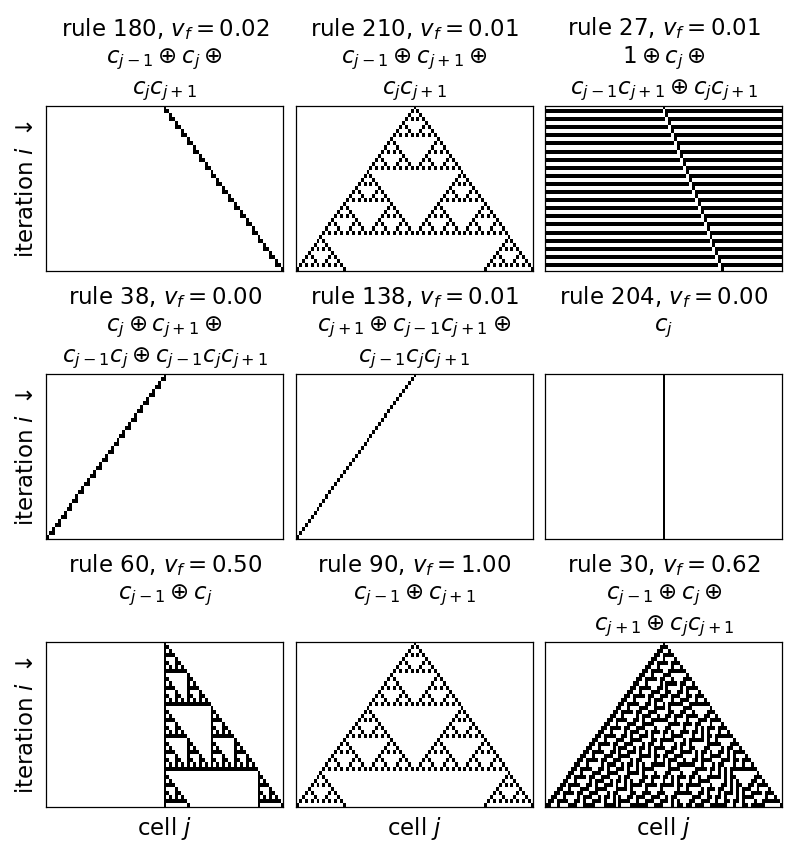

rule 180: live cells at i = 0, 1, 10, 40: 1, 2, 1, 1; v_f = 0.02; c_{j-1} + c_j + c_jc_{j+1}
rule 210: live cells at i = 0, 1, 10, 40: 1, 2, 4, 4; v_f = 0.01; c_{j-1} + c_{j+1} + c_jc_{j+1}
rule  27: live cells at i = 0, 1, 10, 40: 1, 80, 1, 1; v_f = 0.01; 1 + c_j + c_{j-1}c_{j+1} + c_jc_{j+1}
rule  38: live cells at i = 0, 1, 10, 40: 1, 2, 1, 1; v_f = 0.00; c_j + c_{j+1} + c_{j-1}c_j + c_{j-1}c_jc_{j+1}
rule 138: live cells at i = 0, 1, 10, 40: 1, 1, 1, 1; v_f = 0.01; c_{j+1} + c_{j-1}c_{j+1} + c_{j-1}c_jc_{j+1}
rule 204: live cells at i = 0, 1, 10, 40: 1, 1, 1, 1; v_f = 0.00; c_j
rule  60: live cells at i = 0, 1, 10, 40: 1, 2, 4, 4; v_f = 0.50; c_{j-1} + c_j
rule  90: live cells at i = 0, 1, 10, 40: 1, 2, 4, 4; v_f = 1.00; c_{j-1} + c_{j+1}
rule  30: live cells at i = 0, 1, 10, 40: 1, 3, 11, 47; v_f = 0.62; c_{j-1} + c_j + c_{j+1} + c_jc_{j+1}


In [25]:
# single-seed evolutions: the shift rules 180 and 210, the three best (other classes) and two worst rules of the map, rules 90 and 30
cls180 = [k for k, v in RULE_CLASS.items() if 180 in v][0]
top_other = [int(MAP_RULES[j]) for j in map_order if MAP_RULES[j] != cls180][:3]
worst = [int(MAP_RULES[j]) for j in map_order[::-1][:2]][::-1]
GAL_RULES = [180, 210] + top_other + worst + [90, 30]
gal_vf = {r_: damage_stats(eca_table(r_), 2)[1] for r_ in GAL_RULES}
nums["rule_gallery"] = {str(r_): dict(vf=gal_vf[r_], anf=anf(r_)) for r_ in GAL_RULES}
L_GAL, T_GAL = 81, 40
seed_gal = jnp.zeros(L_GAL, jnp.int32).at[L_GAL // 2].set(1)
def anf_title(r_):
    # rule formula over Z_2, broken into lines of at most two terms
    t = anf(r_, tex=True)[1:-1].split(r"\oplus ")
    return "\n".join("$" + r"\oplus ".join(t[k:k + 2]) + ("\\oplus$" if k + 2 < len(t) else "$") for k in range(0, len(t), 2))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 3, figsize=(5.2, 5.6), layout="constrained")
    for ax, r_ in zip(axs.ravel(), GAL_RULES):
        ax.imshow(np.asarray(ca_run(seed_gal, eca_table(r_), 2, T_GAL)), cmap="Greys", vmin=0, vmax=1,
                  interpolation="nearest", aspect="auto")
        ax.set_xticks([]); ax.set_yticks([]); ax.spines[:].set_visible(True); ax.spines[:].set_linewidth(0.6)
        title_ = f"rule {r_}, $v_f={gal_vf[r_]:.2f}$\n" + anf_title(r_)
        ax.set_title(title_ + "\n" * (2 - title_.count("\n")), fontsize=11)        # three title lines in every panel
    for ax in axs[:, 0]: ax.set_ylabel(r"iteration $i$ $\downarrow$")
    for ax in axs[-1]: ax.set_xlabel("cell $j$")
    save(fig, "fig_lab050_rule_gallery"); plt.show()
# slide version, drawn at its printed size (half the slide width): rule number and v_f above each panel, no axis labels
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 3, figsize=(2.85, 2.5), layout="constrained")
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0.03, hspace=0.03)
    for ax, r_ in zip(axs.ravel(), GAL_RULES):
        ax.imshow(np.asarray(ca_run(seed_gal, eca_table(r_), 2, T_GAL)), cmap="Greys", vmin=0, vmax=1,
                  interpolation="nearest", aspect="auto")
        ax.set_xticks([]); ax.set_yticks([]); ax.spines[:].set_visible(True); ax.spines[:].set_linewidth(0.6)
        ax.set_title(f"rule {r_}\n$v_f={gal_vf[r_]:.2f}$", fontsize=11, pad=2)
    save(fig, "fig_lab050_rule_gallery_slide"); plt.close(fig)
for r_ in GAL_RULES:
    S_ = np.asarray(ca_run(seed_gal, eca_table(r_), 2, T_GAL))
    print(f"rule {r_:3d}: live cells at i = 0, 1, 10, 40: {S_[0].sum()}, {S_[1].sum()}, {S_[10].sum()}, {S_[40].sum()};"
          f" v_f = {gal_vf[r_]:.2f}; {anf(r_)}")

The heatmaps show the validation $C_{\rm tot}$ for Santa Fe, Mackey–Glass at 25 and Mackey–Glass at 35 from top to bottom, with one column per class of rules, labelled by its smallest rule number, and one row per number of iterations $N_{\rm gen}$. The columns are ordered by the mean validation $C_{\rm tot}$ over Santa Fe, Mackey–Glass at 25 and all six values of $N_{\rm gen}$, best on the left, and the three panels share one colour scale. The thin strip on top colours each column by the spreading rate $v_f$ of its rule, from 0, no spreading, to 1, damage that spreads by one cell per iteration in both directions.

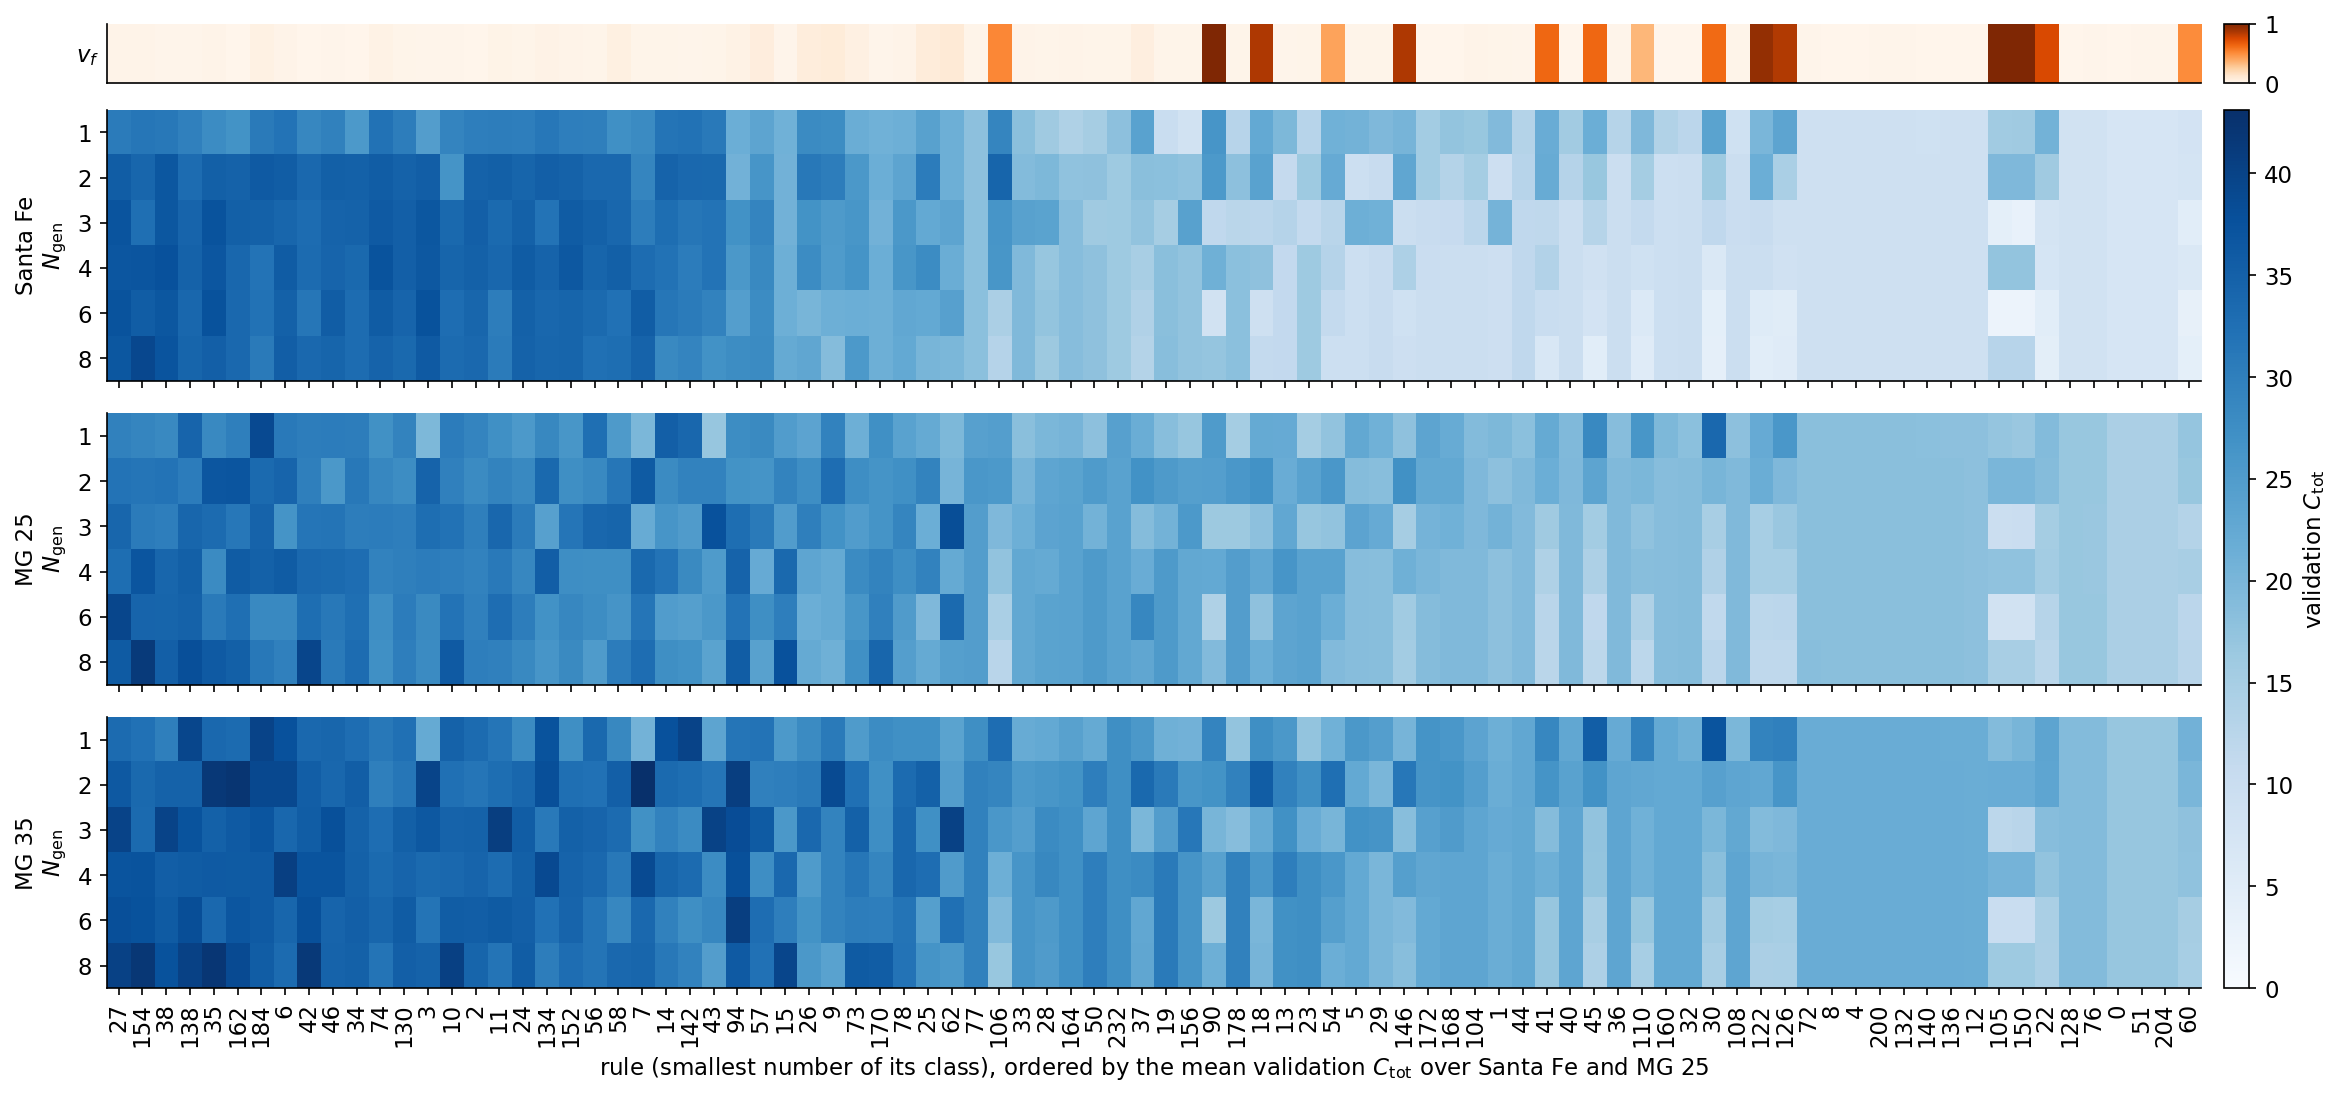

In [26]:
cols_ = MAP_RULES[map_order]
vmax_ = max(v.max() for v in map_val_.values())
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(15.5, 7.2), layout="constrained")
    gs = fig.add_gridspec(1 + len(MAP_SIG), 2, height_ratios=[0.22] + [1] * len(MAP_SIG), width_ratios=[1, 0.012])
    ax = fig.add_subplot(gs[0, 0])
    im_v = ax.imshow(map_vf[map_order][None, :], cmap="Oranges", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([0], [r"$v_f$"]); ax.tick_params(length=0)
    fig.colorbar(im_v, cax=fig.add_subplot(gs[0, 1]), ticks=[0, 1])
    for row, n in enumerate(MAP_SIG):
        ax = fig.add_subplot(gs[1 + row, 0])
        im = ax.imshow(map_val_[n][:, map_order], cmap="Blues", vmin=0, vmax=vmax_, aspect="auto", interpolation="nearest")
        ax.set_yticks(range(len(MAP_NGEN)), [str(N_generation_steps) for N_generation_steps in MAP_NGEN]); ax.set_ylabel(f"{SHORT[n]}\n" + r"$N_{\rm gen}$")
        if row < len(MAP_SIG) - 1:
            ax.set_xticks(range(len(cols_)), [""] * len(cols_))
        else:
            ax.set_xticks(range(len(cols_)), [str(r_) for r_ in cols_], rotation=90, fontsize=11)
            ax.set_xlabel("rule (smallest number of its class), ordered by the mean validation $C_{\\rm tot}$ over Santa Fe and MG 25")
    fig.colorbar(im, cax=fig.add_subplot(gs[1:, 1])).set_label(r"validation $C_{\rm tot}$")
    save(fig, "fig_lab050_rule_iteration_map"); plt.show()

# slide version at the full slide width: 88 column labels cannot be printed at 11 pt there, so only the five best
# and the four worst classes are labelled, spread out below the map and joined to their columns by thin lines
N_TOP_LAB, N_BOTTOM_LAB, LAB_GAP = 5, 4, 7
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.75), layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, hspace=0.02)
    gs = fig.add_gridspec(1 + len(MAP_SIG), 2, height_ratios=[0.3] + [1] * len(MAP_SIG), width_ratios=[1, 0.015])
    ax = fig.add_subplot(gs[0, 0])
    ax.imshow(map_vf[map_order][None, :], cmap="Oranges", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([0], [r"$v_f$"]); ax.tick_params(length=0)
    for row, n in enumerate(MAP_SIG):
        ax = fig.add_subplot(gs[1 + row, 0])
        im = ax.imshow(map_val_[n][:, map_order], cmap="Blues", vmin=0, vmax=vmax_, aspect="auto", interpolation="nearest")
        ax.set_yticks([0, len(MAP_NGEN) - 1], [str(MAP_NGEN[0]), str(MAP_NGEN[-1])]); ax.tick_params(axis="y", length=2, pad=1)
        ax.set_ylabel(SHORT[n], rotation=0, ha="right", va="center"); ax.set_xticks([])
    tr_ = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)      # x in columns, y in axes units
    n_ = len(cols_)
    lab_ = [(p, 1 + LAB_GAP * k) for k, p in enumerate(range(N_TOP_LAB))] + \
           [(p, n_ - 1 - LAB_GAP * (N_BOTTOM_LAB - 1 - k)) for k, p in enumerate(range(n_ - N_BOTTOM_LAB, n_))]
    for p, x_ in lab_:
        ax.annotate(str(cols_[p]), xy=(p, len(MAP_NGEN) - 0.5), xytext=(x_, -0.55), textcoords=tr_, ha="center", va="top",
                    annotation_clip=False, arrowprops=dict(arrowstyle="-", lw=0.6, color="0.3", shrinkA=0, shrinkB=0))
    fig.colorbar(im, cax=fig.add_subplot(gs[1:, 1]), ticks=[0, 20, 40]).set_label(r"$C_{\rm tot}$", labelpad=1)
    save(fig, "fig_lab050_rule_iteration_map_slide"); plt.close(fig)

In [27]:
# robustness of the ranking: five random mappings (seeds 0..4) for the five best rules and rules 90 and 30, at their best N_gen per record
SEED_RULES = [int(MAP_RULES[j]) for j in map_order[:5]] + [r_ for r_ in (90, 30) if r_ not in MAP_RULES[map_order[:5]]]
SEEDS, SEED_SIG = (0, 1, 2, 3, 4), ("SantaFe", "MG25")
seed_ngen = {n: {r_: int(best_ngen[n][list(MAP_RULES).index(r_)]) for r_ in SEED_RULES} for n in SEED_SIG}
seed_val = cached("rule_map_seeds", dict(map=map_settings, rules=SEED_RULES, N_generation_steps={n: list(v.values()) for n, v in seed_ngen.items()},
                                         seeds=list(SEEDS)),
                  lambda: {n: {str(r_): [map_val(sig[n], [r_], seed_ngen[n][r_], seed=sd)[0] for sd in SEEDS] for r_ in SEED_RULES}
                           for n in SEED_SIG})
nums["rule_map_seeds"] = {}
for n in SEED_SIG:
    print(f"{SHORT[n]}: validation C_tot over {len(SEEDS)} mappings")
    for r_ in SEED_RULES:
        v_ = np.array(seed_val[n][str(r_)])
        assert np.isclose(v_[0], map_val_[n][MAP_NGEN.index(seed_ngen[n][r_]), list(MAP_RULES).index(r_)])   # seed 0 is the map
        nums["rule_map_seeds"].setdefault(n, {})[str(r_)] = dict(N_generation_steps=seed_ngen[n][r_], mean=float(v_.mean()), sd=float(v_.std(ddof=1)),
                                                                min=float(v_.min()), max=float(v_.max()))
        print(f"  rule {r_:3d} at N_gen = {seed_ngen[n][r_]}: mean {v_.mean():5.1f}, standard deviation {v_.std(ddof=1):4.2f},"
              f" range {v_.min():5.1f} to {v_.max():5.1f}")
    top_ = [nums["rule_map_seeds"][n][str(r_)] for r_ in SEED_RULES[:5]]
    nums["rule_map_seeds"][n]["sd_max_top5"] = max(t["sd"] for t in top_)
    nums["rule_map_seeds"][n]["mean_range_top5"] = max(t["mean"] for t in top_) - min(t["mean"] for t in top_)
    print(f"  five best rules: means differ by at most {nums['rule_map_seeds'][n]['mean_range_top5']:.2f},"
          f" largest standard deviation over mappings {nums['rule_map_seeds'][n]['sd_max_top5']:.2f}")

rule_map_seeds: read from the cache
Santa Fe: validation C_tot over 5 mappings
  rule  27 at N_gen = 6: mean  37.3, standard deviation 0.52, range  36.7 to  38.1
  rule 154 at N_gen = 8: mean  39.2, standard deviation 0.24, range  38.9 to  39.5
  rule  38 at N_gen = 4: mean  36.7, standard deviation 0.62, range  36.1 to  37.6
  rule 138 at N_gen = 4: mean  34.2, standard deviation 0.70, range  33.2 to  35.0
  rule  35 at N_gen = 6: mean  36.8, standard deviation 0.56, range  36.0 to  37.4
  rule  90 at N_gen = 1: mean  23.0, standard deviation 2.65, range  20.0 to  26.3
  rule  30 at N_gen = 1: mean  25.1, standard deviation 0.85, range  23.7 to  26.0
  five best rules: means differ by at most 5.04, largest standard deviation over mappings 0.70
MG 25: validation C_tot over 5 mappings
  rule  27 at N_gen = 6: mean  38.0, standard deviation 0.80, range  37.4 to  39.4
  rule 154 at N_gen = 8: mean  38.0, standard deviation 1.87, range  36.9 to  41.3
  rule  38 at N_gen = 8: mean  34.2, st

The left third of the map is dark on all three records, and the strip above it is pale. The rules that forecast best are rules whose damage does not spread, with $v_f\le0.032$ for all ten best classes in the table. The class of rules 154, 166, 180 and 210 is second by the mean over Santa Fe, Mackey–Glass at 25 and all $N_{\rm gen}$, with 34.4, and it gives the best single entry on both records, 39.1 on Santa Fe and 41.3 on Mackey–Glass at 25, both at $N_{\rm gen}=8$. Its representative, rule 154, reaches 37.0 on Santa Fe at $N_{\rm gen}=4$, where rule 180 itself reaches 38.0 in the first stage of the forecasting search below. The best class by the mean is the class of rule 27, with 34.8, and on Mackey–Glass at 35 the best entry is rule 7 at $N_{\rm gen}=2$, with 43.1.

The number of generation steps changes the picture in different ways for different rules. Under a shift rule a bit injected at one input step has moved $N_{\rm gen}$ cells when the next code word is written, so $N_{\rm gen}$ sets how far apart successive inputs land in the lattice. For the class of rule 180 the validation $C_{\rm tot}$ rises from 31.4 at $N_{\rm gen}=1$ to 39.1 at $N_{\rm gen}=8$ on Santa Fe and from 28.8 to 41.3 on Mackey–Glass at 25. For the 13 rules with $v_f\ge0.5$ the trend is reversed. Their mean validation $C_{\rm tot}$ on Santa Fe falls from 20.7 at $N_{\rm gen}=1$ to 6.5 at $N_{\rm gen}=6$ and 8.4 at $N_{\rm gen}=8$, while the mean of the 67 rules with $v_f<0.05$ stays between 19.9 and 21.9. A spreading rule scrambles an injected code word further with every generation step, and a linear readout recovers less of it. Rule 30 shows this most clearly, with 23.7 at $N_{\rm gen}=1$ and 3.8 at $N_{\rm gen}=8$ on Santa Fe. The additive rules 90 and 150 do not fall monotonically. They score lower at $N_{\rm gen}=3$ and 6 than at 4 and 8, for rule 90 on Santa Fe 11.6 and 8.2 against 21.1 and 17.0, a dependence that we have not analysed. On Santa Fe 22 of the 88 classes have their best value at $N_{\rm gen}=1$ and 8 at $N_{\rm gen}=8$. The order of the rules changes gradually with $N_{\rm gen}$, and the rank correlation between the columns at $N_{\rm gen}=1$ and $N_{\rm gen}=8$ is 0.75 on Santa Fe and 0.58 on Mackey–Glass at 25.

Santa Fe and Mackey–Glass agree on the ranking. The rank correlation of the mean over $N_{\rm gen}$ between Santa Fe and Mackey–Glass at 25 is 0.91, and between Santa Fe and Mackey–Glass at 35 also 0.91. At the right end of the map rules 0, 51 and 204 give the same values for every $N_{\rm gen}$, 7.1 on Santa Fe and 14.4 on Mackey–Glass at 25. Under these rules nothing of an earlier input survives the next injection, and the readout sees only the present quantised value.

Over the 88 classes the correlation between the mean validation $C_{\rm tot}$ over $N_{\rm gen}$ and the spreading rate is −0.28 on Santa Fe, −0.43 on both Mackey–Glass records and −0.34 for the mean over Santa Fe and Mackey–Glass at 25. The rank correlations are +0.20 on Santa Fe and −0.05 on Mackey–Glass at 25 and 35. The negative linear correlation therefore comes from the few rules with fast spreading, none of which is among the 37 best classes, while among the slowly spreading rules $v_f$ does not order the forecast quality. A small spreading rate goes with every good forecast in this map, and many rules with a small spreading rate still forecast badly, down to rule 204 with $v_f=0.00$.

The map uses one mapping per rule. For the five best classes by the mean and for rules 90 and 30 we repeat the entry at the best $N_{\rm gen}$ of each record with five mappings, seeds 0 to 4. On Santa Fe the standard deviation over mappings is at most 0.70 for the five best classes, while their means differ by up to 5.04, from 34.2 for rule 138 to 39.2 for rule 154, so the class of rule 180 leads on Santa Fe by more than the mapping spread, ahead of rule 27 with 37.3. On Mackey–Glass at 25 the standard deviation reaches 1.94, and rules 27 and 154 both have the mean 38.0, so these runs do not resolve the order at the top of this record. Rules 90 and 30 vary more with the mapping on Santa Fe, with standard deviations of 2.65 and 0.85, and stay far below the top, with means of 23.0 and 25.1. Members of one class differ by a similar amount. In the rule scan, with mirrored mappings and complemented inputs, the best and the worst member of a class differ by a median of 0.6 on Santa Fe and 1.2 on Mackey–Glass at 25 over 44 classes. The map is a validation result for one quantisation, $Q=16$, one lattice of $R=16$ compartments of 16 cells and one mapping per rule. The number of features grows with $N_{\rm gen}$ from 512 to 2304, so part of the gain of the shift rules at large $N_{\rm gen}$ may come from the larger readout.

### Damage spreading and the memory task

The spreading rate is the cellular automaton analogue of the largest Lyapunov exponent $\lambda_1$. In a chaotic flow a small perturbation grows exponentially in amplitude, while in a cellular automaton a perturbation cannot grow in amplitude and grows instead in extent, at most by one cell per iteration on each side. Read as an analogy, $v_f=0$ corresponds to $\lambda_1\le0$ and $v_f>0$ to $\lambda_1>0$. The left panel plots the validation $C_{\rm tot}$ of the 128 elementary reservoirs against $v_f$. The right panel plots the percentage of failed trials in the five-bit memory task at $R=N_{\rm gen}=8$, with 5 trials per rule, against $v_f$ for the sixteen rules that Yilmaz named. He reported that rules 32, 160, 4, 108, 218 and 250 give no useful result for any $R$ and $N_{\rm gen}$, and that rules 22, 30, 126, 150, 182, 110, 54, 62, 90 and 60 reach zero error for some combination. Rules at the same point share one label.

five_bit_rules: read from the cache
rule  32: spreading rate 0.00, failed five-bit trials at R = N_gen = 8: 100%
rule 160: spreading rate 0.00, failed five-bit trials at R = N_gen = 8: 100%
rule   4: spreading rate 0.00, failed five-bit trials at R = N_gen = 8: 100%
rule 108: spreading rate 0.01, failed five-bit trials at R = N_gen = 8: 100%
rule 218: spreading rate 0.01, failed five-bit trials at R = N_gen = 8: 100%
rule 250: spreading rate 0.00, failed five-bit trials at R = N_gen = 8: 100%
rule  22: spreading rate 0.74, failed five-bit trials at R = N_gen = 8: 100%
rule  30: spreading rate 0.62, failed five-bit trials at R = N_gen = 8: 100%
rule 126: spreading rate 0.84, failed five-bit trials at R = N_gen = 8: 100%
rule 150: spreading rate 1.00, failed five-bit trials at R = N_gen = 8: 20%
rule 182: spreading rate 0.93, failed five-bit trials at R = N_gen = 8: 100%
rule 110: spreading rate 0.34, failed five-bit trials at R = N_gen = 8: 100%
rule  54: spreading rate 0.41, failed fiv

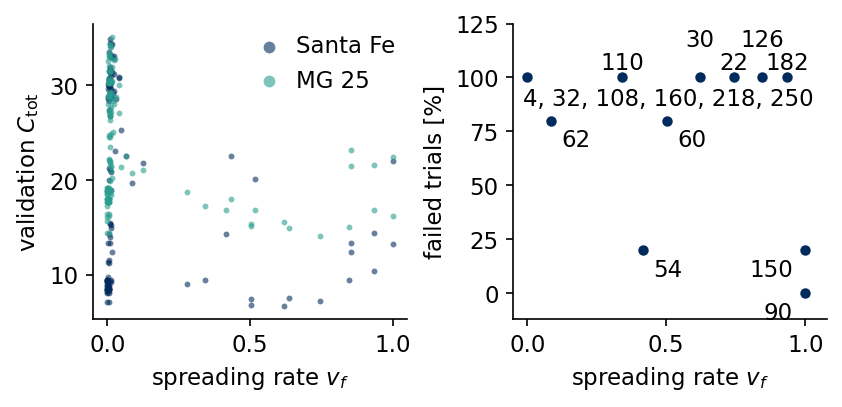

In [28]:
YILMAZ_RULES = (32, 160, 4, 108, 218, 250, 22, 30, 126, 150, 182, 110, 54, 62, 90, 60)
fail_y = cached("five_bit_rules", dict(T0=T0_5BIT, Lc=LC_5BIT, R=8, N_generation_steps=8, trials=5, rules=list(YILMAZ_RULES)),
                lambda: {str(r_): failed_percent(r_, 8, 8, LC_5BIT, 5) for r_ in YILMAZ_RULES})
fail_y = {int(k): v for k, v in fail_y.items()}
speed_y = {r_: float(eca_dmg[list(EVEN).index(r_), 1]) for r_ in YILMAZ_RULES}
nums["five_bit_rules"] = {str(r_): dict(failed=fail_y[r_], speed=speed_y[r_]) for r_ in YILMAZ_RULES}
for r_ in YILMAZ_RULES:
    print(f"rule {r_:3d}: spreading rate {speed_y[r_]:.2f}, failed five-bit trials at R = N_gen = 8: {fail_y[r_]:.0f}%")
# rules at the same position (spreading rate within 0.02, same failure rate) share one label
pts = []
for r_ in YILMAZ_RULES:
    for p in pts:
        if abs(p["v"] - speed_y[r_]) < 0.02 and p["f"] == fail_y[r_]:
            p["rules"].append(r_); break
    else:
        pts.append(dict(v=speed_y[r_], f=fail_y[r_], rules=[r_]))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), layout="constrained")
    ax = axs[0]
    for n in LAM_SIG:
        ax.scatter(eca_dmg[:, 1], eca_val[n], s=8, color=SIG_COL[n], alpha=0.6, lw=0, label=SHORT[n])
    ax.set_xlabel(r"spreading rate $v_f$"); ax.set_ylabel(r"validation $C_{\rm tot}$")
    ax.legend(loc="upper right", handletextpad=0.2, borderaxespad=0.1, markerscale=2)
    ax = axs[1]
    # labels of the fast rules at 100% failures alternate between two heights above the points; the slow rules share one label below
    low = [p for p in pts if p["v"] < 0.05 and p["f"] >= 100]
    top = sorted([p for p in pts if p["f"] >= 100 and p not in low], key=lambda p: p["v"])
    for p in pts:
        ax.scatter(p["v"], p["f"], s=16, color=UJNavy, zorder=3)
    low_rules = sorted(r_ for p in low for r_ in p["rules"])
    ax.annotate(", ".join(map(str, low_rules)), (0.0, 100), textcoords="offset points", xytext=(-2, -5), va="top", fontsize=11)
    for idx, p in enumerate(top):
        ax.annotate(", ".join(map(str, sorted(p["rules"]))), (p["v"], p["f"]), textcoords="offset points",
                    xytext=(0, 4 if idx % 2 == 0 else 15), ha="center", fontsize=11)
    for p in pts:
        if p in low or p in top: continue
        ha = "right" if p["v"] > 0.9 else "left"
        ax.annotate(", ".join(map(str, sorted(p["rules"]))), (p["v"], p["f"]), textcoords="offset points",
                    xytext=(-6 if ha == "right" else 5, -4), ha=ha, va="top", fontsize=11)
    ax.set_xlabel(r"spreading rate $v_f$"); ax.set_ylabel("failed trials [%]"); ax.set_ylim(-12, 125); ax.set_xlim(-0.05, 1.08)
    save(fig, "fig_lab050_damage_exponent"); plt.show()

All six rules of Yilmaz's first group have $v_f\le0.01$ and fail in every trial in our runs, in agreement with his finding. Of his second group, rule 90 ($v_f=1.00$) fails in 0% of the trials, rule 150 ($v_f=1.00$) in 20% and rule 54 ($v_f=0.41$) in 20%, while rules 22, 30, 126 and 182, with spreading rates between 0.62 and 0.93, fail in all trials at this size. Spreading of damage is necessary for the memory task in our runs, because the five pattern bits must reach many cells to survive the 200 distractor steps, and it is not sufficient. The two additive rules 90 and 150 perform best, as Yilmaz also found, and the remaining differences to his list may come from the different way the input is combined with the state. The forecasting task orders the rules differently, and there the rules with $v_f$ close to zero lead. The two tasks ask for different properties of the reservoir, long storage of a few bits in the first case and a readable record of the recent real-valued input in the second.

### Forecasts of the five signals

The forecasting search runs in two stages on the validation origins of each signal. The first stage compares ten rules, the elementary rules 32, 4, 90, 150, 30 and 110 from the space-time diagrams, the linear rules with weights $(0,2,1)$ and $(1,2,1)$ over $\mathbb Z_4$, and the two elementary rules with the best mean validation $C_{\rm tot}$ over Santa Fe and Mackey–Glass at 25 in the rule scan above, for replacement and addition encoding at $Q=16$, $R=16$ and $N_{\rm gen}=4$. The best rule with replacement encoding goes to the second stage, which scans $Q\in\{4,16,64\}$, $N_{\rm gen}\in\{1,2,4,8\}$ and $R\in\{4,8,16\}$.

In [29]:
# the two elementary rules with the best mean validation C_tot in the rule scan join the candidate rules
for i in np.argsort(eca_val["SantaFe"] + eca_val["MG25"])[::-1][:2]:
    CA_RULES.setdefault(str(EVEN[i]), (eca_table(int(EVEN[i])), 2, ""))        # no class label
print("candidate rules:", list(CA_RULES))
# stage 1: rule and encoding at Q = 16 levels, 16 compartments of 16 cells, N_gen = 4
t0 = time.time()
ca_rule_val = {name: {} for name in SIGNALS}
for name in SIGNALS:
    for rule in CA_RULES:
        for additive in (False, True):
            ca_rule_val[name][(rule, additive)] = ca_eval(sig[name], (rule, 16, 16, 16, 4, additive))["val"]
    best_rule = max((k for k in ca_rule_val[name] if not k[1]), key=ca_rule_val[name].get)
    print(f"{name:8s} validation C_tot, replacement: " + " ".join(f"{r} {ca_rule_val[name][(r, False)]:.1f} |" for r in CA_RULES)
          + f"\n{'':8s} best rule with replacement: {best_rule[0]}; addition encoding at most "
          f"{max(v for (r, a), v in ca_rule_val[name].items() if a):.1f}")
print(f"stage 1: {time.time() - t0:.0f} s")

# stage 2: levels Q, iterations N_gen and compartments R for the best rule of each signal
Q_GRID, NGEN_GRID, R_GRID, LC = (4, 16, 64), (1, 2, 4, 8), (4, 8, 16), 16
t0 = time.time()
ca_cfg = {}
for name in SIGNALS:
    rule, additive = max((k for k in ca_rule_val[name] if not k[1]), key=ca_rule_val[name].get)
    vals = {(Q, N_generation_steps, R): ca_eval(sig[name], (rule, Q, R, LC, N_generation_steps, additive))["val"]
            for Q in Q_GRID for N_generation_steps in NGEN_GRID for R in R_GRID}
    Q, N_generation_steps, R = max(vals, key=vals.get)
    ca_cfg[name] = (rule, Q, R, LC, N_generation_steps, additive)
    res[name]["CA"] = ca_eval(sig[name], ca_cfg[name], test=True)
    small = max((v, k) for k, v in vals.items() if k[2] == 4 and k[1] == 4)      # 4 compartments, N_gen = 4: 320 features
    res[name]["CA"]["val_small"] = small
    print(f"{name:8s} rule {rule}, Q = {Q}, N_gen = {N_generation_steps}, R = {R}: validation {vals[(Q, N_generation_steps, R)]:.1f}, test C_tot = "
          f"{res[name]['CA']['Ctot']:.1f} ({res[name]['CA']['n_feat']} features) | ESN {res[name]['ESN']['Ctot']:.1f}")
print(f"stage 2: {time.time() - t0:.0f} s")
assert ca_cfg["SantaFe"][1:4] == (MAP_Q, MAP_R, MAP_LC)        # the forecast map used the selected Santa Fe setting

# the 320-feature reservoir (4 compartments, N_gen = 4, best Q on validation) on the test block
for name in SIGNALS:
    rule, _, _, _, _, additive = ca_cfg[name]
    Q_s = res[name]["CA"]["val_small"][1][0]
    res[name]["CA320"] = ca_eval(sig[name], (rule, Q_s, 4, LC, 4, additive), test=True)
    print(f"{name:8s} CA with {res[name]['CA320']['n_feat']} features: test C_tot = {res[name]['CA320']['Ctot']:.1f}")

# cost of one fit at the selected setting: CA run and ridge solve
for name in SIGNALS:
    res[name]["CA"]["t_fit"] = timed(lambda: ridge_int((X_ := ca_states(sig[name], *ca_cfg[name]))[K_FIT],
                                                       targets(sig[name], K_FIT), (res[name]["CA"]["beta"],)), n=3)[0]
nums["ca_rule_val"] = {n: {f"{r} {'add' if a else 'rep'}": v for (r, a), v in d.items()} for n, d in ca_rule_val.items()}
nums["ca_choice"] = {n: dict(rule=c[0], Q=c[1], R=c[2], Lc=c[3], N_generation_steps=c[4], additive=c[5], beta=res[n]["CA"]["beta"],
                             n_feat=res[n]["CA"]["n_feat"], val=res[n]["CA"]["val"]) for n, c in ca_cfg.items()}

candidate rules: ['32', '4', '90', '150', '30', '110', 'Z4(0,2,1)', 'Z4(1,2,1)', '180', '210']


Lorenz   validation C_tot, replacement: 32 19.7 | 4 18.5 | 90 21.2 | 150 16.2 | 30 14.7 | 110 18.3 | Z4(0,2,1) 32.6 | Z4(1,2,1) 12.2 | 180 38.8 | 210 37.9 |
         best rule with replacement: 180; addition encoding at most 19.7


MG15     validation C_tot, replacement: 32 24.3 | 4 24.0 | 90 45.3 | 150 37.5 | 30 20.1 | 110 30.9 | Z4(0,2,1) 49.9 | Z4(1,2,1) 36.8 | 180 50.0 | 210 50.0 |
         best rule with replacement: 180; addition encoding at most 50.0


MG25     validation C_tot, replacement: 32 18.8 | 4 18.3 | 90 22.5 | 150 17.7 | 30 13.8 | 110 18.4 | Z4(0,2,1) 29.7 | Z4(1,2,1) 10.5 | 180 37.5 | 210 37.4 |
         best rule with replacement: 180; addition encoding at most 18.8


MG35     validation C_tot, replacement: 32 22.5 | 4 21.9 | 90 24.0 | 150 20.5 | 30 18.3 | 110 21.0 | Z4(0,2,1) 33.2 | Z4(1,2,1) 14.3 | 180 38.8 | 210 39.7 |
         best rule with replacement: 210; addition encoding at most 22.5


...

MG15     rule 180, Q = 4, N_gen = 2, R = 16: validation 50.0, test C_tot = 50.0 (768 features) | ESN 50.0


MG25     rule 180, Q = 16, N_gen = 8, R = 16: validation 43.3, test C_tot = 42.8 (2304 features) | ESN 48.3


MG35     rule 210, Q = 16, N_gen = 8, R = 16: validation 43.0, test C_tot = 44.8 (2304 features) | ESN 49.8


SantaFe  rule 180, Q = 16, N_gen = 4, R = 16: validation 38.0, test C_tot = 33.3 (1280 features) | ESN 34.7
stage 2: 157 s
Lorenz   CA with 320 features: test C_tot = 29.0
MG15     CA with 320 features: test C_tot = 49.9
MG25     CA with 320 features: test C_tot = 34.5


MG35     CA with 320 features: test C_tot = 40.9
SantaFe  CA with 320 features: test C_tot = 28.6


We compare the Gray code with the plain binary code on Santa Fe at the selected setting.

In [30]:
for code in ("gray", "binary"):
    cfg = ca_cfg["SantaFe"][:5] + (False, code)
    r_ = ca_eval(sig["SantaFe"], cfg)
    nums.setdefault("ca_code_val_SantaFe", {})[code] = r_["val"]
    print(f"Santa Fe, {code:6s} code: validation C_tot = {r_['val']:.1f}")

Santa Fe, gray   code: validation C_tot = 38.0


Santa Fe, binary code: validation C_tot = 35.1


The Gray code gives a validation $C_{\rm tot}$ of 38.0 against 35.1 for the binary code. The bar chart shows the first stage, the validation $C_{\rm tot}$ for every rule and signal with replacement encoding, with the Wolfram class below the rule number. The two linear rules over $\mathbb Z_4$ are labelled by their weights, 021 for $(0,2,1)$ and 121 for $(1,2,1)$. The two rules taken from the rule scan are left without a class label.

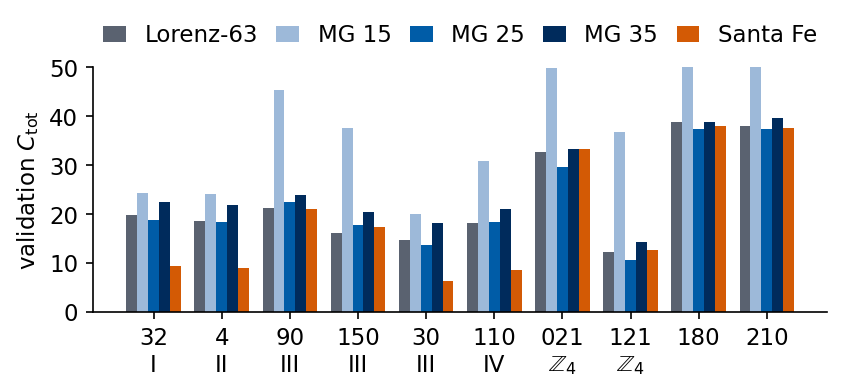

In [31]:
def tick(r):
    return f"{r}\n{CA_RULES[r][2]}" if r[0] != "Z" else r[3:-1].replace(",", "") + "\n" + r"$\mathbb{Z}_4$"
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
    rules = list(CA_RULES); x = np.arange(len(rules)); wbar = 0.16
    cols = {"Lorenz": UJGray, "MG15": "#9DB9D9", "MG25": UJBlue, "MG35": UJNavy, "SantaFe": DSOrange}
    for i, name in enumerate(SIGNALS):
        ax.bar(x + (i - 2) * wbar, [ca_rule_val[name][(r, False)] for r in rules], wbar, color=cols[name], label=SHORT[name])
    ax.set_xticks(x, [tick(r) for r in rules])
    ax.set_ylabel(r"validation $C_{\rm tot}$"); ax.set_ylim(0, 50)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, handlelength=1.0, columnspacing=0.8)
    save(fig, "fig_lab050_rules"); plt.show()

The two rules taken from the scan are rules 180 and 210. Rule 180 computes $c_j\leftarrow c_{j-1}\oplus(c_j\wedge\lnot c_{j+1})$ and rule 210 computes $c_j\leftarrow c_{j-1}\oplus(\lnot c_j\wedge c_{j+1})$, so both copy the left neighbour, a shift by one cell per iteration, and change it by a local exclusive or. Rule 166, the best elementary rule on Santa Fe in the scan, is the mirror image of rule 180.

Four groups of rules appear in the bar chart. Rule 32 empties the lattice within a few iterations, so its features contain little beyond the injected code word of the current value, and its capacity is that of a readout of the present quantised value, 9.4 on Santa Fe and 19.7 on Lorenz. Rule 4 is at the same level. The class III and IV rules 30 and 110 stay at or below this level on four of the five signals, plausibly because they scramble the injected code within a few iterations and a linear readout cannot decode it. The additive rules 90 and 150 and the linear rule with weights $(0,2,1)$ over $\mathbb Z_4$, which shifts digits to the left, do better. The shift rules 180 and 210 are the best on every signal, for example 38.0 on Santa Fe and 38.8 on Lorenz for rule 180. Addition encoding destroys the readability of the code, and with it the validation $C_{\rm tot}$ stays at most 22.5 on Lorenz, Mackey–Glass at 25 and 35 and Santa Fe. For forecasting with a linear readout these results point to the transport of information along the lattice without scrambling as the useful property, in agreement with the rule scan.

### Echo state property of the CA reservoir

The damage test runs without input. The echo state property concerns two copies of the reservoir driven by the same input, and in the CA reservoir the input overwrites only the $B$ mapped cells of each compartment at every step, so the other cells need not forget the initial configuration. We start two copies of the forecasting reservoir from different random configurations of the whole ring, drive both with the same input sequence and record after every input step the fraction of cells in which the lattice states $\mathbf c_k^{(N_{\rm gen})}$ of the two copies differ. The test uses five pairs of initial configurations at the selected setting of every signal, and on Santa Fe at its selected setting also the rules 90, 30 and 4.

In [32]:
@partial(jax.jit, static_argnums=(3, 4, 5))
def ca_lattice(table, digits, cells, q, N_generation_steps, additive, c0):
    # lattice state c_k^(N_gen) after every input step of the CA reservoir, started from the configuration c0
    def step(c, d):
        vals = jnp.broadcast_to(d, cells.shape)
        c = c.at[cells].set((c[cells] + vals) % q if additive else vals)
        for _ in range(N_generation_steps):
            c = ca_step(c, table, q)
        return c, c
    return jax.lax.scan(step, c0, digits)[1]

def ca_two_copies(s, rule, Q, R, Lc, N_generation_steps, additive=False, code="gray", seed=0, n_pairs=5):
    # fraction of differing cells after every input step for n_pairs of copies from random initial configurations
    table, q, _ = CA_RULES[rule]
    d = jnp.asarray(ca_digits(s, Q, q, code)); cells = compartment_cells(R, Lc, d.shape[1], seed)
    rng = np.random.default_rng(100); out = []
    for _ in range(n_pairs):
        ca_, cb_ = (ca_lattice(table, d, cells, q, N_generation_steps, additive, jnp.asarray(rng.integers(0, q, R * Lc), jnp.int32)) for _ in range(2))
        out.append(np.asarray(ca_ != cb_).mean(1))
    return np.array(out)

def esp_summary(F):
    # per pair: first step after which the copies agree for good (None if they still differ at the end)
    locks = []
    for f in F:
        nz = np.nonzero(f > 0)[0]
        locks.append(0 if len(nz) == 0 else (int(nz[-1] + 1) if nz[-1] < len(f) - 1 else None))
    done = [k for k in locks if k is not None]
    return dict(n_locked=len(done), n_pairs=len(locks), lock_max=max(done) if done else None,
                frac_test=float(F[:, K_TEST].mean()), frac_end=float(F[:, -1].mean()))

nums["esp_ca"] = {"selected": {}, "rules_SantaFe": {}}
for name in SIGNALS:
    rule, Q, R, Lc, N_generation_steps, additive = ca_cfg[name]
    e_ = esp_summary(ca_two_copies(sig[name], rule, Q, R, Lc, N_generation_steps, additive))
    nums["esp_ca"]["selected"][name] = dict(rule=rule, **e_)
    print(f"{name:8s} selected setting (rule {rule}, Q = {Q}, R = {R}, N_gen = {N_generation_steps}): copies agree in {e_['n_locked']} of {e_['n_pairs']} pairs,"
          f" from step {e_['lock_max']} on at the latest; differing fraction on the test origins {e_['frac_test']:.3f}")
rule_sf, Q_sf, R_sf, Lc_sf, ngen_sf, add_sf = ca_cfg["SantaFe"]
print(f"Santa Fe input, Q = {Q_sf}, R = {R_sf}, Lc = {Lc_sf}, N_gen = {ngen_sf}, ring of {R_sf * Lc_sf} cells:")
for rule in ("180", "210", "90", "30", "4"):
    e_ = esp_summary(ca_two_copies(sig["SantaFe"], rule, Q_sf, R_sf, Lc_sf, ngen_sf, add_sf))
    nums["esp_ca"]["rules_SantaFe"][rule] = e_
    print(f"  rule {rule:>3s}: copies agree in {e_['n_locked']} of {e_['n_pairs']} pairs, from step {e_['lock_max']} on at the latest;"
          f" differing fraction on the test origins {e_['frac_test']:.3f}, at the last step {e_['frac_end']:.3f}")

Lorenz   selected setting (rule 180, Q = 16, R = 16, N_gen = 8): copies agree in 5 of 5 pairs, from step 24 on at the latest; differing fraction on the test origins 0.000
MG15     selected setting (rule 180, Q = 4, R = 16, N_gen = 2): copies agree in 5 of 5 pairs, from step 169 on at the latest; differing fraction on the test origins 0.000


MG25     selected setting (rule 180, Q = 16, R = 16, N_gen = 8): copies agree in 5 of 5 pairs, from step 28 on at the latest; differing fraction on the test origins 0.000


MG35     selected setting (rule 210, Q = 16, R = 16, N_gen = 8): copies agree in 5 of 5 pairs, from step 26 on at the latest; differing fraction on the test origins 0.000


SantaFe  selected setting (rule 180, Q = 16, R = 16, N_gen = 4): copies agree in 5 of 5 pairs, from step 26 on at the latest; differing fraction on the test origins 0.000
Santa Fe input, Q = 16, R = 16, Lc = 16, N_gen = 4, ring of 256 cells:
  rule 180: copies agree in 5 of 5 pairs, from step 26 on at the latest; differing fraction on the test origins 0.000, at the last step 0.000


  rule 210: copies agree in 5 of 5 pairs, from step 25 on at the latest; differing fraction on the test origins 0.000, at the last step 0.000
  rule  90: copies agree in 0 of 5 pairs, from step None on at the latest; differing fraction on the test origins 0.383, at the last step 0.380


  rule  30: copies agree in 0 of 5 pairs, from step None on at the latest; differing fraction on the test origins 0.487, at the last step 0.476
  rule   4: copies agree in 0 of 5 pairs, from step None on at the latest; differing fraction on the test origins 0.090, at the last step 0.090


At the selected settings the two copies agree in all 5 pairs on every signal, from step 24 to 28 on at the latest for $Q=16$ and from step 169 on for Mackey–Glass at 15 with $Q=4$ and $N_{\rm gen}=2$. The differing fraction is zero on all test origins. On Mackey–Glass at 15 the copies agree only after the first fitting origin, $k=63$, so there the first fitting rows still depend on the initial configuration. With the same Santa Fe input rules 180 and 210 lock after at most 26 and 25 steps, while rules 90, 30 and 4 do not lock within the 4000 steps in any pair, and their differing fractions on the test origins are 0.383, 0.487 and 0.090. Under rule 4 a cell in state 1 survives as long as both neighbours are 0, and no cell changes from 0 to 1, so a difference on an isolated cell away from the mapped cells can persist. Under rules 90 and 30 a difference plausibly spreads faster than the injection removes it. Within these finite runs the echo state property therefore holds for the shift rules selected by the forecasting search and fails for rules 90, 30 and 4.

The same test bears on fading memory, the property that inputs that differ only long ago lead to nearly the same state. Two input histories that differ only before some step act on the later dynamics like two different configurations at that step. For the selected rules the state should therefore not depend on inputs older than a few tens of steps, in so far as the lock times measured from random configurations also hold for the configurations that the reservoir reaches.

The figure compares the capacity curves of the selected CA reservoir with persistence, AR, NVAR and the ESN.

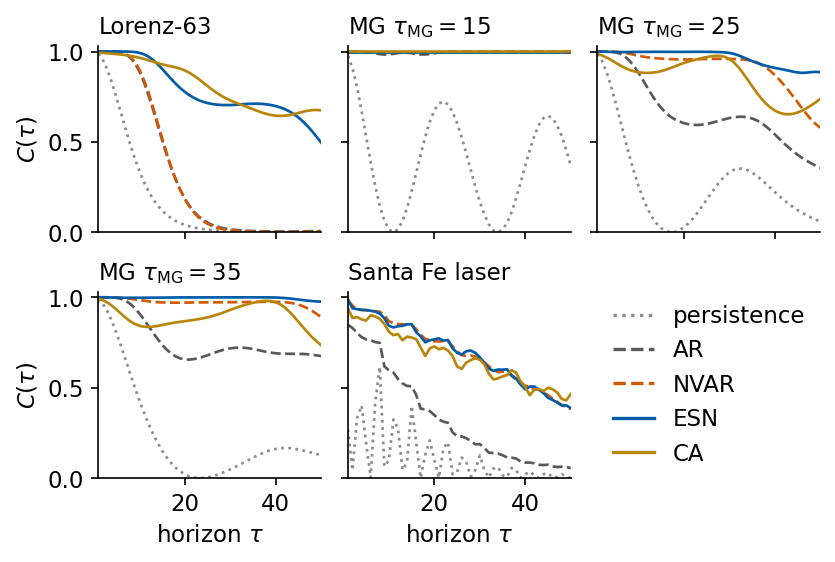

model         features   Lorenz     MG15     MG25     MG35  SantaFe   (test C_tot)
persistence          -      8.4     19.5     13.3     11.8      5.5
AR                         15.4     49.8     33.1     38.0     16.5
NVAR                       15.4     50.0     45.5     48.6     34.7
ESN                300     39.2     50.0     48.3     49.8     34.7
CA320              320     29.0     49.9     34.5     40.9     28.6
CA              varies     40.5     50.0     42.8     44.8     33.3


In [33]:
CMP = ("persistence", "AR", "NVAR", "ESN", "CA")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.11, right=0.985, bottom=0.13, top=0.93, wspace=0.12, hspace=0.32)
    for ax, name in zip(axs.ravel(), SIGNALS):
        for m in CMP:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, **STYLE[m])
        ax.set_title(LABEL[name], loc="left", fontsize=11)
        ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]: ax.set_xlabel(r"horizon $\tau$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$C(\tau)$")
    axs[1, 2].axis("off")
    model_legend(axs[1, 2], CMP, loc="center", handlelength=1.8)
    save(fig, "fig_lab050_capacity"); plt.show()

print(f"{'model':12s}{'features':>10s}" + "".join(f"{n:>9s}" for n in SIGNALS) + "   (test C_tot)")
for m in ("persistence", "AR", "NVAR", "ESN", "CA320", "CA"):
    nf = {"persistence": "-", "AR": "", "NVAR": "", "ESN": str(N_ESN), "CA320": "320", "CA": "varies"}[m]
    print(f"{m:12s}{nf:>10s}" + "".join(f"{res[n][m]['Ctot']:9.1f}" for n in SIGNALS))
nums["Ctot"] = {n: {m: res[n][m]["Ctot"] for m in ("persistence", "AR", "NVAR", "ESN", "CA", "CA320")} for n in SIGNALS}
nums["ca_tau_half"] = {n: res[n]["CA"]["tau_half"] for n in SIGNALS}

| test $C_{\rm tot}$ | Lorenz | MG 15 | MG 25 | MG 35 | Santa Fe |
|---|---|---|---|---|---|
| persistence | 8.4 | 19.5 | 13.3 | 11.8 | 5.5 |
| AR | 15.4 | 49.8 | 33.1 | 38.0 | 16.5 |
| NVAR | 15.4 | 50.0 | 45.5 | 48.6 | 34.7 |
| ESN, 300 features | 39.2 | 50.0 | 48.3 | 49.8 | 34.7 |
| CA, 320 features | 29.0 | 49.9 | 34.5 | 40.9 | 28.6 |
| CA, selected | 40.5 | 50.0 | 42.8 | 44.8 | 33.3 |
| CA rule | 180 | 180 | 180 | 210 | 180 |
| CA features | 2304 | 768 | 2304 | 2304 | 1280 |
| CA setting $(Q, N_{\rm gen}, R)$ | (16, 8, 16) | (4, 2, 16) | (16, 8, 16) | (16, 8, 16) | (16, 4, 16) |

On the periodic Mackey–Glass signal at $\tau_{\rm MG}=15$ the CA reservoir reaches 50.0, like AR, NVAR and the ESN close to the maximum. On the four irregular signals it beats AR, by 16.8 on Santa Fe. On Lorenz it reaches 40.5, against 39.2 for the ESN with 300 units and 15.4 for NVAR, and on Santa Fe it reaches 33.3 against 34.7 for the ESN and 34.7 for NVAR. On Mackey–Glass at 25 and 35 it stays below the ESN by 5.5 and 5.0. The comparison is not at equal size. The selected CA reservoirs use 768 to 2304 features, up to 7.7 times the 300 of the ESN, and larger ESNs also reach higher validation values. At 320 features, 4 compartments and $N_{\rm gen}=4$, the CA reservoir reaches 29.0 on Lorenz and 28.6 on Santa Fe, below the ESN with 300 units on every irregular signal.

The input reaches the CA reservoir only through $Q$ levels, and the selected $Q$ is 16 on the irregular signals, with a quantisation error of about 0.02 in units of the training range that no readout can undo. The one-step forecasts show the consequence.

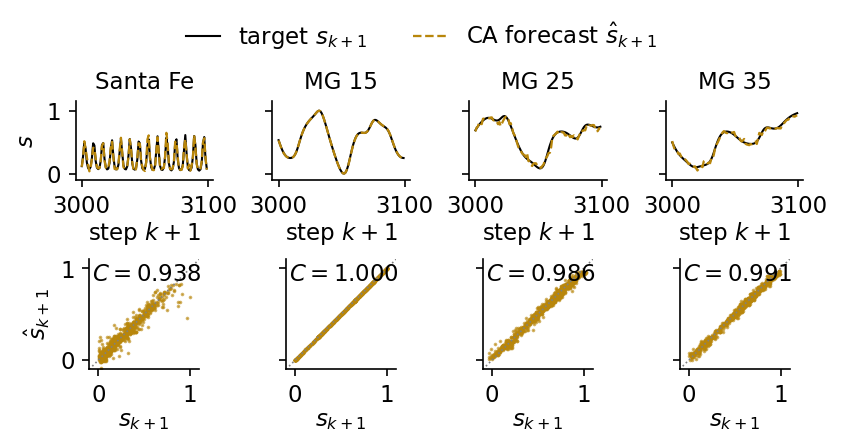

Lorenz   CA one step ahead: C = 0.9938 | ESN C = 1.0000
MG15     CA one step ahead: C = 1.0000 | ESN C = 1.0000
MG25     CA one step ahead: C = 0.9860 | ESN C = 0.9999
MG35     CA one step ahead: C = 0.9914 | ESN C = 1.0000
SantaFe  CA one step ahead: C = 0.9380 | ESN C = 0.9870


In [34]:
OS_SIG = ["SantaFe", "MG15", "MG25", "MG35"]
K_SHOW = 100
nums["ca_one_step"] = {}
for name in SIGNALS:
    y_t = targets(sig[name], K_TEST)[:, 0]; y_p = res[name]["CA"]["pred"][:, 0]
    nums["ca_one_step"][name] = dict(C=float(np.corrcoef(y_p, y_t)[0, 1] ** 2),
                                     nmse=float(np.sum((y_t - y_p) ** 2) / np.sum((y_t - y_t.mean()) ** 2)))
    nums["ca_one_step"][name]["C_ESN"] = float(res[name]["ESN"]["C"][0])
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 4, figsize=(5.5, 2.9), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
    for c_, name in enumerate(OS_SIG):
        a_t, a_s = axs[0, c_], axs[1, c_]
        y_t = targets(sig[name], K_TEST)[:, 0]; y_p = res[name]["CA"]["pred"][:, 0]
        kk = K_TEST[:K_SHOW] + 1
        a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label="target $s_{k+1}$")
        a_t.plot(kk, y_p[:K_SHOW], "--", color=CA_COL, lw=1.1, label=r"CA forecast $\hat s_{k+1}$")
        a_t.set_title(SHORT[name]); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
        a_t.set_xticks([kk[0], kk[0] + 100]); a_t.set_xlabel("step $k+1$", labelpad=1)
        a_s.plot(y_t, y_p, ".", ms=1.5, color=CA_COL, alpha=0.6)
        a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
        a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
        a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel("$s_{k+1}$", labelpad=1)
        a_s.text(0.03, 0.97, f"$C={nums['ca_one_step'][name]['C']:.3f}$", transform=a_s.transAxes, va="top", ha="left")
        if c_ > 0:
            a_t.set_yticklabels([]); a_s.set_yticklabels([])
    axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+1}$")
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.5)
    save(fig, "fig_lab050_onestep"); plt.show()
for name in SIGNALS:
    print(f"{name:8s} CA one step ahead: C = {nums['ca_one_step'][name]['C']:.4f} | ESN C = {nums['ca_one_step'][name]['C_ESN']:.4f}")

The one-step capacity of the CA reservoir is 0.938 on Santa Fe against 0.987 for the ESN, and 0.986 and 0.991 on Mackey–Glass at 25 and 35, where the ESN reaches 0.9999 and more. The periodic signal at 15 is forecast almost perfectly with only $Q=4$ levels, because there the sequence of coarse levels fixes the phase of the cycle. The second limit is the state itself. A tanh unit responds smoothly to small changes of the input and its state is a real number, while a binary cell holds one bit, and the memory of the CA is a moving pattern of bits that the next injection partly overwrites. A hypothesis that we have not tested is that the CA reservoir does best where the forecast needs many steps of memory and coarse amplitude information, as for Lorenz, and falls behind where fine amplitude resolution over a short window matters, as for Mackey–Glass at 25 and 35. These conclusions hold for the rules, encodings and grid sizes tested here and one random mapping per setting.

### Shift-register control

The best rules of the map and of the forecasting search copy a neighbour and add a few local products, as the algebraic normal form of rule 180, $c_{j-1}\oplus c_j\oplus c_jc_{j+1}$, shows. Their forecasts may come from the transport of the injected code bits alone, which turns the lattice into a delay line of bit-coded past values, or from the local products, which add nonlinear features. We separate the two with a control model without automaton. Its feature vector at step $k$ holds the Gray-code bits of the last $D$ samples $s_k,s_{k-1},\dots,s_{k-D+1}$, with the quantisation of the selected Santa Fe setting, $Q=16$ levels and $B=4$ bits, so it is a shift register of code words, with zero code words before the start of the record. The readout is the ridge regression of the CA reservoir with the same grid of ridge strengths, chosen on validation data. We use three variants on every signal. The first has $D=64$ lags and 256 features. The second has as many features as the selected CA reservoir of the signal, $D=320$ lags for the 1280 features on Santa Fe. The third adds to the bits of $D$ lags all 16 products of a bit of lag $d$ with a bit of lag $d+1$, $4D+16(D-1)$ features with $D$ chosen to match the size of the CA reservoir. With the linear terms a linear readout of these products can form the exclusive or and the product of any bit of one lag with any bit of the next, the kind of terms that rule 180 forms between neighbouring cells.

In [35]:
# shift-register control: Gray-code bits of the last D samples (Q = 16, B = 4), no automaton; zero code words before the record
SHIFT_Q, SHIFT_SMALL_D = 16, 64
def shift_features(s, ks, D, products=False):
    # rows: code words of s_k, s_{k-1}, ..., s_{k-D+1}; optionally all products of a bit of lag d with a bit of lag d+1
    bits = np.concatenate([np.zeros((D, 4), np.int32), ca_digits(s, SHIFT_Q, 2)])
    F = bits[ks[:, None] + D - np.arange(D)[None, :]]                        # (origins, D, B)
    parts = [F.reshape(len(ks), -1)]
    if products:
        parts.append((F[:, :-1, :, None] * F[:, 1:, None, :]).reshape(len(ks), -1))
    return np.concatenate(parts, 1).astype(np.float32)
def shift_eval(s, D, products=False):
    # ridge strength chosen on validation from the grid of the CA readout; validation and test C_tot
    Yv = targets(s, K_VAL); best = (-1.0, None)
    for beta, W, b in ridge_int(shift_features(s, K_FIT, D, products), targets(s, K_FIT), CA_BETA):
        v = score(shift_features(s, K_VAL, D, products).astype(np.float64) @ W + b, Yv)["Ctot"]
        if v > best[0]:
            best = (v, W, b)
    P = shift_features(s, K_TEST, D, products).astype(np.float64) @ best[1] + best[2]
    return dict(D=D, n_feat=best[1].shape[0], val=best[0], Ctot=score(P, targets(s, K_TEST))["Ctot"])

t0 = time.time()
nums["shift_control"] = {}
for name in SIGNALS:
    n_ca = res[name]["CA"]["n_feat"]
    sh = {"small": shift_eval(sig[name], SHIFT_SMALL_D),                       # 64 lags, 256 features
          "matched": shift_eval(sig[name], n_ca // 4),                         # as many features as the selected CA
          "products": shift_eval(sig[name], round((n_ca + 16) / 20), True)}    # 4D + 16(D-1) features, close to the CA
    nums["shift_control"][name] = sh
    print(f"{SHORT[name]:8s} test C_tot (validation): " + " | ".join(
        f"shift D = {v['D']} ({v['n_feat']} features){' with products' if k == 'products' else ''} {v['Ctot']:.1f} ({v['val']:.1f})"
        for k, v in sh.items()) + f" | CA rule {ca_cfg[name][0]} ({n_ca}) {res[name]['CA']['Ctot']:.1f} ({res[name]['CA']['val']:.1f})"
        f" | ESN {res[name]['ESN']['Ctot']:.1f} | AR {res[name]['AR']['Ctot']:.1f}")
nums["shift_control_runtime_s"] = time.time() - t0
print(f"shift-register control: {time.time() - t0:.0f} s")

Lorenz-63 test C_tot (validation): shift D = 64 (256 features) 16.0 (16.4) | shift D = 576 (2304 features) 8.7 (5.7) | shift D = 116 (2304 features) with products 39.5 (39.2) | CA rule 180 (2304) 40.5 (41.7) | ESN 39.2 | AR 15.4


MG 15    test C_tot (validation): shift D = 64 (256 features) 50.0 (50.0) | shift D = 192 (768 features) 50.0 (50.0) | shift D = 39 (764 features) with products 50.0 (50.0) | CA rule 180 (768) 50.0 (50.0) | ESN 50.0 | AR 49.8


MG 25    test C_tot (validation): shift D = 64 (256 features) 43.9 (41.8) | shift D = 576 (2304 features) 40.1 (40.7) | shift D = 116 (2304 features) with products 47.7 (48.0) | CA rule 180 (2304) 42.8 (43.3) | ESN 48.3 | AR 33.1


MG 35    test C_tot (validation): shift D = 64 (256 features) 46.3 (46.6) | shift D = 576 (2304 features) 47.1 (42.2) | shift D = 116 (2304 features) with products 49.4 (48.9) | CA rule 210 (2304) 44.8 (43.0) | ESN 49.8 | AR 38.0


Santa Fe test C_tot (validation): shift D = 64 (256 features) 24.3 (27.0) | shift D = 320 (1280 features) 20.8 (23.3) | shift D = 65 (1284 features) with products 26.5 (35.0) | CA rule 180 (1280) 33.3 (38.0) | ESN 34.7 | AR 16.5
shift-register control: 29 s


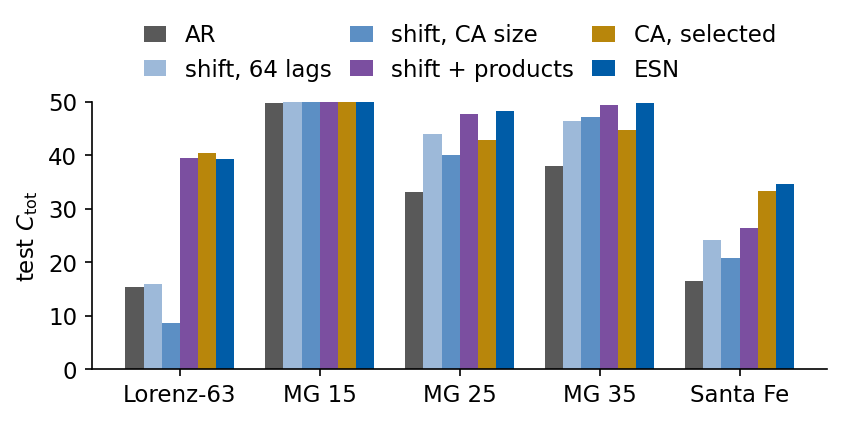

In [36]:
SH_MODELS = [("AR", "AR", STYLE["AR"]["color"]), ("small", "shift, 64 lags", "#9DB9D9"),
             ("matched", "shift, CA size", "#5C8FC4"), ("products", "shift + products", "#7B4FA0"),
             ("CA", "CA, selected", CA_COL), ("ESN", "ESN", STYLE["ESN"]["color"])]
def sh_value(name, key):
    return res[name][key]["Ctot"] if key in ("AR", "CA", "ESN") else nums["shift_control"][name][key]["Ctot"]
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.7), layout="constrained")
    x = np.arange(len(SIGNALS)); wbar = 0.13
    for i, (key, lab, col) in enumerate(SH_MODELS):
        ax.bar(x + (i - 2.5) * wbar, [sh_value(n, key) for n in SIGNALS], wbar, color=col, label=lab)
    ax.set_xticks(x, [SHORT[n] for n in SIGNALS]); ax.set_ylabel(r"test $C_{\rm tot}$"); ax.set_ylim(0, 50)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=1.0, columnspacing=0.8)
    save(fig, "fig_lab050_shift_control"); plt.show()

On the two chaotic Mackey–Glass records the shift register alone forecasts as well as the CA reservoir or better. With 64 lags it reaches a test $C_{\rm tot}$ of 43.9 at $\tau_{\rm MG}=25$ and 46.3 at 35, against 42.8 and 44.8 for the selected CA reservoirs with rules 180 and 210, and on the periodic record at 15 every model reaches 50.0. For these signals the transport of quantised past values accounts for the forecast of the CA reservoir. On Lorenz and Santa Fe the shift register falls far behind. It reaches 16.0 with 64 lags and 8.7 with 576 lags on Lorenz, against 40.5 for rule 180, and 24.3 with 64 lags and 20.8 with 320 lags on Santa Fe, against 33.3. The long register with as many features as the CA does worse than the short one on both, plausibly because a readout of 2304 or 1280 binary features overfits the 2387 fitting origins. At about the same number of features the products of adjacent lags raise the test $C_{\rm tot}$ from 8.7 to 39.5 on Lorenz, close to the 40.5 of the CA, and from 20.8 to 26.5 on Santa Fe, where the register with products reaches 35.0 on validation and loses much of it on the test block. With products the register also exceeds the CA on Mackey–Glass, with 47.7 at 25 and 49.4 at 35, close to the 48.3 and 49.8 of the ESN.

The control separates two sources of the forecast. On Mackey–Glass the intact transport of quantised past values is enough, and the automaton adds nothing over a plain shift register. On Lorenz and Santa Fe nonlinear products of neighbouring code bits are needed. On Lorenz the products of adjacent lags do almost as well as the automaton, and on Santa Fe the CA reservoir with rule 180 stays ahead of the register with products by 6.8 on the test block, so there the products that the automaton forms between cells brought next to each other by the shift are the better features. The comparison uses one quantisation, the selected CA setting of each signal and one test block per record, and the register with products is one of many possible designs.

<hr/>
## 5. Cost of the CA fit

The CA reservoir, like the ESN and the ridge baselines, is fitted by one run of the features and one linear solve. We time one fit at the selected setting of every model, the run of the reservoir and the ridge solve without the hyperparameter search, and report the median over the five signals. When the numbers file of the trained networks is available, we add a multilayer perceptron (MLP), a recurrent neural network (RNN), a gated recurrent unit (GRU) and a long short-term memory network (LSTM), trained in a separate notebook with the same signals, origins and scores. The parameter counts in the table are those of the settings selected for Santa Fe. The machine was shared with other jobs during the runs, so all times are upper estimates and change with hardware, load and implementation.

model   fit time [s]  trained parameters   Lorenz     MG15     MG25     MG35  SantaFe
AR             0.002                3250     15.4     49.8     33.1     38.0     16.5
NVAR           0.020               28050     15.4     50.0     45.5     48.6     34.7
ESN            0.134               15050     39.2     50.0     48.3     49.8     34.7
CA             0.379               64050     40.5     50.0     42.8     44.8     33.3
MLP            2.393                7410     29.4     50.0     48.4     49.5     35.3
RNN           11.832                2738     43.8     50.0     49.4     49.5     42.5
GRU           50.870                4914     45.1     50.0     49.8     49.9     43.0
LSTM          51.795                6002     43.8     50.0     49.9     49.9     44.3
NVAR fit time in the numbers file of the ESN notebook (JAX solve): 162 ms, here (numpy solve): 20 ms


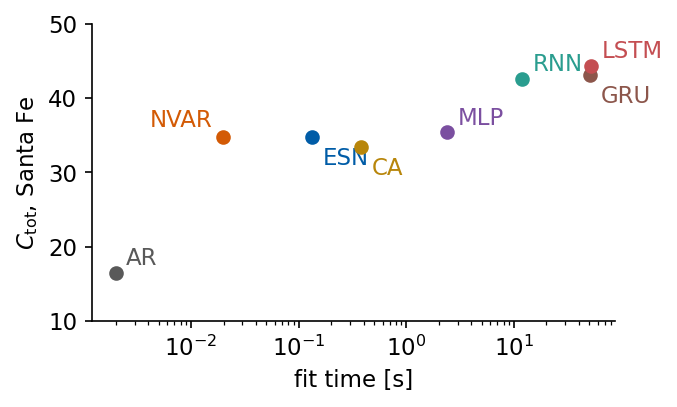

In [37]:
p036 = find_file("numbers_lab036.json", "../../Lecture_8/Notebooks/figures")
trained = json.load(open(p036)) if p036 else None
if trained is None:
    print("numbers of the trained networks not found, the comparison shows the models of this notebook only")
NETS = ("MLP", "RNN", "GRU", "LSTM") if trained else ()
HERE = ("AR", "NVAR", "ESN", "CA")
cost = {m: float(np.median([res[n][m]["t_fit"] for n in SIGNALS])) for m in HERE}     # median over the five signals
n_trained = {"AR": res["SantaFe"]["AR"]["n_feat"] * TAU_MAX + TAU_MAX,                  # settings selected for Santa Fe
             "NVAR": res["SantaFe"]["NVAR"]["n_feat"] * TAU_MAX + TAU_MAX,
             "ESN": N_ESN * TAU_MAX + TAU_MAX, "CA": res["SantaFe"]["CA"]["n_feat"] * TAU_MAX + TAU_MAX}
ctot_all = {n: {m: res[n][m]["Ctot"] for m in HERE} for n in SIGNALS}
if trained:
    cost.update({m: trained["fit_time_median_s"][m] for m in NETS})
    n_trained.update({m: trained["param_counts"][m] for m in NETS})
    for n in SIGNALS:
        ctot_all[n].update({m: trained["Ctot"][n][m] for m in NETS})
print(f"{'model':6s}{'fit time [s]':>14s}{'trained parameters':>20s}" + "".join(f"{n:>9s}" for n in SIGNALS))
for m in HERE + NETS:
    print(f"{m:6s}{cost[m]:14.3f}{n_trained[m]:20d}" + "".join(f"{ctot_all[n][m]:9.1f}" for n in SIGNALS))
nums["cost"] = dict(fit_time_s=cost, n_trained=n_trained, Ctot=ctot_all)
if ref046 and "cost" in ref046:
    nums["nvar_fit_time_lab046_s"] = ref046["cost"]["fit_time_s"]["NVAR"]
    print(f"NVAR fit time in the numbers file of the ESN notebook (JAX solve): {1000 * nums['nvar_fit_time_lab046_s']:.0f} ms,"
          f" here (numpy solve): {1000 * cost['NVAR']:.0f} ms")

LABEL_POS = {"AR": (5, 4, "left"), "NVAR": (4, 5, "left"), "ESN": (-5, 5, "right"), "CA": (5, -13, "left"),
             "MLP": (5, 4, "left"), "RNN": (5, 4, "left"), "GRU": (5, -13, "left"), "LSTM": (5, 4, "left")}
# ESN and NVAR have nearly the same C_tot on Santa Fe: the label of the faster one goes to the left, the other one below right
fast, slow = sorted(("ESN", "NVAR"), key=lambda m: cost[m])
LABEL_POS[fast], LABEL_POS[slow] = (-5, 5, "right"), (5, -13, "left")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6), layout="constrained")
    for m in HERE + NETS:
        x_, y_ = cost[m], ctot_all["SantaFe"][m]
        ax.scatter(x_, y_, s=36, color=STYLE[m]["color"], zorder=3)
        dx, dy, ha = LABEL_POS[m]
        ax.annotate(m, (x_, y_), textcoords="offset points", xytext=(dx, dy), ha=ha, color=STYLE[m]["color"])
    ax.set_xscale("log"); ax.set_xlabel("fit time [s]"); ax.set_ylabel(r"$C_{\rm tot}$, Santa Fe")
    ax.set_ylim(10, 50)
    save(fig, "fig_lab050_cost"); plt.show()

The figure places every model by its median fit time and its test $C_{\rm tot}$ on Santa Fe, with each label in the colour of its point. In this run one CA fit took 379 ms, the ESN fit 134 ms and the NVAR fit 20 ms. These are wall-clock times on a machine shared with other jobs and compare orders of magnitude only. The NVAR fit here uses a numpy solve, and the same fit with the JAX solve of the ESN notebook took 162 ms there. All reservoir and ridge fits took less than 1 s in this run, against 2.4 s to 52 s for the trained networks, which were timed in a separate run. The CA reservoir needs the largest readout, 64050 trained parameters on Santa Fe against 15050 for the ESN, with its 1280 binary features.

<hr/>
## Summary

A cellular automaton is a reservoir with discrete space, time and states. Rule 184 shows that such a system can also be a physical model, with a free-flow and a jammed phase of traffic separated at density 1/2. Langton's $\lambda_L$ orders the rule space, and damage spreading measures how far a local perturbation travels. A flipped cell survives under ordered rules such as rule 4 and spreads under rules 90, 30 and 110 when no input acts. Driven by the same input, two copies of the selected reservoirs with the shift rules 180 and 210 agree after at most 169 steps in all tested pairs, while copies under rules 90, 30 and 4 do not agree within the record. In the five-bit memory task the spreading additive rules 90 and 150 store the pattern once the number of mappings and iterations is large enough, in line with the trend of Yilmaz's results at a similar feature count, and rules without spreading always fail. Our individual failure rates differ from his table at the one shared grid point, since the size of a mapping is not specified in the original work. Forecasting orders the rules differently. The best reservoirs come from shift rules such as 180 and 210, in which a perturbation travels along the lattice without spreading, and the correlation between spreading rate and forecast quality over the elementary rules is negative, so our data do not support the edge-of-chaos hypothesis for this task. A map over the 88 distinct elementary rules and 1 to 8 generation steps per input step shows the same ordering on Santa Fe and Mackey–Glass, whose rankings agree with a rank correlation of 0.91. A shift register of quantised past values matches the CA reservoir on Mackey–Glass at 25 and 35 and falls behind on Lorenz and Santa Fe, where products of neighbouring code bits close most of the gap on Lorenz and part of it on Santa Fe. With up to 2304 features the CA reservoir beats AR on the four irregular signals, reaches 40.5 on Lorenz and 33.3 on Santa Fe against 39.2 and 34.7 for the 300-unit ESN, and stays below the ESN on Mackey–Glass at 25 and 35, limited by the quantisation of the input and by one bit of state per cell. All results refer to the signals, settings and random draws of this notebook.

## References

- H. Jaeger, *The "echo state" approach to analysing and training recurrent neural networks*, GMD Report 148, German National Research Center for Information Technology (2001), [pdf](https://www.ai.rug.nl/minds/uploads/EchoStatesTechRep.pdf)
- M. Lukoševičius, H. Jaeger, *Reservoir computing approaches to recurrent neural network training*, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)
- S. Wolfram, *Statistical mechanics of cellular automata*, Rev. Mod. Phys. **55**, 601 (1983), [doi:10.1103/RevModPhys.55.601](https://doi.org/10.1103/RevModPhys.55.601)
- S. Wolfram, *Universality and complexity in cellular automata*, Physica D **10**, 1 (1984), [doi:10.1016/0167-2789(84)90245-8](https://doi.org/10.1016/0167-2789(84)90245-8)
- M. Gardner, *Mathematical games. The fantastic combinations of John Conway's new solitaire game "life"*, Sci. Am. **223** (4), 120 (1970), [doi:10.1038/scientificamerican1070-120](https://doi.org/10.1038/scientificamerican1070-120)
- C. G. Langton, *Computation at the edge of chaos: phase transitions and emergent computation*, Physica D **42**, 12 (1990), [doi:10.1016/0167-2789(90)90064-V](https://doi.org/10.1016/0167-2789(90)90064-V)
- O. Yilmaz, *Reservoir computing using cellular automata*, [arXiv:1410.0162](https://arxiv.org/abs/1410.0162) (2014)
- S. Nichele, A. Molund, *Deep reservoir computing using cellular automata*, [arXiv:1703.02806](https://arxiv.org/abs/1703.02806) (2017)
- H. Jaeger, *Long short-term memory in echo state networks: details of a simulation study*, Technical Report 27, Jacobs University Bremen (2012), [pdf](https://www.ai.rug.nl/minds/uploads/2478_Jaeger12.pdf)
- J. Kantic, F. C. Legl, W. Stechele, J. Hermann, *ReLiCADA: reservoir computing using linear cellular automata design algorithm*, Complex Intell. Syst. **10**, 3593 (2024), [doi:10.1007/s40747-023-01330-x](https://doi.org/10.1007/s40747-023-01330-x), [arXiv:2308.11522](https://arxiv.org/abs/2308.11522)

The last cell collects the numbers of this notebook in a JSON file and as LaTeX macros.

In [38]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    return o
with open(f"{OUT}/numbers_lab050.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

SIGTAG = {"Lorenz": "Lorenz", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive", "SantaFe": "SantaFe"}
macros = {}
for n in SIGNALS:
    T = SIGTAG[n]; ch_ = nums["ca_choice"][n]
    macros[f"CtotCA{T}"] = f"{res[n]['CA']['Ctot']:.1f}"
    macros[f"CtotCAsmall{T}"] = f"{res[n]['CA320']['Ctot']:.1f}"
    macros[f"CtotESN{T}"] = f"{res[n]['ESN']['Ctot']:.1f}"
    macros[f"CARule{T}"] = ch_["rule"]; macros[f"CAQ{T}"] = str(ch_["Q"]); macros[f"CAI{T}"] = str(ch_["N_generation_steps"])
    macros[f"CAR{T}"] = str(ch_["R"]); macros[f"CAFeat{T}"] = str(ch_["n_feat"])
    macros[f"OneStepCCA{T}"] = f"{nums['ca_one_step'][n]['C']:.3f}"
    macros[f"OneStepCESN{T}"] = f"{nums['ca_one_step'][n]['C_ESN']:.3f}"
for rule in (90, 150):
    tag = {90: "Ninety", 150: "OneFifty"}[rule]
    F = fail5[rule]
    macros[f"FiveBitFailEightEight{tag}"] = f"{F[-1, -1]:.0f}"
    macros[f"FiveBitFailFourFour{tag}"] = f"{F[2, 2]:.0f}"
    macros[f"FiveBitFailSmall{tag}"] = f"{fail_small[rule]:.0f}"
macros["FiveBitTrials"] = str(N_TRIALS); macros["FiveBitLc"] = str(LC_5BIT)
for Q, tag in ((4, "Four"), (16, "Sixteen"), (64, "SixtyFour")):
    macros[f"QuantRms{tag}"] = f"{q_err[Q]:.4f}"
macros["RuleOneEightFourDev"] = f"{nums['rule184']['max_dev_from_min']:.4f}"
for r_, tag in ((4, "Four"), (90, "Ninety"), (30, "Thirty"), (110, "OneTen")):
    macros[f"DamageFrac{tag}"] = f"{nums['damage_fraction_t128'][str(r_)]:.3f}"
for n in LAM_SIG:
    T = SIGTAG[n]; L_ = nums["lambda"][n]
    macros[f"LambdaBestRule{T}"] = str(L_["eca_best_rule"]); macros[f"LambdaBestVal{T}"] = f"{L_['eca_best_val']:.1f}"
    macros[f"LambdaBestLambda{T}"] = f"{L_['eca_best_lambda']:.3f}"; macros[f"LambdaCorr{T}"] = f"{L_['corr_speed_val']:+.2f}"
    macros[f"ZfourBestLambda{T}"] = f"{L_['z4_best_lambda']:.3f}"; macros[f"ZfourBestVal{T}"] = f"{L_['z4_best_val']:.1f}"
for r_, tag in ((90, "Ninety"), (150, "OneFifty"), (30, "Thirty"), (110, "OneTen"), (32, "ThirtyTwo"), (4, "Four")):
    macros[f"FiveBitRule{tag}"] = f"{fail_y[r_]:.0f}"; macros[f"Speed{tag}"] = f"{speed_y[r_]:.2f}"
macros["FitTimeCA"] = f"{1000 * cost['CA']:.0f}"; macros["FitTimeESN"] = f"{1000 * cost['ESN']:.0f}"
macros["ParamsCA"] = str(n_trained["CA"])
for r_, tag in ((30, "Thirty"), (180, "OneEighty"), (210, "TwoTen")):
    e_ = nums["damage_edges"][str(r_)]
    macros[f"RightSpeed{tag}"] = f"{e_['right']:.2f}"; macros[f"LeftSpeed{tag}"] = f"{e_['left']:.2f}"
    macros[f"DriftSpeed{tag}"] = f"{e_['drift']:.2f}"; macros[f"DamageWidth{tag}"] = f"{e_['width']:.1f}"
macros["RuleThirtyTwoEraseMedian"] = f"{nums['rule32_erase']['median']:.0f}"; macros["RuleThirtyTwoEraseMax"] = str(nums["rule32_erase"]["max"])
ESP_TAG = {"180": "OneEighty", "210": "TwoTen", "90": "Ninety", "30": "Thirty", "4": "Four"}
for r_, e_ in nums["esp_ca"]["rules_SantaFe"].items():
    macros[f"EspPairs{ESP_TAG[r_]}"] = str(e_["n_locked"])
    macros[f"EspLock{ESP_TAG[r_]}"] = str(e_["lock_max"]) if e_["lock_max"] is not None else "none"
    macros[f"EspFrac{ESP_TAG[r_]}"] = f"{e_['frac_test']:.3f}"
for n in SIGNALS:
    e_ = nums["esp_ca"]["selected"][n]
    macros[f"EspPairsSel{SIGTAG[n]}"] = str(e_["n_locked"])
    macros[f"EspLockSel{SIGTAG[n]}"] = str(e_["lock_max"]) if e_["lock_max"] is not None else "none"
macros["EspNPairs"] = str(nums["esp_ca"]["rules_SantaFe"]["180"]["n_pairs"])
macros["MapNRules"] = str(len(MAP_RULES)); macros["MapRuntime"] = f"{nums['rule_map_runtime_s'] / 60:.1f}"
for n in MAP_SIG:
    T = SIGTAG[n]; b_ = nums["rule_map"]["best"][n]
    macros[f"MapBestRule{T}"] = str(b_["rule"]); macros[f"MapBestNgen{T}"] = str(b_["N_generation_steps"])
    macros[f"MapBestCtot{T}"] = f"{b_['val']:.1f}"; macros[f"MapCorr{T}"] = f"{b_['corr_vf']:+.2f}"
macros["MapCorrMean"] = f"{nums['rule_map']['corr_vf_mean']:+.2f}"
macros["MapRankCorrRecords"] = f"{nums['rule_map']['spearman_records']['SantaFe-MG25']:+.2f}"
macros["MapTopRule"] = str(nums["rule_map"]["order"][0]); macros["MapTopMean"] = f"{map_mean[map_order[0]]:.1f}"
for n in MAP_SIG[:2]:
    macros[f"MapRankCorrVf{SIGTAG[n]}"] = f"{nums['rule_map']['best'][n]['spearman_vf']:+.2f}"
macros["MapTopTenVfMax"] = f"{nums['rule_map']['vf_max_top10']:.3f}"
macros["MapNBestBeforeFast"] = str(nums["rule_map"]["n_best_before_fast"])
for r_, tag in ((154, "OneFiftyFour"), (30, "Thirty")):          # validation C_tot on Santa Fe at the smallest and largest N_gen
    j_ = list(MAP_RULES).index(r_)
    macros[f"MapRule{tag}FirstSantaFe"] = f"{map_val_['SantaFe'][0, j_]:.1f}"
    macros[f"MapRule{tag}LastSantaFe"] = f"{map_val_['SantaFe'][-1, j_]:.1f}"
for key, tag in (("0.0-0.05", "Slow"), ("0.5-1.01", "Fast")):     # groups of classes by spreading rate, Santa Fe
    g_ = nums["rule_map"]["vf_groups"]["SantaFe"][key]
    macros[f"Map{tag}N"] = str(g_["n"])
    macros[f"Map{tag}FirstSantaFe"] = f"{g_['mean'][0]:.1f}"; macros[f"Map{tag}LastSantaFe"] = f"{g_['mean'][-1]:.1f}"
    macros[f"Map{tag}MinSantaFe"] = f"{min(g_['mean']):.1f}"; macros[f"Map{tag}MaxSantaFe"] = f"{max(g_['mean']):.1f}"
for r_, tag in ((210, "TwoTen"), (204, "TwoHundredFour")):        # spreading rates of the gallery rules
    macros[f"GalleryVf{tag}"] = f"{nums['rule_gallery'][str(r_)]['vf']:.2f}"
macros["CodeValGraySantaFe"] = f"{nums['ca_code_val_SantaFe']['gray']:.1f}"
macros["CodeValBinarySantaFe"] = f"{nums['ca_code_val_SantaFe']['binary']:.1f}"
macros["FeatRatioMax"] = f"{max(nums['ca_choice'][n]['n_feat'] for n in SIGNALS) / N_ESN:.1f}"     # largest CA size / ESN size
for n in SEED_SIG:
    T = SIGTAG[n]
    macros[f"MapSeedSdMax{T}"] = f"{nums['rule_map_seeds'][n]['sd_max_top5']:.2f}"
    macros[f"MapSeedMeanRange{T}"] = f"{nums['rule_map_seeds'][n]['mean_range_top5']:.2f}"
macros["ShiftSmallD"] = str(SHIFT_SMALL_D)
for n in SIGNALS:
    T = SIGTAG[n]; sh = nums["shift_control"][n]
    macros[f"ShiftD{T}"] = str(sh["matched"]["D"]); macros[f"ShiftCtot{T}"] = f"{sh['matched']['Ctot']:.1f}"
    macros[f"ShiftSmallCtot{T}"] = f"{sh['small']['Ctot']:.1f}"
    macros[f"ShiftProdD{T}"] = str(sh["products"]["D"]); macros[f"ShiftProdCtot{T}"] = f"{sh['products']['Ctot']:.1f}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab050.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfifty{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

205 macros written; total runtime 8.2 min
